# 07 · Entropy, Cross-Entropy & KL Divergence
*AI Foundations · Notebook 07 of 19*

A classifier that answers "cat" is hiding most of what it knows. Internally it produces a whole probability distribution, something like 92% cat, 6% fox, 2% dog. To *train* such a model we need a single number that says how good a probabilistic prediction was: a number that rewards honest confidence and punishes confident mistakes. Information theory supplies exactly that number. In this notebook you will build **surprisal, entropy, cross-entropy and the Kullback–Leibler (KL) divergence** from first principles, prove their key properties, and then turn cross-entropy into the loss function behind almost every modern classifier and language model, implemented in a numerically stable way and checked against PyTorch and scikit-learn.

**What you will learn**
- Probability essentials: sample spaces, probability mass functions, expectations, the Bernoulli and categorical distributions, one-hot vectors.
- Logarithms as a tool: bases (bits vs nats), change of base, why multiplying many probabilities underflows, and the log-sum-exp trick.
- Surprisal and entropy: why the logarithm is *forced* on us, the binary-entropy curve, the bounds $0 \le H(P) \le \log K$, and the link to optimal codes (Huffman coding).
- Cross-entropy and KL divergence: Gibbs' inequality, the identity $H(P,Q) = H(P) + D_{\mathrm{KL}}(P \Vert Q)$, asymmetry (mode-covering vs mode-seeking) and infinite divergences.
- Cross-entropy as a loss: its equivalence with maximum likelihood, binary and categorical cross-entropy, soft labels, label smoothing, and why it beats squared error for classification.
- Numerics: softmax, log-softmax and binary cross-entropy computed stably from logits, plus the famous gradient $\mathbf{q} - \mathbf{y}$, verified with autograd.
- Evaluation: log-loss, perplexity, calibration (reliability diagrams, temperature scaling) and, as a bonus, mutual information.

**Prerequisites:** Python and NumPy basics, high-school algebra, derivatives and the chain rule. Having seen the sigmoid function or logistic regression helps but is not required.      **Estimated time:** ~5 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works). Exercises are marked ✏️, and each has an automatic checker and a hidden solution (click "Solution" to expand). Quick-check questions have hidden answers.

**Notation:** $\log$ means the natural logarithm (base $e$, so information is measured in *nats*). Whenever we want *bits* we write the base explicitly, $\log_2$.

**Contents**
1. Why a classifier's confidence matters
2. A probability refresher
3. Logarithms: the workhorse
4. Surprisal: how surprising is an outcome?
5. Entropy: average surprise
6. Cross-entropy: surprise under the wrong model
7. KL divergence: the price of being wrong
8. Cross-entropy as a training loss
9. Cross-entropy from logits: stable numerics and gradients
10. Evaluating probabilistic predictions
11. Going deeper: mutual information
12. Quiz
13. Summary and going further

In [1]:
# Setup: imports, reproducibility, plotting style and a tiny test harness.
import heapq
import itertools
import math
import random
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
import torch
import torch.nn.functional as F
from IPython.display import display
from scipy import optimize, special, stats
from scipy.integrate import trapezoid
from scipy.spatial.distance import jensenshannon
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, mutual_info_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

# No downloads are needed: every dataset here is synthetic, written inside the notebook,
# or bundled with scikit-learn. DATA_DIR is defined only for consistency with the series.
DATA_DIR = Path("data")

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__} | scikit-learn {sklearn.__version__}\n"
      f"torch {torch.__version__} | matplotlib {matplotlib.__version__}")


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")

Python 3.13.15 | numpy 2.5.3 | pandas 2.3.3 | scipy 1.18.1 | scikit-learn 1.9.1
torch 2.14.1+cu130 | matplotlib 3.11.2


## 1. Why a classifier's confidence matters

Imagine three weather apps. Every evening each one announces the probability that it will rain tomorrow. For eight days you write down their forecasts and what actually happened (1 = it rained, 0 = it stayed dry).

In [2]:
rain = np.array([1, 0, 0, 1, 1, 0, 1, 0])          # what actually happened on days 1..8
forecasts = {                                      # each app's announced P(rain) for those days
    "Sharp":  np.array([0.85, 0.10, 0.25, 0.90, 0.70, 0.05, 0.80, 0.30]),
    "Hedger": np.array([0.55, 0.45, 0.45, 0.60, 0.55, 0.40, 0.55, 0.45]),
    "Bold":   np.array([0.99, 0.01, 0.01, 0.99, 0.99, 0.01, 0.99, 0.99]),
}
days = pd.RangeIndex(1, 9, name="day")
table = pd.DataFrame({"rained?": rain, **forecasts}, index=days).T
display(table)

day,1,2,3,4,5,6,7,8
rained?,1.00,0.00,0.00,1.00,1.00,0.00,1.00,0.00
Sharp,0.85,0.10,0.25,0.90,0.70,0.05,0.80,0.30
Hedger,0.55,0.45,0.45,0.60,0.55,0.40,0.55,0.45
Bold,0.99,0.01,0.01,0.99,0.99,0.01,0.99,0.99


Grade them the way a quiz is graded: an app is "right" if it said more than 50% on a rainy day or less than 50% on a dry day. Then **Sharp** and **Hedger** are both perfect and **Bold** misses once (day 8). Yet nobody would trust Hedger as much as Sharp: Hedger never commits to anything, it hovers around 50%. And Bold is dangerous: it is 99% sure about *everything*, including the day it was wrong.

Accuracy throws the confidence away. We want a score that

1. rewards putting **high probability on what actually happened**,
2. punishes **confident mistakes** far more than hesitant ones,
3. can be **averaged** over many predictions and **differentiated**, so that a model can learn from it.

The score with all three properties is the **log-loss**: for each prediction take $-\log(\text{probability given to what actually happened})$, then average over predictions. The rest of this notebook explains where this formula comes from (it is the *cross-entropy* between reality and the forecast), why the logarithm is not an arbitrary choice, and why it is the default training loss for classifiers. First, the numbers.

In [3]:
def log_loss_per_day(y, q):
    """-log(probability the forecast gave to what actually happened). q = forecast P(y = 1)."""
    prob_of_outcome = np.where(y == 1, q, 1 - q)
    return -np.log(prob_of_outcome)


per_day = pd.DataFrame({name: log_loss_per_day(rain, q) for name, q in forecasts.items()}, index=days)
summary = pd.DataFrame({
    "accuracy": {name: np.mean((q > 0.5) == rain) for name, q in forecasts.items()},
    "mean log-loss": per_day.mean(),
    "worst single day": per_day.max(),
})
print("Log-loss per day (nats):")
display(per_day.T.round(4))
display(summary.round(4))

Log-loss per day (nats):


day,1,2,3,4,5,6,7,8
Sharp,0.1625,0.1054,0.2877,0.1054,0.3567,0.0513,0.2231,0.3567
Hedger,0.5978,0.5978,0.5978,0.5108,0.5978,0.5108,0.5978,0.5978
Bold,0.0101,0.0101,0.0101,0.0101,0.0101,0.0101,0.0101,4.6052


,accuracy,mean log-loss,worst single day
Sharp,1.000,0.2061,0.3567
Hedger,1.000,0.5761,0.5978
Bold,0.875,0.5844,4.6052


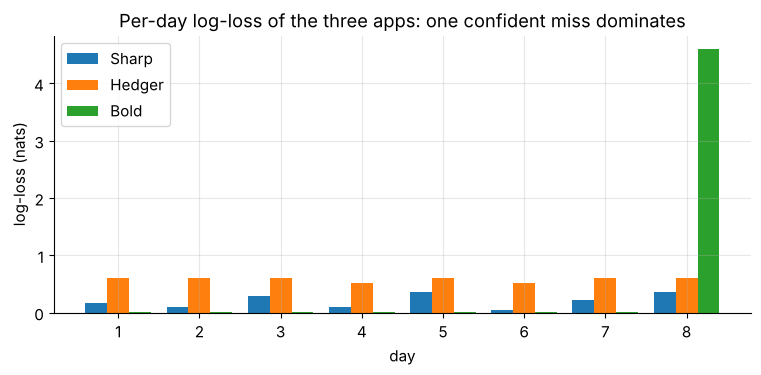

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
width = 0.27
for i, name in enumerate(forecasts):
    ax.bar(days.to_numpy() + (i - 1) * width, per_day[name], width, label=name)
ax.set_xticks(days.to_numpy())
ax.set_xlabel("day")
ax.set_ylabel("log-loss (nats)")
ax.set_title("Per-day log-loss of the three apps: one confident miss dominates")
ax.legend()
plt.show()

Read the table carefully:

* **Sharp vs Hedger.** Both have accuracy 1.0, but Sharp's mean log-loss (0.2061) is almost three times smaller than Hedger's (0.5761). Log-loss sees what accuracy cannot: Sharp was *confidently* right.
* **Bold.** On its seven correct days it pays only 0.0101 each, but day 8, a 99% promise of rain on a dry day, costs 4.6052, about 458 times the cost of one confident hit. That single day wipes out everything, and Bold ends with the *worst* mean log-loss (0.5844) despite 87.5% accuracy.

> **Key idea.** A probabilistic prediction should be scored by the probability it assigned to what *actually* happened. Taking $-\log$ of that probability gives a penalty that is near zero for confident correct predictions and explodes for confident wrong ones.

**Quick check.** What mean log-loss would an app get if it always announced exactly 50%? How does that compare with Hedger and Bold?

<details>
<summary>Answer</summary>

Every day it assigns probability 0.5 to whatever happens, so every day costs $-\log 0.5 = \log 2 \approx 0.6931$ nats, and so does the average. Hedger (0.5761) beats this coin-flip baseline only modestly, and Bold (0.5844) barely beats it despite its 87.5% accuracy.
</details>

## 2. A probability refresher

Everything in this notebook rests on a handful of probability ideas. If they are familiar, skim this section. If not, it contains everything you need.

### 2.1 Sample spaces, events and probability mass functions

* An **experiment** is any process with an uncertain outcome: tossing coins, tomorrow's weather, the label of the next photo in a dataset.
* The **sample space** $\Omega$ is the set of all possible outcomes. An **event** is a subset $A \subseteq \Omega$, for example "at least two heads".
* A **probability** $\mathbb{P}$ assigns a number to every event such that (i) $\mathbb{P}(A) \ge 0$, (ii) $\mathbb{P}(\Omega) = 1$, and (iii) $\mathbb{P}(A \cup B) = \mathbb{P}(A) + \mathbb{P}(B)$ whenever $A$ and $B$ cannot happen together.
* A **random variable** $Y$ is a summary of the outcome, such as "the number of heads".
* If $Y$ takes values in a finite set $\mathcal{Y}$, its **probability mass function (PMF)** is $p(y) = \mathbb{P}(Y = y)$. Every PMF satisfies

$$
p(y) \ge 0 \ \text{ for all } y \in \mathcal{Y}, \qquad \sum_{y \in \mathcal{Y}} p(y) = 1 .
$$

**Worked example.** Toss three fair coins. The sample space has $2^3 = 8$ equally likely outcomes (HHH, HHT, ..., TTT), each with probability $1/8$. Let $Y$ be the number of heads. Counting outcomes gives $p(0) = 1/8$ (only TTT), $p(1) = 3/8$ (HTT, THT, TTH), $p(2) = 3/8$ and $p(3) = 1/8$. Let us let the computer do the counting.

In [5]:
omega = ["".join(t) for t in itertools.product("HT", repeat=3)]   # all 8 outcomes
heads_count = Counter(outcome.count("H") for outcome in omega)     # how many outcomes give Y = k
pmf_heads = {k: heads_count[k] / len(omega) for k in sorted(heads_count)}

print("sample space:", omega)
print("PMF of Y = number of heads:", {k: round(v, 4) for k, v in pmf_heads.items()})
print("total probability:", sum(pmf_heads.values()))

sample space: ['HHH', 'HHT', 'HTH', 'HTT', 'THH', 'THT', 'TTH', 'TTT']
PMF of Y = number of heads: {0: 0.125, 1: 0.375, 2: 0.375, 3: 0.125}
total probability: 1.0


### 2.2 Expectation: a probability-weighted average

The **expectation** (mean) of $Y$ weights every value by its probability, and the same recipe works for any function $g$ of $Y$:

$$
\mathbb{E}[Y] = \sum_{y} y\, p(y), \qquad \mathbb{E}[g(Y)] = \sum_{y} g(y)\, p(y).
$$

For three coins: $\mathbb{E}[Y] = 0 \cdot \tfrac18 + 1 \cdot \tfrac38 + 2 \cdot \tfrac38 + 3 \cdot \tfrac18 = \tfrac{12}{8} = 1.5$. With $g(y) = y^2$ we get $\mathbb{E}[Y^2] = \tfrac{0 + 3 + 12 + 9}{8} = 3$, so the variance is $\mathbb{E}[Y^2] - \mathbb{E}[Y]^2 = 3 - 2.25 = 0.75$.

The **law of large numbers** says that if you repeat the experiment many times and average $g$ over the observed outcomes $y_1, \dots, y_N$, you approach the expectation: $\frac{1}{N}\sum_{i=1}^N g(y_i) \to \mathbb{E}[g(Y)]$.

> **Key idea.** Entropy, cross-entropy and KL divergence will all be expectations $\mathbb{E}[g(Y)]$ in which $g$ is a negative log-probability. And the average loss over a training set is a sample average, so it *estimates* such an expectation. Keep this translation in mind: "average over the data" means "expectation under the data distribution".

In [6]:
values = np.array(list(pmf_heads.keys()), dtype=float)
probs = np.array(list(pmf_heads.values()))
mean_Y = np.sum(values * probs)                  # E[Y]
second_moment = np.sum(values**2 * probs)        # E[g(Y)] with g(y) = y^2
var_Y = second_moment - mean_Y**2

samples = rng.integers(0, 2, size=(100_000, 3)).sum(axis=1)   # 100,000 rounds of three tosses
print(f"exact:      E[Y] = {mean_Y:.4f}, Var[Y] = {var_Y:.4f}")
print(f"simulation: mean = {samples.mean():.4f}, variance = {samples.var():.4f}  (law of large numbers)")

exact:      E[Y] = 1.5000, Var[Y] = 0.7500
simulation: mean = 1.5002, variance = 0.7487  (law of large numbers)


### 2.3 The Bernoulli distribution: one yes/no outcome

A **Bernoulli** random variable takes the value $1$ ("success", "positive class") with probability $\theta$ and $0$ with probability $1 - \theta$. Its PMF can be written in one line with an exponent trick:

$$
p(y) = \theta^{\,y}\,(1-\theta)^{\,1-y}, \qquad y \in \{0, 1\}.
$$

Plug in $y = 1$: the second factor becomes $(1-\theta)^0 = 1$ and we get $\theta$. Plug in $y = 0$: we get $1 - \theta$. The mean is $\mathbb{E}[Y] = \theta$ and the variance is $\theta(1-\theta)$. This one-line formula will turn into *binary cross-entropy* in Section 8.

Example: a basketball player who makes each free throw with probability $\theta = 0.72$. In machine learning, a binary classifier (spam or not, fraud or not) outputs an estimate of $\theta$ for each input.

In [7]:
theta = 0.72


def bernoulli_pmf(y, theta):
    """p(y) = theta^y * (1 - theta)^(1 - y) for y in {0, 1}."""
    return theta**y * (1 - theta) ** (1 - y)


print(f"p(1) = {bernoulli_pmf(1, theta):.2f},  p(0) = {bernoulli_pmf(0, theta):.2f}")
shots = rng.random(10_000) < theta                    # simulate 10,000 free throws
print(f"simulated success rate: {shots.mean():.4f}   (theta = {theta})")
print(f"simulated variance: {shots.var():.4f}   (theta(1 - theta) = {theta * (1 - theta):.4f})")

p(1) = 0.72,  p(0) = 0.28
simulated success rate: 0.7122   (theta = 0.72)
simulated variance: 0.2050   (theta(1 - theta) = 0.2016)


### 2.4 The categorical distribution and one-hot vectors

A **categorical** random variable takes one of $K$ values (classes) $\{1, \dots, K\}$ with probabilities $\boldsymbol\pi = (\pi_1, \dots, \pi_K)$. The vector $\boldsymbol\pi$ must live in the **probability simplex**

$$
\Delta^{K-1} = \Big\{ \boldsymbol\pi \in \mathbb{R}^K : \pi_k \ge 0, \ \sum_{k=1}^K \pi_k = 1 \Big\}.
$$

Multi-class classifiers (digit 0 to 9, which animal, which word comes next) output a point of this simplex for every input.

A **one-hot vector** $\mathbf{y} \in \{0,1\}^K$ encodes class $c$ as a $1$ in position $c$ and $0$ everywhere else. One-hot vectors give the categorical PMF the same exponent trick as the Bernoulli:

$$
\mathbb{P}(Y = c) = \prod_{k=1}^{K} \pi_k^{\,y_k} \qquad (\text{every factor is } 1 \text{ except } \pi_c^{\,1}).
$$

There is a second, deeper way to read a one-hot vector: it *is* a categorical distribution, one that puts all its probability on a single class. A labeled training example "this photo is class $c$" says that the true distribution for that photo is the one-hot vector $\mathbf{y}$. Comparing the model's distribution $\mathbf{q}$ with this one-hot distribution $\mathbf{y}$ is exactly what cross-entropy will do.

Example: how students get to school, with classes walk, bike, bus, car and $\boldsymbol\pi = (0.35, 0.15, 0.40, 0.10)$. In code, classes are indexed from $0$, so "bus" is class $2$.

In [8]:
modes = ["walk", "bike", "bus", "car"]
pi = np.array([0.35, 0.15, 0.40, 0.10])
draws = rng.choice(len(modes), size=10_000, p=pi)                  # 10,000 random students
freq = np.bincount(draws, minlength=len(modes)) / len(draws)
display(pd.DataFrame({"pi (true)": pi, "empirical frequency": freq}, index=modes).round(4))

labels = np.array([2, 0, 3, 2, 1])            # five students: bus, walk, car, bus, bike
onehot = np.eye(len(modes))[labels]           # row i is the one-hot vector of labels[i]
display(pd.DataFrame(onehot.astype(int), columns=modes, index=[f"student {i + 1}" for i in range(5)]))
print("P(bus) via prod(pi ** onehot):", np.prod(pi ** onehot[0]), "   pi[bus] =", pi[2])

,pi (true),empirical frequency
walk,0.35,0.3505
bike,0.15,0.1482
bus,0.40,0.3999
car,0.10,0.1014


,walk,bike,bus,car
student 1,0,0,1,0
student 2,1,0,0,0
student 3,0,0,0,1
student 4,0,0,1,0
student 5,0,1,0,0


P(bus) via prod(pi ** onehot): 0.4    pi[bus] = 0.4


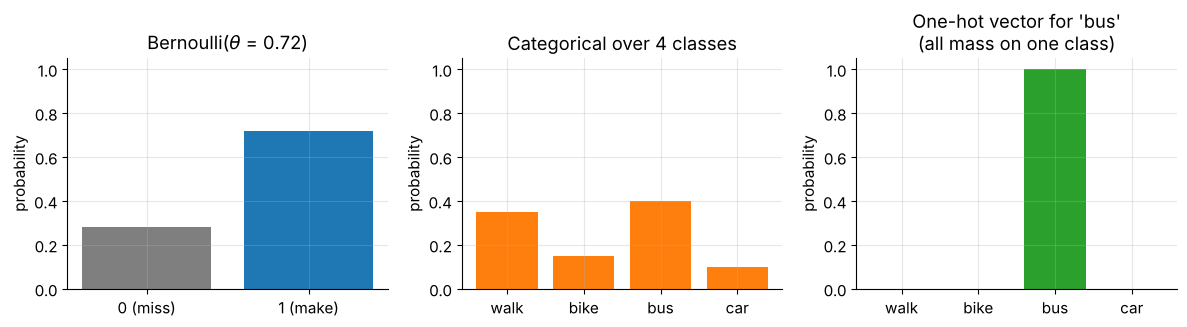

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].bar(["0 (miss)", "1 (make)"], [1 - theta, theta], color=["tab:gray", "tab:blue"])
axes[0].set_title(f"Bernoulli($\\theta$ = {theta})")
axes[1].bar(modes, pi, color="tab:orange")
axes[1].set_title("Categorical over 4 classes")
axes[2].bar(modes, onehot[0], color="tab:green")
axes[2].set_title("One-hot vector for 'bus'\n(all mass on one class)")
for ax in axes:
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("probability")
fig.tight_layout()
plt.show()

**Quick check.** Which of these are valid PMFs over three classes: (a) $(0.2, 0.5, 0.3)$, (b) $(0.6, 0.6, -0.2)$, (c) $(0.25, 0.25, 0.25)$?

<details>
<summary>Answer</summary>

Only (a). Vector (b) sums to 1 but contains a negative entry, and (c) is non-negative but sums to 0.75. Both conditions (non-negativity *and* summing to one) are required.
</details>

### ✏️ Exercise 1: one-hot encoding

Write `one_hot(labels, num_classes)` that turns an integer array of class indices (values in $0, \dots, K-1$) into an $(N, K)$ float array with a single $1$ per row. Try to avoid Python loops.

In [10]:
# ✏️ Exercise 1: one-hot encoding
def one_hot(labels, num_classes):
    """Return an (N, num_classes) float array whose row i is the one-hot vector of labels[i]."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex1():
    out = one_hot(np.array([2, 0, 1, 2]), 3)
    assert isinstance(out, np.ndarray), "return a NumPy array"
    assert out.shape == (4, 3), f"expected shape (4, 3), got {out.shape}"
    expected = [[0, 0, 1], [1, 0, 0], [0, 1, 0], [0, 0, 1]]
    assert np.array_equal(out, expected), f"got\n{out}"
    assert np.issubdtype(out.dtype, np.floating), "use a float dtype (losses multiply it with logs)"
    single = one_hot(np.array([4]), 6)
    assert single.tolist() == [[0, 0, 0, 0, 1, 0]], f"got {single.tolist()}"
    big = one_hot(np.arange(10) % 4, 4)
    assert np.allclose(big.sum(axis=1), 1) and np.allclose(big.argmax(axis=1), np.arange(10) % 4)


run_check("Exercise 1", _test_ex1)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def one_hot(labels, num_classes):
    labels = np.asarray(labels)
    out = np.zeros((len(labels), num_classes))
    out[np.arange(len(labels)), labels] = 1.0   # fancy indexing: row i, column labels[i]
    return out
```
Fancy indexing with the pair of arrays `(np.arange(N), labels)` selects exactly one cell per row. An equivalent one-liner is `np.eye(num_classes)[labels]`, which picks rows of the identity matrix.
</details>

## 3. Logarithms: the workhorse

Logarithms appear in every formula of this notebook, for three reasons:

1. they turn **products into sums**, and probabilities of independent events multiply,
2. they keep computations **numerically safe** (products of many probabilities underflow, sums of logs do not),
3. $-\log p$ is a natural **penalty**: zero for a certain event, unbounded for an "impossible" one.

### 3.1 Definition, bases and units

For $a > 0$ and a base $b > 0$, $b \ne 1$:

$$
\log_b a = x \iff b^{x} = a .
$$

For example $\log_2 32 = 5$ because $2^5 = 32$, $\log_{10} 0.001 = -3$, and $\log e^{4} = 4$. In information theory the base only fixes the **unit**: base $2$ measures information in **bits**, base $e$ in **nats** (base $10$ gives *hartleys*, rarely used). Machine-learning libraries always use base $e$, so a loss printed by PyTorch is in nats.

**Change of base.** Let $x = \log_b a$, so $b^x = a$. Taking the natural log of both sides gives $x \log b = \log a$, hence

$$
\log_b a = \frac{\log a}{\log b}.
$$

So two bases differ only by a constant factor: $\log_2 a = \log a / \log 2 \approx 1.4427 \log a$. In other words, $1$ nat $\approx 1.4427$ bits and $1$ bit $= \log 2 \approx 0.6931$ nats.

The rules we will use constantly (the first four hold in any base, and the monotone rule needs a base larger than $1$, such as $2$, $e$ or $10$):

| Rule | Formula | Where it shows up |
|---|---|---|
| product | $\log(ab) = \log a + \log b$ | likelihoods of independent events become sums |
| quotient | $\log(a/b) = \log a - \log b$ | KL divergence is an average log-ratio |
| power | $\log(a^{k}) = k \log a$ | the exponent trick in the Bernoulli/categorical PMF becomes a weighted sum |
| one | $\log 1 = 0$ | a certain event carries no information |
| monotone | $a < b \iff \log a < \log b$ | maximizing a likelihood is the same as maximizing its log |

In [11]:
p_vals = np.array([0.8, 0.5, 0.125, 0.02])
log_table = pd.DataFrame({
    "p": p_vals,
    "ln p (nats)": np.log(p_vals),
    "log2 p (bits)": np.log2(p_vals),
    "log10 p": np.log10(p_vals),
    "ln p / ln 2": np.log(p_vals) / np.log(2),
})
display(log_table.round(4))
print("change of base holds:", np.allclose(np.log2(p_vals), np.log(p_vals) / np.log(2)))
print(f"1 nat = {1 / np.log(2):.4f} bits,   1 bit = {np.log(2):.4f} nats")

,p,ln p (nats),log2 p (bits),log10 p,ln p / ln 2
0,0.800,-0.2231,-0.3219,-0.0969,-0.3219
1,0.500,-0.6931,-1.0000,-0.3010,-1.0000
2,0.125,-2.0794,-3.0000,-0.9031,-3.0000
3,0.020,-3.9120,-5.6439,-1.6990,-5.6439


change of base holds: True
1 nat = 1.4427 bits,   1 bit = 0.6931 nats


### 3.2 The shape of the logarithm and one key inequality

On $(0, 1)$ the logarithm is negative, it equals $0$ at $1$, and it dives to $-\infty$ as $p \to 0^{+}$. It is also **concave** (it bends downward), so it always lies below each of its tangent lines. The tangent at $x = 1$ is the line $x - 1$, which gives an inequality we will use to prove that KL divergence is never negative:

$$
\log x \le x - 1 \quad \text{for all } x > 0, \qquad \text{with equality only at } x = 1 .
$$

*Proof.* Let $f(x) = x - 1 - \log x$. Then $f'(x) = 1 - 1/x$, which is negative on $(0, 1)$ and positive on $(1, \infty)$, so $f$ decreases and then increases, with its global minimum at $x = 1$ where $f(1) = 0$. Therefore $f(x) \ge 0$ everywhere, with equality only at $x = 1$, which is exactly the claim.

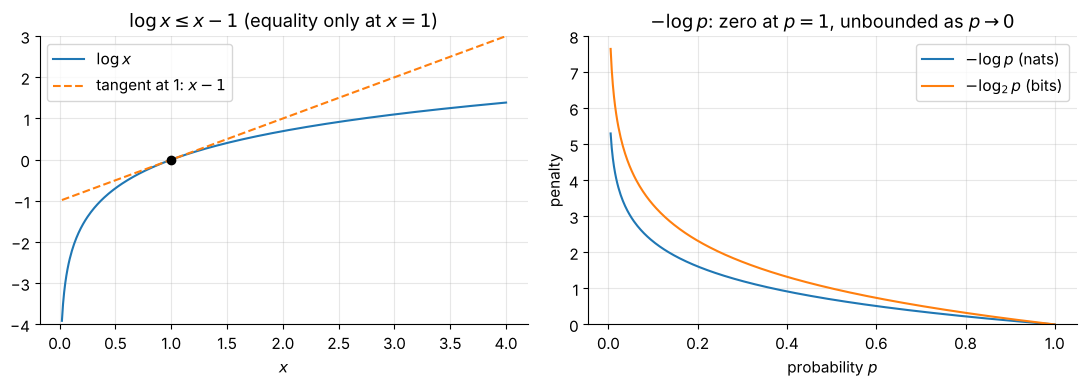

In [12]:
x = np.linspace(0.02, 4, 400)
p = np.linspace(0.005, 1, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(x, np.log(x), label="$\\log x$")
axes[0].plot(x, x - 1, "--", label="tangent at 1: $x - 1$")
axes[0].plot(1, 0, "ko")
axes[0].set_ylim(-4, 3)
axes[0].set_xlabel("$x$")
axes[0].set_title("$\\log x \\leq x - 1$ (equality only at $x = 1$)")
axes[0].legend()
axes[1].plot(p, -np.log(p), label="$-\\log p$ (nats)")
axes[1].plot(p, -np.log2(p), label="$-\\log_2 p$ (bits)")
axes[1].set_ylim(0, 8)
axes[1].set_xlabel("probability $p$")
axes[1].set_ylabel("penalty")
axes[1].set_title("$-\\log p$: zero at $p = 1$, unbounded as $p \\to 0$")
axes[1].legend()
fig.tight_layout()
plt.show()

### 3.3 From products to sums: why we never multiply many probabilities

The probability that independent events *all* happen is the product of their probabilities. A language model that reads a document assigns each actual token a probability below $1$, so the probability of the whole document shrinks exponentially with its length. Computers store real numbers as floating-point values, and those cannot be arbitrarily small: in `float64` anything below about $5 \times 10^{-324}$ rounds to exactly $0$ (in `float32` the limit is about $1.4 \times 10^{-45}$). This silent rounding to zero is called **underflow**.

How many factors of $0.1$ does it take to hit zero?

In [13]:
for dtype in (np.float64, np.float32):
    value, n_mult = dtype(1.0), 0
    while value > 0:
        value = dtype(value * dtype(0.1))
        n_mult += 1
    print(f"{dtype.__name__}: 0.1 multiplied {n_mult} times is exactly 0.0 "
          f"(smallest positive value ~ {np.finfo(dtype).smallest_subnormal:.1e})")

float64: 0.1 multiplied 324 times is exactly 0.0 (smallest positive value ~ 4.9e-324)
float32: 0.1 multiplied 46 times is exactly 0.0 (smallest positive value ~ 1.4e-45)


Now a realistic case. Two language models read the same 2,000-token text. Below are the probabilities each model gave to every token that actually appeared (simulated here). Which model explains the text better? The direct product cannot tell us, but the sum of logs can, because $\log \prod_i p_i = \sum_i \log p_i$.

In [14]:
n_tokens = 2_000
probs_A = rng.uniform(0.02, 0.60, size=n_tokens)   # probability model A gave each actual token
probs_B = rng.uniform(0.05, 0.60, size=n_tokens)   # model B is slightly better on average

print("direct product, model A:", np.prod(probs_A))
print("direct product, model B:", np.prod(probs_B))
logL_A, logL_B = np.sum(np.log(probs_A)), np.sum(np.log(probs_B))
print(f"log-likelihood (sum of logs): A = {logL_A:.2f}, B = {logL_B:.2f}")
gap = logL_B - logL_A
print(f"B gives the text e^{gap:.1f} = 10^{gap / np.log(10):.1f} times more probability than A")

direct product, model A: 0.0
direct product, model B: 0.0
log-likelihood (sum of logs): A = -2803.96, B = -2572.66
B gives the text e^231.3 = 10^100.5 times more probability than A


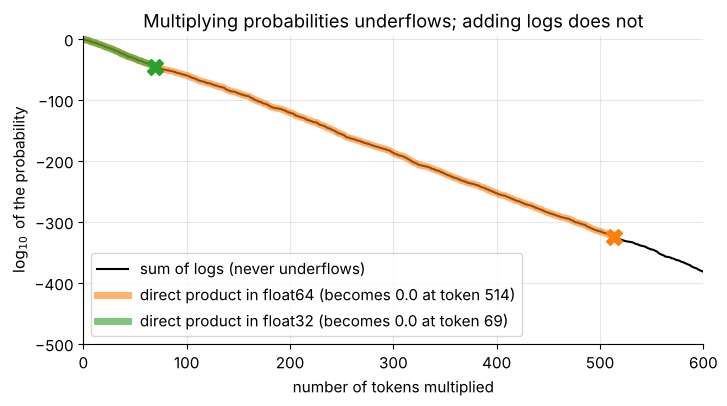

In [15]:
steps = np.arange(1, n_tokens + 1)
exact_log10 = np.cumsum(np.log10(probs_A))          # log10 of the running product, computed safely
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(steps, exact_log10, color="black", lw=1.5, label="sum of logs (never underflows)")
for dtype, color in [(np.float64, "tab:orange"), (np.float32, "tab:green")]:
    running = np.cumprod(probs_A.astype(dtype))     # the naive running product
    alive = running > 0
    first_zero = int(np.argmin(alive)) + 1          # first token at which the product is 0.0
    ax.plot(steps[alive], np.log10(running[alive]), color=color, lw=5, alpha=0.6,
            label=f"direct product in {dtype.__name__} (becomes 0.0 at token {first_zero})")
    ax.plot(first_zero, exact_log10[first_zero - 1], "X", color=color, ms=12)
ax.set_xlim(0, 600)
ax.set_ylim(-500, 5)
ax.set_xlabel("number of tokens multiplied")
ax.set_ylabel("$\\log_{10}$ of the probability")
ax.set_title("Multiplying probabilities underflows, but adding logs does not")
ax.legend(loc="lower left")
plt.show()

> **Key idea.** Never multiply long chains of probabilities. Work with **log-probabilities** and add them. Every ML library does this internally, which is one reason losses are written with logs.

### 3.4 $-\log p$ as a penalty

If a model gives probability $p$ to the outcome that actually happened, a natural penalty is $-\log p$:

In [16]:
p_tab = np.array([0.999, 0.95, 0.75, 0.5, 0.25, 0.05, 0.001])
display(pd.DataFrame({"p (prob. of what happened)": p_tab,
                      "-ln p (nats)": -np.log(p_tab),
                      "-log2 p (bits)": -np.log2(p_tab)}).round(4))

,p (prob. of what happened),-ln p (nats),-log2 p (bits)
0,0.999,0.0010,0.0014
1,0.950,0.0513,0.0740
2,0.750,0.2877,0.4150
3,0.500,0.6931,1.0000
4,0.250,1.3863,2.0000
5,0.050,2.9957,4.3219
6,0.001,6.9078,9.9658


Three features make this penalty special:

* **No penalty for certainty when right**: $-\log 1 = 0$, and $p = 0.999$ costs almost nothing.
* **Unbounded for confident mistakes**: as $p \to 0$, $-\log p \to \infty$. A model that called the actual outcome "one in a thousand" pays $6.91$ nats (almost $10$ bits).
* **It only cares about ratios**: halving the probability always adds the same amount, $\log 2 \approx 0.6931$ nats, i.e. exactly $1$ bit (compare the rows $p = 0.5$ and $p = 0.25$). Going from $0.8$ to $0.4$ hurts exactly as much as going from $0.002$ to $0.001$.

### 3.5 The log-sum-exp trick

Often we hold numbers only through their logarithms, $a_i = \log x_i$, and need the log of their *sum*, $\log \sum_i x_i = \log \sum_i e^{a_i}$. This happens when we add probabilities stored as log-probabilities, and it is the normalizing step of the softmax function (Section 9). The naive formula is fragile: in `float64`, $e^{a}$ overflows to `inf` once $a > 709.78$ and underflows to $0$ for $a$ below about $-745$.

The fix is an exact identity. For any constant $m$,

$$
\log \sum_{i=1}^{n} e^{a_i} = m + \log \sum_{i=1}^{n} e^{a_i - m},
$$

because $\sum_i e^{a_i} = e^{m} \sum_i e^{a_i - m}$ and $\log(e^m \cdot s) = m + \log s$. Choosing $m = \max_i a_i$ makes every exponent $a_i - m \le 0$ (so nothing overflows), and one term equals $e^{0} = 1$ (so the sum is at least $1$ and its log is never $\log 0$).

A bonus from the same identity: the inner sum lies between $1$ and $n$, so

$$
\max_i a_i \;\le\; \operatorname{LSE}(\mathbf{a}) \;\le\; \max_i a_i + \log n ,
$$

which is why log-sum-exp is often called a **smooth maximum**.

In [17]:
def logsumexp_naive(a):
    """log(sum(exp(a))) computed literally: overflows/underflows easily."""
    return np.log(np.sum(np.exp(a)))


def logsumexp_stable(a):
    """log(sum(exp(a))) for a 1-D array, using the max-shift identity."""
    a = np.asarray(a, dtype=float)
    m = np.max(a)
    return m + np.log(np.sum(np.exp(a - m)))


cases = {"moderate [1, 2, 3]": [1.0, 2.0, 3.0],
         "huge [1000, 1001, 1002]": [1000.0, 1001.0, 1002.0],
         "tiny [-1000, -1001, -1002]": [-1000.0, -1001.0, -1002.0]}
rows = []
for name, a in cases.items():
    a = np.array(a)
    with np.errstate(over="ignore", divide="ignore"):   # the naive version is *expected* to fail here
        naive = logsumexp_naive(a)
    rows.append({"input": name, "naive": naive, "stable (ours)": logsumexp_stable(a),
                 "scipy": special.logsumexp(a), "torch": torch.logsumexp(torch.tensor(a), dim=0).item()})
display(pd.DataFrame(rows).set_index("input").round(4))

a_rand = rng.normal(0, 5, size=(1000, 8))               # 1000 random vectors of length n = 8
lse = special.logsumexp(a_rand, axis=1)
mx = a_rand.max(axis=1)
print("max <= LSE <= max + log(n) for all 1000 vectors:",
      bool(np.all(mx <= lse) and np.all(lse <= mx + np.log(8))))
print("two-term version np.logaddexp(1000, 1000) =", np.logaddexp(1000.0, 1000.0), "= 1000 + ln 2")

,naive,stable (ours),scipy,torch
input,,,,
"moderate [1, 2, 3]",3.4076,3.4076,3.4076,3.4076
"huge [1000, 1001, 1002]",inf,1002.4076,1002.4076,1002.4076
"tiny [-1000, -1001, -1002]",-inf,-999.5924,-999.5924,-999.5924


max <= LSE <= max + log(n) for all 1000 vectors: True
two-term version np.logaddexp(1000, 1000) = 1000.6931471805599 = 1000 + ln 2


> **Common pitfall.** Computing `np.log(np.sum(np.exp(a)))` directly. It works on small textbook numbers and silently returns `inf` or `-inf` on real logits. Use `scipy.special.logsumexp`, `torch.logsumexp`, or the max-shift identity yourself.

**Quick check.** Without a calculator, estimate $\operatorname{LSE}(50, 50, 50, 50)$ and $\operatorname{LSE}(50, 0)$.

<details>
<summary>Answer</summary>

$\operatorname{LSE}(50,50,50,50) = 50 + \log 4 \approx 51.386$ (four equal terms, so exactly the upper bound $\max + \log n$). $\operatorname{LSE}(50, 0) = 50 + \log(1 + e^{-50}) \approx 50$, because $e^{-50}$ is negligible: the soft maximum is essentially the maximum when one entry dominates.
</details>

### ✏️ Exercise 2: log-sum-exp along an axis

Real code applies log-sum-exp to every row of a matrix of scores at once. Write `logsumexp_axis(a, axis=-1)` that reduces along the given axis of an array of any shape, without overflow or underflow, and returns an array with that axis removed. Hint: `np.max(..., keepdims=True)` keeps the reduced axis so the subtraction broadcasts.

In [18]:
# ✏️ Exercise 2: stable log-sum-exp along an axis
def logsumexp_axis(a, axis=-1):
    """Return log(sum(exp(a), axis=axis)) computed stably. The reduced axis is removed."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex2():
    a = np.array([[1000.0, 1001.0, 1002.0], [-1000.0, -1001.0, -1002.0], [0.0, 0.0, 0.0]])
    out = logsumexp_axis(a, axis=-1)
    assert np.shape(out) == (3,), f"expected shape (3,), got {np.shape(out)}"
    assert np.all(np.isfinite(out)), f"outputs must be finite (did you subtract the max?), got {out}"
    assert np.allclose(out, [1002.40760596, -999.59239404, np.log(3)]), f"got {out}"
    out0 = logsumexp_axis(a, axis=0)
    assert np.allclose(out0, special.logsumexp(a, axis=0)), f"axis=0 is wrong: got {out0}"
    t_rng = np.random.default_rng(0)                   # local RNG: never touch the global one
    b = t_rng.normal(0, 300, size=(4, 5, 6))
    for ax in (0, 1, 2, -1):
        assert np.allclose(logsumexp_axis(b, axis=ax), special.logsumexp(b, axis=ax)), f"axis={ax} is wrong"


run_check("Exercise 2", _test_ex2)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def logsumexp_axis(a, axis=-1):
    a = np.asarray(a, dtype=float)
    m = np.max(a, axis=axis, keepdims=True)              # shape with the axis kept (size 1)
    s = np.sum(np.exp(a - m), axis=axis, keepdims=True)  # every exponent is <= 0
    return np.squeeze(m + np.log(s), axis=axis)          # drop the reduced axis
```
Keeping the reduced axis makes `a - m` broadcast correctly for any `axis`, and squeezing at the end returns the expected shape.
</details>

## 4. Surprisal: how surprising is an outcome?

### 4.1 Intuition and definition

"The sun rose this morning" is not news. "It snowed in the desert" is. The less probable an outcome, the more you learn when you find out it happened. Information theory turns this into a number. The **surprisal** (also called *information content* or *self-information*) of an outcome $y$ that had probability $p(y)$ is

$$
I(y) = -\log p(y) = \log \frac{1}{p(y)} ,
$$

measured in bits with $\log_2$ and in nats with $\log$. It is exactly the penalty $-\log p$ of Section 3.4, now read as "amount of news".

**Bits as yes/no questions.** Suppose a friend picks one of $2^n$ equally likely options and you identify it with yes/no questions. Each well-chosen question ("is it in the first half?") halves the candidates, so you need exactly $n$ questions, and the surprisal of the pick is $\log_2 2^n = n$ bits. One bit is the information in the answer to one fair yes/no question.

In [19]:
def surprisal(p, base=2.0):
    """Information content -log_base(p) of an outcome that had probability p (default: bits)."""
    return -np.log(p) / np.log(base)


events = {   # description: (probability, printable probability)
    "fair coin lands heads": (1 / 2, "1/2"),
    "fair die shows a 6": (1 / 6, "1/6"),
    "a stranger's birthday is today": (1 / 365, "1/365"),
    "you guess a 4-digit PIN in one try": (1 / 10_000, "1/10,000"),
    "a one-in-a-million event": (1e-6, "1/1,000,000"),
}
display(pd.DataFrame({
    "probability": [label for _, label in events.values()],
    "surprisal (bits)": [surprisal(p) for p, _ in events.values()],
    "surprisal (nats)": [surprisal(p, np.e) for p, _ in events.values()],
}, index=list(events)).round(4))

,probability,surprisal (bits),surprisal (nats)
fair coin lands heads,1/2,1.0000,0.6931
fair die shows a 6,1/6,2.5850,1.7918
a stranger's birthday is today,1/365,8.5118,5.8999
you guess a 4-digit PIN in one try,"1/10,000",13.2877,9.2103
a one-in-a-million event,"1/1,000,000",19.9316,13.8155


### 4.2 Why a logarithm? (It is forced on us.)

Is $-\log p$ just a convenient choice? No. Write down what any reasonable "information" function $f(p)$ of a probability should satisfy:

1. **Certain events tell us nothing:** $f(1) = 0$.
2. **Rarer means more informative:** $f$ is continuous and decreasing on $(0, 1]$.
3. **Independent news adds up:** if two independent events with probabilities $p$ and $q$ both happen (joint probability $pq$), the information is the sum, $f(pq) = f(p) + f(q)$.

**Claim.** The only functions with these properties are $f(p) = -c \log p$ with a constant $c > 0$, that is, logarithms in some base.

*Proof sketch.* Substitute $p = e^{-s}$ and define $g(s) = f(e^{-s})$ for $s \ge 0$. Requirement 3 becomes **Cauchy's functional equation** $g(s + t) = g(s) + g(t)$.

* By induction, $g(n s) = n\, g(s)$ for every positive integer $n$.
* For integers $m, n \ge 1$: $g(1) = g(n \cdot \tfrac1n) = n\, g(\tfrac1n)$, so $g(\tfrac1n) = \tfrac{g(1)}{n}$ and $g(\tfrac mn) = m\, g(\tfrac1n) = \tfrac mn\, g(1)$. Hence $g(r) = c\, r$ for every positive rational $r$, with $c = g(1)$.
* Every real $s \ge 0$ is a limit of rationals, so continuity gives $g(s) = c\, s$ for all $s \ge 0$.

Translating back, $f(p) = g(-\log p) = -c \log p$, and "decreasing" forces $c > 0$. The constant only picks the unit: $c = 1$ gives nats and $c = 1/\log 2$ gives bits. So the logarithm is the *unique* way to measure information additively.

> **Olympiad tip.** Cauchy's equation $g(s+t) = g(s) + g(t)$ is a classic of olympiad algebra. On its own it has bizarre non-linear solutions, but one mild regularity condition (continuity, monotonicity, or boundedness on an interval) rules them out and forces $g(s) = c\,s$. Here requirement 2 supplies that condition.

Let us check additivity numerically for "the coin shows heads **and** the die shows 6" (independent, joint probability $\tfrac12 \cdot \tfrac16 = \tfrac{1}{12}$), and see two plausible-looking alternatives fail.

In [20]:
p_coin, p_die = 1 / 2, 1 / 6
both = p_coin * p_die                                   # independence: probabilities multiply
candidates = {"-log2 p": surprisal, "1 - p": lambda p: 1 - p, "1 / p": lambda p: 1 / p}
for name, f in candidates.items():
    print(f"f(p) = {name:>8}:  f(joint) = {f(both):8.4f}   f(p_coin) + f(p_die) = {f(p_coin) + f(p_die):8.4f}")

f(p) =  -log2 p:  f(joint) =   3.5850   f(p_coin) + f(p_die) =   3.5850
f(p) =    1 - p:  f(joint) =   0.9167   f(p_coin) + f(p_die) =   1.3333
f(p) =    1 / p:  f(joint) =  12.0000   f(p_coin) + f(p_die) =   8.0000


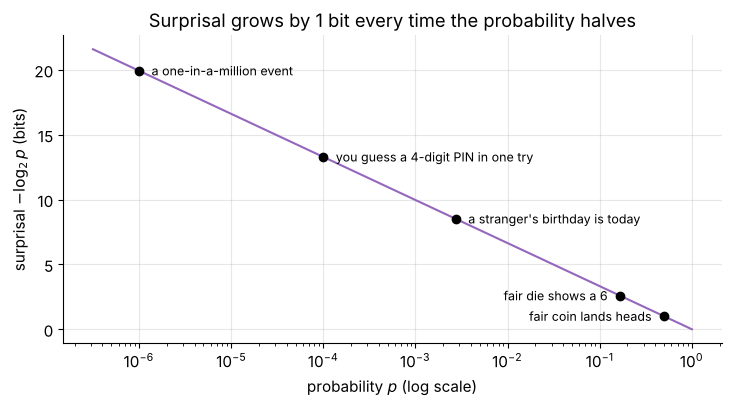

In [21]:
p_grid = np.logspace(-6.5, 0, 400)
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(p_grid, surprisal(p_grid), color="tab:purple")
for desc, (p_ev, _) in events.items():
    ax.plot(p_ev, surprisal(p_ev), "o", color="black")
    right_side = p_ev < 0.01                     # label frequent events on the left, rare ones on the right
    ax.annotate(desc, (p_ev, surprisal(p_ev)), xytext=(9 if right_side else -9, 0), textcoords="offset points",
                fontsize=9, va="center", ha="left" if right_side else "right")
ax.set_xscale("log")
ax.set_xlabel("probability $p$ (log scale)")
ax.set_ylabel("surprisal $-\\log_2 p$ (bits)")
ax.set_title("Surprisal grows by 1 bit every time the probability halves")
plt.show()

On a logarithmic probability axis, surprisal is a straight line: every factor of $2$ in rarity adds one bit, every factor of $10$ adds $\log_2 10 \approx 3.32$ bits.

**Quick check.** (a) An outcome has probability $1/1024$. What is its surprisal in bits? (b) Two independent events have surprisals of 3 bits and 4 bits. What is the probability that both happen?

<details>
<summary>Answer</summary>

(a) $\log_2 1024 = 10$ bits. (b) Surprisals add for independent events, so the joint surprisal is $7$ bits, i.e. probability $2^{-7} = 1/128$. Check: $2^{-3} \cdot 2^{-4} = 2^{-7}$.
</details>

## 5. Entropy: average surprise

Surprisal scores *one* outcome. Before the outcome is revealed, though, we can ask a different question: **how surprised should I expect to be?** That expected surprisal is the entropy, the single most important number in information theory.

### 5.1 Intuition: which jar is harder to guess?

Two jars each hold 16 jelly beans:

* **Jar A:** 4 cherry, 4 lemon, 4 lime, 4 grape.
* **Jar B:** 13 cherry, 1 lemon, 1 lime, 1 grape.

You draw one bean blindfolded and must announce its flavor before looking. With jar B you say "cherry" and you are right 13 times out of 16 (about 81%). With jar A no guess is better than another, and you are right only 25% of the time. Jar A is clearly *more uncertain*.

How do we put a number on "more uncertain"? The probability of the best guess is one option, but it ignores everything except the top flavor. Surprisal suggests a better idea: average the surprisal over all the beans you might draw, weighting each flavor by how often it comes out.

* **Jar A.** Each flavor has probability $1/4$, hence surprisal $\log_2 4 = 2$ bits. Every draw is equally surprising, so the average is **2 bits**.
* **Jar B.** Cherry has surprisal $\log_2(16/13) \approx 0.2996$ bits (barely news), and each of the three rare flavors has $\log_2 16 = 4$ bits (big news, but rare). The average is $\tfrac{13}{16}(0.2996) + 3 \cdot \tfrac{1}{16}(4) \approx 0.2434 + 0.75 = 0.9934$ bits.

Jar B's draws are *usually* unsurprising, and its rare surprises do not happen often enough to make up for that. So on average jar B carries less than half the uncertainty of jar A.

In [22]:
flavors = ["cherry", "lemon", "lime", "grape"]
jar_counts = {"A": np.array([4, 4, 4, 4]), "B": np.array([13, 1, 1, 1])}

rows = {}
for jar, counts in jar_counts.items():
    p_jar = counts / counts.sum()
    rows[(jar, "p")] = p_jar
    rows[(jar, "surprisal (bits)")] = -np.log2(p_jar)
    rows[(jar, "p x surprisal")] = p_jar * -np.log2(p_jar)
display(pd.DataFrame(rows, index=flavors).round(4))

for jar, counts in jar_counts.items():
    p_jar = counts / counts.sum()
    exact = np.sum(p_jar * -np.log2(p_jar))
    beans = rng.choice(4, size=20_000, p=p_jar)        # 20,000 blindfolded draws
    simulated = np.mean(-np.log2(p_jar[beans]))        # average surprisal actually experienced
    print(f"jar {jar}: expected surprisal = {exact:.4f} bits | average over 20,000 draws = {simulated:.4f} bits")

A                                      B                   \
           p surprisal (bits) p x surprisal       p surprisal (bits)   
cherry  0.25              2.0           0.5  0.8125           0.2996   
lemon   0.25              2.0           0.5  0.0625           4.0000   
lime    0.25              2.0           0.5  0.0625           4.0000   
grape   0.25              2.0           0.5  0.0625           4.0000   

                      
       p x surprisal  
cherry        0.2434  
lemon         0.2500  
lime          0.2500  
grape         0.2500

jar A: expected surprisal = 2.0000 bits | average over 20,000 draws = 2.0000 bits
jar B: expected surprisal = 0.9934 bits | average over 20,000 draws = 0.9964 bits


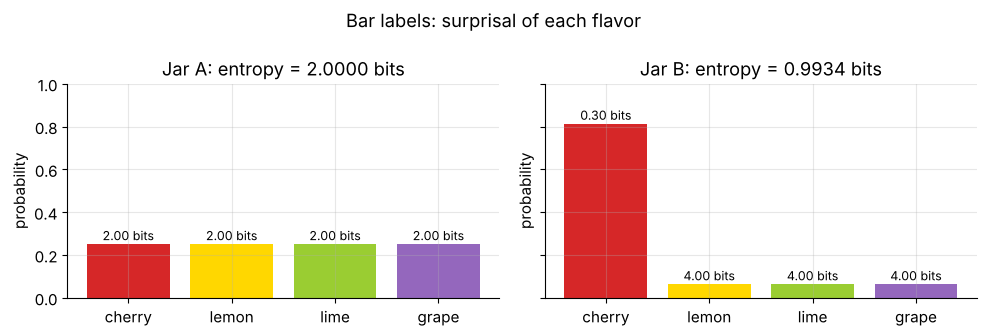

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, (jar, counts) in zip(axes, jar_counts.items()):
    p_jar = counts / counts.sum()
    bars = ax.bar(flavors, p_jar, color=["tab:red", "gold", "yellowgreen", "tab:purple"])
    for bar, s in zip(bars, -np.log2(p_jar)):
        ax.annotate(f"{s:.2f} bits", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
    ax.set_title(f"Jar {jar}: entropy = {np.sum(p_jar * -np.log2(p_jar)):.4f} bits")
    ax.set_ylabel("probability")
    ax.set_ylim(0, 1)
fig.suptitle("Bar labels: surprisal of each flavor")
fig.tight_layout()
plt.show()

**A second reading: the guessing game.** Suppose that instead of guessing once, you must *identify* the flavor by asking yes/no questions. For jar A, two questions always suffice ("cherry or lemon?", then one more). For jar B the smart strategy is lopsided:

| Strategy for jar B | Flavor found | Questions used | Probability |
|---|---|---|---|
| "Is it cherry?" yes | cherry | 1 | $13/16$ |
| "Is it cherry?" no, "Is it lemon?" yes | lemon | 2 | $1/16$ |
| ... then "Is it lime?" yes / no | lime / grape | 3 | $2/16$ |

Expected number of questions: $\tfrac{13}{16} \cdot 1 + \tfrac{1}{16} \cdot 2 + \tfrac{2}{16} \cdot 3 = \tfrac{21}{16} = 1.3125$. That is more than the entropy $0.9934$, because one draw cannot be identified with a fraction of a question. In Section 5.6 we will see that if you identify *many* beans at once, the number of questions per bean can be pushed down toward $0.9934$, but never below it. Entropy is the exact price of identifying an outcome, in the long run.

### 5.2 Definition

The **entropy** of a discrete distribution $P$ with PMF $p$ over a finite set $\mathcal{Y}$ is its expected surprisal:

$$
H(P) \;=\; \mathbb{E}_{Y \sim P}\big[-\log p(Y)\big] \;=\; \sum_{y \in \mathcal{Y}} p(y)\,\big(-\log p(y)\big) \;=\; -\sum_{y \in \mathcal{Y}} p(y) \log p(y).
$$

Read the middle form slowly: for every outcome, *how often it happens* $p(y)$ times *how surprising it is when it happens* $-\log p(y)$, summed. The minus sign is there only because $\log p(y) \le 0$, and it makes entropy a non-negative number. With $\log_2$ the unit is bits, with the natural log it is nats, and $H_{\text{bits}} = H_{\text{nats}} / \log 2$. We also write $H(Y)$ for the entropy of the distribution of a random variable $Y$.

**The convention $0 \log 0 = 0$.** If $p(y) = 0$, the term $p(y)\log p(y)$ is $0 \cdot (-\infty)$, which is undefined. We set it to $0$, for two good reasons:

1. *Meaning:* an outcome that never happens never surprises you, so it cannot contribute to the *average* surprise.
2. *Continuity:* $\lim_{p \to 0^+} p \log p = 0$. Substitute $p = e^{-t}$ with $t \to \infty$: then $p \log p = -t\,e^{-t} \to 0$, because the exponential decay beats the linear growth of $t$.

Adding an impossible outcome to the list therefore never changes the entropy.

In [24]:
def entropy(p, base=np.e):
    """Entropy of a discrete distribution p (1-D array that sums to 1), in units set by `base`.

    Uses the convention 0 * log(0) = 0 by skipping outcomes with probability zero.
    """
    p = np.asarray(p, dtype=float)
    nz = p > 0
    return -np.sum(p[nz] * np.log(p[nz])) / np.log(base)


p_demo = np.array([0.5, 0.5, 0.0])             # an impossible third outcome
with np.errstate(divide="ignore", invalid="ignore"):   # the naive formula is expected to fail
    naive = -np.sum(p_demo * np.log(p_demo))
print("naive -sum(p*log p):", naive, "  <- 0 * log(0) = 0 * (-inf) = nan")
print("entropy() with the convention:", entropy(p_demo, base=2), "bit")
print("scipy.stats.entropy:", stats.entropy(p_demo, base=2), "bit")
print("scipy.special.entr (computes -p log p elementwise, entr(0) = 0):", special.entr(p_demo).sum() / np.log(2), "bit")
for t in (0.1, 0.001, 1e-6):
    print(f"p = {t:<6}: p * log p = {t * np.log(t):.6f}   (tends to 0)")

naive -sum(p*log p): nan   <- 0 * log(0) = 0 * (-inf) = nan
entropy() with the convention: 1.0 bit
scipy.stats.entropy: 1.0 bit
scipy.special.entr (computes -p log p elementwise, entr(0) = 0): 1.0 bit
p = 0.1   : p * log p = -0.230259   (tends to 0)
p = 0.001 : p * log p = -0.006908   (tends to 0)
p = 1e-06 : p * log p = -0.000014   (tends to 0)


> **Common pitfall.** Writing `-np.sum(p * np.log(p))` for entropy. It returns `nan` as soon as one probability is exactly zero (which happens all the time with one-hot vectors and sparse counts). Mask out the zeros, or use `scipy.special.entr`, `scipy.special.xlogy`, or `scipy.stats.entropy`.

### 5.3 A worked example by hand

A remote weather station radios one of four reports each day, with these long-run frequencies:

| report $y$ | $p(y)$ | surprisal $-\log_2 p(y)$ | contribution $p(y)\cdot(-\log_2 p(y))$ |
|---|---|---|---|
| sunny | $1/2$ | $1$ | $0.5$ |
| cloudy | $1/4$ | $2$ | $0.5$ |
| rain | $1/8$ | $3$ | $0.375$ |
| storm | $1/8$ | $3$ | $0.375$ |
| **total** | $1$ | | $H(P) = 1.75$ bits |

In nats the same entropy is $1.75 \times \log 2 \approx 1.2130$ nats. Notice that the probabilities are powers of $1/2$, so every surprisal is a whole number of bits. Keep this source in mind: we will reuse it for codes, cross-entropy and KL divergence.

In [25]:
reports = ["sunny", "cloudy", "rain", "storm"]
P_weather = np.array([1 / 2, 1 / 4, 1 / 8, 1 / 8])

display(pd.DataFrame({"p": P_weather,
                      "surprisal (bits)": -np.log2(P_weather),
                      "contribution (bits)": P_weather * -np.log2(P_weather)}, index=reports))
print(f"H(P) = {entropy(P_weather, base=2):.4f} bits = {entropy(P_weather):.4f} nats "
      f"(scipy: {stats.entropy(P_weather, base=2):.4f} bits)")

,p,surprisal (bits),contribution (bits)
sunny,0.500,1.0,0.500
cloudy,0.250,2.0,0.500
rain,0.125,3.0,0.375
storm,0.125,3.0,0.375


H(P) = 1.7500 bits = 1.2130 nats (scipy: 1.7500 bits)


### 5.4 Properties of entropy

Let $P$ be a distribution over $K$ outcomes.

**1. Entropy is never negative, and it is zero exactly for certainty.** Every term $-p \log p$ is $\ge 0$ when $0 \le p \le 1$, and it equals $0$ only if $p = 0$ or $p = 1$. So $H(P) = 0$ if and only if one outcome has probability $1$: no uncertainty, no surprise.

**2. Entropy is at most $\log K$, with equality exactly for the uniform distribution.** The proof uses **Jensen's inequality**: if $f$ is *concave* (bends downward, like $\log$) then for any random variable $X$,

$$
\mathbb{E}[f(X)] \le f(\mathbb{E}[X]),
$$

and for a strictly concave $f$ such as $\log$, equality holds only when $X$ is constant. (Picture two points on the graph of $\log$: the chord joining them lies *below* the curve, so the average of the values is below the value at the average.)

*Proof of the bound.* Let $S = \{y : p(y) > 0\}$ be the set of outcomes that can actually happen, so $|S| \le K$. Consider the random variable $X = 1/p(Y)$ with $Y \sim P$. Then

$$
H(P) = \mathbb{E}\big[\log X\big] \;\le\; \log \mathbb{E}[X] = \log \sum_{y \in S} p(y) \cdot \frac{1}{p(y)} = \log |S| \;\le\; \log K .
$$

Equality in Jensen requires $1/p(y)$ to be the same for every $y \in S$ (all possible outcomes equally likely), and the last step requires $|S| = K$ (every outcome possible). Together these say that $P$ is uniform, which proves both the bound and the equality case. Section 7 gives a second proof via Gibbs' inequality.

**3. Only the probabilities matter.** Renaming or reordering the outcomes does not change $H$. Entropy measures *how* uncertain you are, not *what* you are uncertain about: the numbers on a die face could be colors or words.

**4. Entropies of independent variables add.** If $X$ and $Y$ are independent, their joint distribution has $p(x, y) = p(x)\,p(y)$, so $-\log p(x,y) = -\log p(x) - \log p(y)$ and, taking expectations, $H(X, Y) = H(X) + H(Y)$. Three fair coins carry $3$ bits, and two independent days of weather reports carry $2 \times 1.75 = 3.5$ bits.

Let us test properties 1, 2 and 4 on random distributions.

In [26]:
K_test = 5
random_dists = rng.dirichlet(np.ones(K_test), size=10_000)      # 10,000 random distributions on 5 outcomes
H_random = np.array([entropy(d) for d in random_dists])
print(f"min H = {H_random.min():.4f}, max H = {H_random.max():.4f}, "
      f"log K = {np.log(K_test):.4f}, uniform: {entropy(np.full(K_test, 1 / K_test)):.4f} nats")
print("all within [0, log K]:", bool(np.all((H_random >= 0) & (H_random <= np.log(K_test) + 1e-12))))

joint_two_days = np.outer(P_weather, P_weather).ravel()          # 16 (day 1, day 2) combinations
print(f"two independent days: H = {entropy(joint_two_days, base=2):.4f} bits = 2 x {entropy(P_weather, base=2):.4f}")

min H = 0.2464, max H = 1.6054, log K = 1.6094, uniform: 1.6094 nats
all within [0, log K]: True
two independent days: H = 3.5000 bits = 2 x 1.7500


### 5.5 The binary entropy curve and the probability simplex

For a yes/no variable with $P(Y = 1) = \theta$, the entropy is the **binary entropy function**

$$
H_b(\theta) = -\theta \log \theta - (1 - \theta)\log(1 - \theta).
$$

Its derivative is $H_b'(\theta) = -\log\theta - 1 + \log(1-\theta) + 1 = \log\dfrac{1-\theta}{\theta}$, which is positive for $\theta < \tfrac12$, zero at $\theta = \tfrac12$ and negative after. So the curve rises to a maximum of $\log 2$ (exactly $1$ bit) at a fair coin and falls back to $0$ at $\theta \in \{0, 1\}$. Its second derivative $-\tfrac{1}{\theta(1-\theta)}$ is negative everywhere, so $H_b$ is concave: a smooth dome, symmetric around $\tfrac12$.

With three outcomes, a distribution $(p_1, p_2, p_3)$ is a point in a triangle (the simplex $\Delta^2$): corners are the certain outcomes, the center is the uniform distribution. The right panel colors every point of the triangle by its entropy.

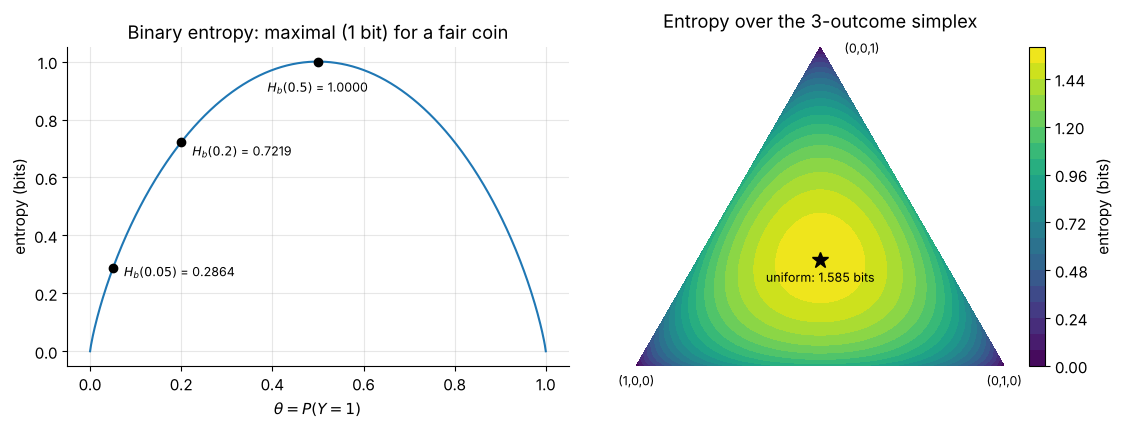

In [27]:
theta_grid = np.linspace(0, 1, 501)
Hb_bits = np.array([entropy([t, 1 - t], base=2) for t in theta_grid])

# Points of the triangle p1 + p2 + p3 = 1 drawn in the plane (barycentric coordinates).
g = np.linspace(0, 1, 61)
P1, P2 = np.meshgrid(g, g)
inside = P1 + P2 <= 1 + 1e-9
p1, p2 = P1[inside], P2[inside]
p3 = np.clip(1 - p1 - p2, 0, 1)
H_tri = np.array([entropy([a, b, c], base=2) for a, b, c in zip(p1, p2, p3)])
tx, ty = p2 + p3 / 2, p3 * np.sqrt(3) / 2              # corner 1 at (0,0), 2 at (1,0), 3 at (1/2, sqrt3/2)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
axes[0].plot(theta_grid, Hb_bits, color="tab:blue")
for t, offset in [(0.05, (8, -6)), (0.2, (8, -10)), (0.5, (0, -22))]:
    h_t = entropy([t, 1 - t], base=2)
    axes[0].plot(t, h_t, "ko")
    axes[0].annotate(f"$H_b({t})$ = {h_t:.4f}", (t, h_t), xytext=offset, textcoords="offset points",
                     fontsize=9, ha="center" if t == 0.5 else "left")
axes[0].set_xlabel(r"$\theta = P(Y = 1)$")
axes[0].set_ylabel("entropy (bits)")
axes[0].set_title("Binary entropy: maximal (1 bit) for a fair coin")

tc = axes[1].tricontourf(tx, ty, H_tri, levels=20, cmap="viridis")
fig.colorbar(tc, ax=axes[1], label="entropy (bits)")
for (cx, cy), lab, off in zip([(0, 0), (1, 0), (0.5, np.sqrt(3) / 2)], ["(1,0,0)", "(0,1,0)", "(0,0,1)"],
                              [(0, -14), (0, -14), (30, -4)]):
    axes[1].annotate(lab, (cx, cy), xytext=off, textcoords="offset points", ha="center", fontsize=9)
axes[1].plot(0.5, np.sqrt(3) / 6, "k*", ms=12)
axes[1].annotate(f"uniform: {np.log2(3):.3f} bits", (0.5, np.sqrt(3) / 6), xytext=(0, -16),
                 textcoords="offset points", ha="center", fontsize=9)
axes[1].set_aspect("equal")
axes[1].axis("off")
axes[1].set_title("Entropy over the 3-outcome simplex", pad=14)
fig.tight_layout()
plt.show()

Two things to notice. First, the binary curve is very flat near the top: a coin with $\theta = 0.2$ still has $0.72$ bits of entropy, while $\theta = 0.05$ drops to $0.29$ bits. Second, in the triangle the entropy is largest at the center ($\log_2 3 \approx 1.585$ bits) and zero only at the three corners. Along each edge, where one outcome is impossible, it reduces to the binary curve.

**Quick check.** (a) What is the entropy of a fair 8-sided die, in bits? (b) Of a die that always shows 3? (c) Which has more entropy: a coin with $\theta = 0.1$ or a coin with $\theta = 0.9$?

<details>
<summary>Answer</summary>

(a) $\log_2 8 = 3$ bits (uniform over 8 outcomes). (b) $0$ bits: one outcome is certain. (c) They are equal, $H_b(0.1) = H_b(0.9) \approx 0.469$ bits: swapping the labels "heads" and "tails" cannot change the entropy (property 3).
</details>

### 5.6 Entropy as the limit of compression

The "number of yes/no questions" story has an engineering twin: **compression**. Encode each weather report as a string of bits. A **prefix code** is one in which no codeword is the beginning of another, so a stream of bits can be decoded without separators. For our station, try

| report | $p(y)$ | codeword | length $\ell(y)$ |
|---|---|---|---|
| sunny | $1/2$ | `0` | 1 |
| cloudy | $1/4$ | `10` | 2 |
| rain | $1/8$ | `110` | 3 |
| storm | $1/8$ | `111` | 3 |

The bit stream `0 0 110 10 0 111` decodes uniquely as sunny, sunny, rain, cloudy, sunny, storm. The average length is $\tfrac12 \cdot 1 + \tfrac14 \cdot 2 + \tfrac18 \cdot 3 + \tfrac18 \cdot 3 = 1.75$ bits per report, exactly $H(P)$, and better than the $2$ bits per report of the obvious fixed-length code (`00`, `01`, `10`, `11`). It is no coincidence that each length equals the surprisal $-\log_2 p(y)$: **frequent outcomes get short codewords and rare ones get long codewords**, just as people say "the usual" on a routine day instead of describing it in full.

**Shannon's source coding theorem** makes this precise:

* no uniquely decodable code (one whose bit stream always decodes back into exactly one message, such as a prefix code) can use fewer than $H(P)$ bits per symbol on average (we prove this for prefix codes in Section 7 with Gibbs' inequality, and McMillan's inequality extends the proof to every uniquely decodable code).
* by encoding long *blocks* of symbols together, one can get as close to $H(P)$ as desired.

The decodability condition matters: the code `0`, `1`, `00`, `01` for four equally likely symbols averages only $1.5$ bits, below their entropy of $2$ bits, but it cheats, because the stream `00` could mean the first symbol twice or the third symbol once.

**Huffman's algorithm** builds an optimal prefix code for single symbols: repeatedly take the two least likely items, merge them into one item whose probability is their sum, and prepend `0` to the codewords of one and `1` to the codewords of the other. For our weather source it rebuilds exactly the code in the table. Here is the tree it constructs (read a codeword by following the branches from the top):

```
                (all reports, 1)
                0 /          \ 1
           sunny 1/2        (1/2)
                            0 /   \ 1
                      cloudy 1/4   (1/4)
                                   0 /  \ 1
                              rain 1/8  storm 1/8
```

In [28]:
def huffman_code(weights: dict) -> dict:
    """Build a binary Huffman code. `weights` maps symbol -> probability (or count).

    Returns a dict symbol -> codeword (a string of '0'/'1'). Ties are broken by insertion order.
    """
    heap = [(w, i, {sym: ""}) for i, (sym, w) in enumerate(weights.items())]
    heapq.heapify(heap)
    if len(heap) == 1:                               # a lone symbol still needs a 1-bit codeword
        return {sym: "0" for sym in weights}
    tie = len(heap)
    while len(heap) > 1:
        w1, _, codes1 = heapq.heappop(heap)          # the two least likely groups ...
        w2, _, codes2 = heapq.heappop(heap)
        merged = {s: "0" + c for s, c in codes1.items()}
        merged.update({s: "1" + c for s, c in codes2.items()})
        heapq.heappush(heap, (w1 + w2, tie, merged))  # ... become one group
        tie += 1
    return heap[0][2]


def average_code_length(weights: dict, code: dict) -> float:
    """Expected codeword length (bits per symbol) when symbols occur with the given weights."""
    total = sum(weights.values())
    return sum(w / total * len(code[s]) for s, w in weights.items())


weather_weights = dict(zip(reports, P_weather))
weather_code = huffman_code(weather_weights)
print("Huffman code:", weather_code)
print(f"average length = {average_code_length(weather_weights, weather_code):.4f} bits, "
      f"entropy = {entropy(P_weather, base=2):.4f} bits")

Huffman code: {'sunny': '0', 'cloudy': '10', 'rain': '110', 'storm': '111'}
average length = 1.7500 bits, entropy = 1.7500 bits


**Real text.** Let us compress letters. Below is a short story (written for this notebook) about a weather station. We lowercase it and keep only the 26 letters plus the space, a 27-symbol alphabet. A second, related story about the same station will appear in Section 10 to train tiny language models.

In [29]:
CORPUS = """
The weather station stood at the end of a long gravel road, past the last farmhouse and an old stone
bridge. Every morning at six the keeper climbed the narrow stairs to read her instruments: the thermometer
in its white wooden box, the rain gauge beside the fence, and the brass barometer that ticked softly
whenever the pressure changed. She wrote each number in a thick green notebook and then read a short
report to the harbor over the radio.
Most days the report was dull. Sunny, light wind from the west, no rain. Cloudy and cool, a little mist
over the river. The fishermen listened anyway, because a dull report meant a calm day at sea, while a
surprising report could save a boat and everyone on it. When the keeper said that a storm was coming,
nobody argued and nobody sailed.
After many years of mornings she began to notice a pattern in her own words. The report almost always
started with the same few phrases, and some words appeared so often that the listeners could finish her
sentences before she did. Other words, like hail or waterspout, came up only once or twice in a whole
season, and when they did, the harbor went quiet. It struck her that the rare words carried the real
news. A report that only confirmed what everyone expected told them almost nothing, while a single
unexpected word could change the plans of the entire town.
One winter a young engineer came to repair the radio. He was curious about the notebook and asked if he
could copy the old reports. He counted how often each kind of weather appeared, and then he counted how
often each letter appeared in the reports themselves. He explained that if a message is predictable, you
can send it with fewer signals, because the listener already guesses most of it. A clever code would give
the common reports very short signals and save the long signals for rare events. The keeper laughed and
said that she had been doing that for years without a name for it. On calm days she simply said the
usual, and everyone understood.
The engineer stayed for a week. In the evenings they compared forecasts with what really happened the
next day. Some forecasts were confident and correct, and those were the ones the fishermen trusted most.
Some were confident and wrong, and those were remembered for a long time, because a boat that stays home
on a sunny day loses a day of work, but a boat that sails into a storm may not come back at all. The
keeper decided to stop using the word certain. Instead she began to say how likely each kind of weather
was, and she kept a careful tally of how often each promise came true.
By spring her tally showed something useful. When she said there was a seven in ten chance of rain, it
rained on about seven of every ten such days. When she said one in ten, it rained roughly once in ten.
Her numbers had become honest, and the town learned to read them. A captain with a sturdy boat might
sail at three in ten, while a small rowing boat would wait for a clear morning. The engineer wrote to her
from the city that her tally was a fine example of a calibrated forecast, and that his colleagues were
trying to teach machines to make predictions that behaved the same way.
In the dry months the jagged hills behind the station turned brown, and a hazy breeze carried dust from
the quarry. The keeper's niece, who was learning to program at school, joined her for a summer. She built
a small machine that listened to the barometer and guessed the next report. At first it was badly
overconfident: it announced a dozen storms that never came, and once it promised a frozen, windless dawn
on the morning of a gale. The niece kept a journal of every mistake and gave each one a score, using a
rule her teacher called the log loss. A wrong guess made with great confidence cost far more points than
a timid one, and a guess of zero chance for something that then happened cost an endless number of
points, so the machine quickly learned never to say never.
By the end of the summer the machine was almost as honest as the keeper. It still could not explain why
the sky over the harbor turned violet before a squall, or why the gulls flew inland a day before the
wind changed, but its numbers had stopped lying. The keeper joked that it had learned the most important
lesson of her job: be quick to say what is likely, slow to say what is certain, and never call anything
impossible.
The station still stands at the end of the gravel road. The brass barometer still ticks, the green
notebooks fill a whole shelf, and the morning report still begins with the same familiar words. But every
listener now knows that the most valuable part of the message is the part they did not expect, and that
a forecast is only as good as the honesty of its numbers.
"""

text = re.sub(r"[^a-z]+", " ", CORPUS.lower()).strip()    # letters and single spaces only
letter_counts = Counter(text)
alphabet = sorted(letter_counts)
print(f"{len(text):,} characters, alphabet of {len(alphabet)} symbols: {''.join(alphabet)!r}")
print("first 80 characters:", repr(text[:80]))

4,666 characters, alphabet of 27 symbols: ' abcdefghijklmnopqrstuvwxyz'
first 80 characters: 'the weather station stood at the end of a long gravel road past the last farmhou'


In [30]:
letter_code = huffman_code(dict(letter_counts))
p_letters = np.array([letter_counts[s] for s in alphabet]) / len(text)
H_letters = entropy(p_letters, base=2)
L_huff = average_code_length(dict(letter_counts), letter_code)

ranked = sorted(alphabet, key=lambda s: -letter_counts[s])
show = ranked[:6] + ranked[-4:]                              # six most and four least common symbols
display(pd.DataFrame({
    "count": [letter_counts[s] for s in show],
    "p": [letter_counts[s] / len(text) for s in show],
    "surprisal -log2 p": [-np.log2(letter_counts[s] / len(text)) for s in show],
    "Huffman codeword": [letter_code[s] for s in show],
}, index=["space" if s == " " else s for s in show]).round(4))
print(f"fixed-length code: {int(np.ceil(np.log2(len(alphabet))))} bits/char | Huffman: {L_huff:.4f} bits/char | "
      f"entropy: {H_letters:.4f} bits/char")

,count,p,surprisal -log2 p,Huffman codeword
space,876,0.1877,2.4132,00
e,544,0.1166,3.1005,011
t,363,0.0778,3.6841,1101
a,333,0.0714,3.8086,1011
o,279,0.0598,4.0638,1001
n,270,0.0579,4.1112,1000
x,10,0.0021,8.8660,1100111011
j,5,0.0011,9.8660,1100111001
q,5,0.0011,9.8660,1100111000
z,5,0.0011,9.8660,1100111010


fixed-length code: 5 bits/char | Huffman: 4.0922 bits/char | entropy: 4.0520 bits/char


Huffman's code uses about $4.1$ bits per character instead of $5$, and it sits just above the entropy, as the theorem promises ($H \le L < H + 1$ for Huffman codes). Codeword lengths track the surprisals: the space and `e` get short codewords, while rare letters such as `z` or `j` get long ones.

The gap between $L$ and $H$ comes from rounding lengths to whole bits. Coding **blocks** of $n$ symbols at once spreads that rounding loss over $n$ symbols. Jar B is the extreme case: its entropy is $0.9934$ bits, yet a code for single beans needs at least $1$ bit per bean. Let us code blocks of $n = 1, \dots, 6$ beans.

n = 1:     4 possible blocks, Huffman uses 1.3125 bits per bean
n = 2:    16 possible blocks, Huffman uses 1.0410 bits per bean
n = 3:    64 possible blocks, Huffman uses 1.0075 bits per bean
n = 4:   256 possible blocks, Huffman uses 0.9976 bits per bean
n = 5:  1024 possible blocks, Huffman uses 1.0040 bits per bean
n = 6:  4096 possible blocks, Huffman uses 1.0005 bits per bean


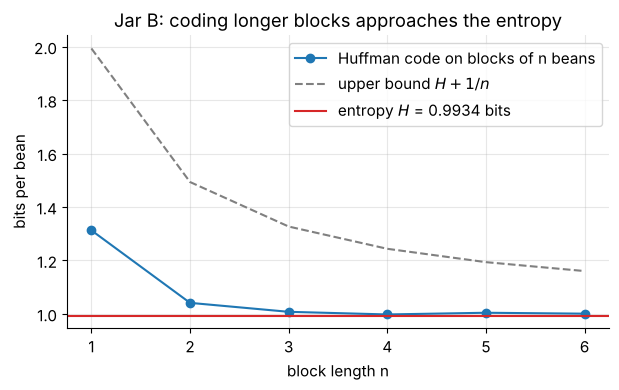

In [31]:
p_jarB = jar_counts["B"] / jar_counts["B"].sum()
H_jarB = entropy(p_jarB, base=2)
block_lengths = []
for n in range(1, 7):
    blocks = {b: float(np.prod(p_jarB[list(b)])) for b in itertools.product(range(4), repeat=n)}  # 4**n blocks
    code_n = huffman_code(blocks)
    block_lengths.append(average_code_length(blocks, code_n) / n)        # bits per bean
    print(f"n = {n}: {4 ** n:>5} possible blocks, Huffman uses {block_lengths[-1]:.4f} bits per bean")

ns = np.arange(1, 7)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(ns, block_lengths, "o-", label="Huffman code on blocks of n beans")
ax.plot(ns, H_jarB + 1 / ns, "--", color="gray", label="upper bound $H + 1/n$")
ax.axhline(H_jarB, color="tab:red", label=f"entropy $H$ = {H_jarB:.4f} bits")
ax.set_xlabel("block length n")
ax.set_ylabel("bits per bean")
ax.set_title("Jar B: coding longer blocks approaches the entropy")
ax.legend()
plt.show()

With single beans we pay $1.3125$ bits per bean (the question strategy from Section 5.1, which is exactly the Huffman tree). With blocks of $6$ the cost drops to about $1.0005$ bits per bean, approaching the entropy $0.9934$ from above while staying below the guarantee $H + 1/n$ (the curve need not decrease every single step). This is the operational meaning of entropy: **the minimum average number of bits per symbol needed to describe outcomes of $P$, in the limit of long blocks.**

> **Key idea.** Entropy $H(P) = -\sum_y p(y)\log p(y)$ is the average surprisal of outcomes drawn from $P$. It is $0$ for certainty, $\log K$ for a uniform choice among $K$ outcomes, and, in bits (with $\log_2$), it is the limit of compression: no uniquely decodable code averages fewer bits per symbol, and coding ever longer blocks gets as close to it as we like.

### ✏️ Exercise 3: entropy from raw counts

In practice you rarely receive a clean probability vector. You receive counts (votes, letters, labels). Write `entropy_from_counts(counts, base=2.0)` that turns a 1-D array of non-negative counts into the entropy of the corresponding empirical distribution, in the requested base. Zero counts must not produce `nan`. Do not call `scipy.stats.entropy`.

In [32]:
# ✏️ Exercise 3: entropy of the empirical distribution behind a vector of counts
def entropy_from_counts(counts, base=2.0):
    """Return the entropy (in units of `base`) of the distribution counts / counts.sum()."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex3():
    assert np.isclose(entropy_from_counts(np.array([4, 4, 4, 4])), 2.0), "jar A should give 2 bits"
    assert np.isclose(entropy_from_counts(np.array([13, 1, 1, 1])), 0.993393, atol=1e-6), "jar B is wrong"
    out = entropy_from_counts(np.array([5, 0, 5]))
    assert np.isfinite(out), "zero counts must contribute 0, not nan"
    assert np.isclose(out, 1.0), f"[5, 0, 5] should give 1 bit, got {out}"
    assert np.isclose(entropy_from_counts(np.array([7])), 0.0), "a single category has zero entropy"
    assert np.isclose(entropy_from_counts(np.array([1, 1, 1]), base=np.e), np.log(3)), "check the base"
    assert np.isclose(entropy_from_counts(np.array([2, 6]), base=4), stats.entropy([2, 6], base=4))
    assert np.isclose(entropy_from_counts(np.array([3, 1, 0, 4])), stats.entropy([3, 1, 0, 4], base=2))


run_check("Exercise 3", _test_ex3)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def entropy_from_counts(counts, base=2.0):
    counts = np.asarray(counts, dtype=float)
    p = counts / counts.sum()          # empirical distribution
    p = p[p > 0]                       # 0 * log 0 = 0: drop empty categories
    return float(-np.sum(p * np.log(p)) / np.log(base))
```
Normalize first, drop the zero probabilities (their contribution is $0$ by convention), then apply the definition. Dividing by $\log(\text{base})$ converts nats to the requested unit.
</details>

## 6. Cross-entropy: surprise under the wrong model

### 6.1 Intuition: a code built for the wrong distribution

Entropy assumes we know the true distribution $P$. In machine learning we never do: we have a **model** $Q$, an estimate of $P$, and we act as if $Q$ were true. What does that cost?

Back to the weather station. Its true report frequencies are $P = (\tfrac12, \tfrac14, \tfrac18, \tfrac18)$ for (sunny, cloudy, rain, storm). An engineer designs a code from his *beliefs* $Q$, giving each report the ideal length for $Q$, namely $\ell(y) = -\log_2 q(y)$ bits. But the reports keep arriving with the *true* frequencies $P$, so the average number of bits per report is

$$
\sum_y p(y)\,\ell(y) = \sum_y p(y)\,\big(-\log_2 q(y)\big).
$$

* If he believes all reports are equally likely, $Q_{\text{unif}} = (\tfrac14, \tfrac14, \tfrac14, \tfrac14)$, every codeword has 2 bits and the average is $2$ bits, versus the optimal $1.75$.
* If he gets the frequencies exactly backwards, $Q_{\text{rev}} = (\tfrac18, \tfrac18, \tfrac14, \tfrac12)$, then sunny (the most common report) gets a 3-bit codeword and storm gets 1 bit. The average becomes $\tfrac12 \cdot 3 + \tfrac14 \cdot 3 + \tfrac18 \cdot 2 + \tfrac18 \cdot 1 = 2.625$ bits.

Believing the wrong distribution costs bits. The quantity on the right is the cross-entropy.

### 6.2 Definition

The **cross-entropy** of a model distribution $Q$ (PMF $q$) relative to a true distribution $P$ (PMF $p$), over the same outcomes $\mathcal{Y}$, is

$$
H(P, Q) \;=\; \mathbb{E}_{Y \sim P}\big[-\log q(Y)\big] \;=\; -\sum_{y \in \mathcal{Y}} p(y)\,\log q(y).
$$

Compare it with entropy, $H(P) = -\sum_y p(y)\log p(y)$. The two distributions play different roles:

| ingredient | in $H(P)$ | in $H(P, Q)$ |
|---|---|---|
| weights: *how often* each outcome happens | $p(y)$ | $p(y)$ (reality) |
| surprisal: *how surprised* we are when it happens | $-\log p(y)$ | $-\log q(y)$ (the model) |

So $H(P, Q)$ is **the average surprise of someone who believes $Q$ while the world follows $P$**. As before, the convention $0 \log q = 0$ applies: outcomes that never happen cost nothing, whatever the model says about them.

**Worked example (bits).** Reversed beliefs $Q_{\text{rev}}$:

| report | $p(y)$ | $q(y)$ | $-\log_2 q(y)$ | $p(y) \cdot (-\log_2 q(y))$ |
|---|---|---|---|---|
| sunny | $1/2$ | $1/8$ | $3$ | $1.5$ |
| cloudy | $1/4$ | $1/8$ | $3$ | $0.75$ |
| rain | $1/8$ | $1/4$ | $2$ | $0.25$ |
| storm | $1/8$ | $1/2$ | $1$ | $0.125$ |
| **total** | | | | $H(P, Q_{\text{rev}}) = 2.625$ bits |

Now in code. Besides our own implementation we check two library routes: SciPy (whose `stats.entropy(p, q)` returns the KL divergence of Section 7, so we add $H(P)$ back) and PyTorch, whose `F.cross_entropy` accepts a probability vector as target and *logits* as input. Since softmax undoes a logarithm ($\operatorname{softmax}(\log \mathbf{q}) = \mathbf{q}$ when $\mathbf{q}$ sums to one), passing $\log \mathbf{q}$ as the logits works.

In [33]:
def cross_entropy(p, q, base=np.e):
    """Cross-entropy H(P, Q) = -sum_y p(y) log q(y) of model q relative to truth p (1-D arrays).

    Terms with p(y) = 0 contribute 0. If q(y) = 0 for some y with p(y) > 0 the result is +inf.
    """
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    nz = p > 0
    with np.errstate(divide="ignore"):              # log(0) = -inf is the mathematically right answer here
        return -np.sum(p[nz] * np.log(q[nz])) / np.log(base)


Q_unif = np.full(4, 1 / 4)
Q_rev = P_weather[::-1].copy()                      # (1/8, 1/8, 1/4, 1/2): exactly backwards
models = {"Q = P (truth)": P_weather, "Q_unif": Q_unif, "Q_rev": Q_rev}

rows = []
for name, q in models.items():
    rows.append({"model": name,
                 "H(P,Q) ours (bits)": cross_entropy(P_weather, q, base=2),
                 "scipy H(P)+KL (bits)": stats.entropy(P_weather, base=2) + stats.entropy(P_weather, q, base=2),
                 "torch (nats)": F.cross_entropy(torch.log(torch.tensor(q))[None], torch.tensor(P_weather)[None]).item(),
                 "ours (nats)": cross_entropy(P_weather, q)})
display(pd.DataFrame(rows).set_index("model").round(4))

,"H(P,Q) ours (bits)",scipy H(P)+KL (bits),torch (nats),ours (nats)
model,,,,
Q = P (truth),1.750,1.750,1.2130,1.2130
Q_unif,2.000,2.000,1.3863,1.3863
Q_rev,2.625,2.625,1.8195,1.8195


The model equal to the truth achieves $1.75$ bits, which is the entropy, and every other model does worse. That is not an accident of this example (Section 7 proves it in general).

### 6.3 Properties

* **$H(P, P) = H(P)$.** If your beliefs are correct, cross-entropy is just entropy.
* **$H(P, Q) \ge H(P)$, with equality only when $Q = P$** (Gibbs' inequality, next section). No model can beat the entropy of reality.
* **It is not symmetric.** In general $H(P, Q) \ne H(Q, P)$, because the two arguments do different jobs. For example $H(P, Q_{\text{unif}}) = 2$ bits, while $H(Q_{\text{unif}}, P) = \tfrac14(1 + 2 + 3 + 3) = 2.25$ bits.
* **It can be infinite.** If the model gives probability $q(y) = 0$ to an outcome that actually has $p(y) > 0$, the term $-p(y)\log 0 = +\infty$. A model that declares something impossible pays an infinite price the first time it happens. (Remember the niece's machine in the story: it learned "never to say never".)
* **With a one-hot truth, it picks out one number.** If $P$ puts all its mass on a single class $c$, so that $p$ is the one-hot vector $\mathbf{e}_c$, then every term except $y = c$ vanishes and

$$
H(\mathbf{e}_c, Q) = -\log q(c).
$$

That last line is the bridge to classification: a labeled example "this is class $c$" is a one-hot distribution, and its cross-entropy with the model's prediction is the surprisal of the correct class under the model.

In [34]:
print(f"H(P, Q_unif) = {cross_entropy(P_weather, Q_unif, base=2):.4f} bits,  "
      f"H(Q_unif, P) = {cross_entropy(Q_unif, P_weather, base=2):.4f} bits  (not symmetric)")

Q_never_storm = np.array([0.5, 0.3, 0.2, 0.0])       # a model that thinks storms are impossible
print("H(P, Q_never_storm) =", cross_entropy(P_weather, Q_never_storm, base=2), "bits")

fruits = ["apple", "banana", "cherry", "grape"]
q_fruit = np.array([0.05, 0.62, 0.25, 0.08])         # a classifier's prediction for one photo
for true_class in ("banana", "cherry"):
    e_c = np.eye(4)[fruits.index(true_class)]         # one-hot "true distribution"
    print(f"truth = {true_class:<6}: H(e_c, q) = {cross_entropy(e_c, q_fruit):.4f} nats "
          f"= -log q({true_class}) = {-np.log(q_fruit[fruits.index(true_class)]):.4f}")

H(P, Q_unif) = 2.0000 bits,  H(Q_unif, P) = 2.2500 bits  (not symmetric)
H(P, Q_never_storm) = inf bits
truth = banana: H(e_c, q) = 0.4780 nats = -log q(banana) = 0.4780
truth = cherry: H(e_c, q) = 1.3863 nats = -log q(cherry) = 1.3863


### 6.4 Cross-entropy is what an average loss estimates

We usually cannot compute $H(P, Q) = \mathbb{E}_{Y\sim P}[-\log q(Y)]$ exactly, because $P$ is unknown. But we can **sample** from $P$: that is what a dataset is. By the law of large numbers (Section 2.2), if $y_1, \dots, y_N$ are independent draws from $P$, then

$$
\frac{1}{N}\sum_{i=1}^{N} -\log q(y_i) \;\xrightarrow[N \to \infty]{}\; H(P, Q).
$$

The left side is simply "the average of $-\log(\text{probability the model gave to what actually happened})$", the log-loss from Section 1. Let us simulate 20,000 days of weather reports (more than 50 years' worth) and score our three models on them as the data arrives.

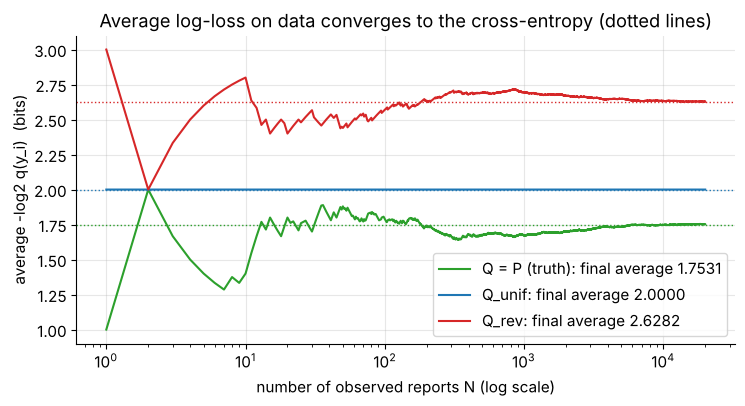

In [35]:
n_days = 20_000
observed = rng.choice(4, size=n_days, p=P_weather)            # indices of the reports that occurred
day_index = np.arange(1, n_days + 1)

fig, ax = plt.subplots(figsize=(8.5, 4))
for (name, q), color in zip(models.items(), ["tab:green", "tab:blue", "tab:red"]):
    running = np.cumsum(-np.log2(q[observed])) / day_index    # running average log-loss (bits)
    ax.plot(day_index, running, color=color, label=f"{name}: final average {running[-1]:.4f}")
    ax.axhline(cross_entropy(P_weather, q, base=2), color=color, ls=":", lw=1)
ax.set_xscale("log")
ax.set_xlabel("number of observed reports N (log scale)")
ax.set_ylabel("average -log2 q(y_i)  (bits)")
ax.set_title("Average log-loss on data converges to the cross-entropy (dotted lines)")
ax.legend()
plt.show()

Each running average settles near its dotted line, the exact cross-entropy ($1.75$, $2$ and $2.625$ bits). The uniform model's curve is flat from the start: it gives every report the same 2-bit surprisal, so its average cannot fluctuate. This is the single most important fact connecting information theory to machine learning:

> **Key idea.** The average log-loss of a model on data drawn from $P$ is a Monte Carlo estimate of the cross-entropy $H(P, Q)$. *Minimizing the average log-loss on a dataset means minimizing the cross-entropy between the data distribution and the model.*

**Quick check.** A model assigns $q(\text{rain}) = 0.02$ and it rains. What is this single prediction's contribution to the average log-loss, in nats and in bits? What would it be if the model had said $q(\text{rain}) = 0$?

<details>
<summary>Answer</summary>

$-\log 0.02 \approx 3.912$ nats, or $-\log_2 0.02 \approx 5.644$ bits (see the table in Section 3.1). With $q = 0$ the contribution is $+\infty$, and so is the average over any dataset containing that day, no matter how good the other predictions are.
</details>

### ✏️ Exercise 4: cross-entropy estimated from samples

Write `empirical_cross_entropy(samples, q, base=2.0)`: `samples` is a 1-D integer array of observed outcome indices, `q` is the model's probability vector. Return the average of $-\log_{\text{base}} q(y_i)$ over the samples. If the model gave probability $0$ to an outcome that was observed, the answer is `np.inf` (and your function must not print a warning or crash). Use NumPy indexing rather than a Python loop.

In [36]:
# ✏️ Exercise 4: the average log-loss of a model on observed outcomes
def empirical_cross_entropy(samples, q, base=2.0):
    """Return mean(-log_base q[samples]), or np.inf if some observed outcome has q = 0."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex4():
    out = empirical_cross_entropy(np.array([0, 0, 1, 3]), np.array([0.5, 0.25, 0.125, 0.125]))
    assert np.isclose(out, (1 + 1 + 2 + 3) / 4), f"expected 1.75 bits, got {out}"
    nats = empirical_cross_entropy(np.array([2, 2]), np.array([0.2, 0.3, 0.5]), base=np.e)
    assert np.isclose(nats, -np.log(0.5)), f"base e is wrong: {nats}"
    # inside this block a divide-by-zero / overflow / invalid warning becomes an error
    with np.errstate(over="raise", divide="raise", invalid="raise"):
        try:
            inf_case = empirical_cross_entropy(np.array([0, 3]), np.array([0.5, 0.3, 0.2, 0.0]))
        except FloatingPointError:
            raise AssertionError("log(0) raised a warning: wrap it in np.errstate(divide='ignore')")
    assert inf_case == np.inf, f"q = 0 for an observed outcome must give inf, got {inf_case}"
    t_rng = np.random.default_rng(1)
    big = t_rng.choice(4, size=200_000, p=[0.5, 0.25, 0.125, 0.125])
    approx = empirical_cross_entropy(big, np.array([0.125, 0.125, 0.25, 0.5]))
    assert abs(approx - 2.625) < 0.02, f"with many samples the answer should approach 2.625 bits, got {approx}"


run_check("Exercise 4", _test_ex4)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def empirical_cross_entropy(samples, q, base=2.0):
    q = np.asarray(q, dtype=float)
    probs = q[np.asarray(samples)]                 # probability the model gave to each observation
    with np.errstate(divide="ignore"):
        return float(-np.mean(np.log(probs)) / np.log(base))
```
Fancy indexing `q[samples]` looks up the model's probability of each observed outcome in one step. A zero probability gives `log(0) = -inf`, so the mean is `+inf`, which is the correct answer, and `np.errstate` only silences the warning.
</details>

## 7. KL divergence: the price of being wrong

### 7.1 Definition and the key identity

Cross-entropy mixes two things: the uncertainty that is *built into* the world, and the extra cost of a *wrong model*. Even a perfect weather model pays $1.75$ bits per report, because the weather is genuinely random. The engineer with the uniform code pays $2$ bits, and only $2 - 1.75 = 0.25$ bits of that are his fault. The **Kullback–Leibler (KL) divergence** isolates the model's fault:

$$
D_{\mathrm{KL}}(P \,\Vert\, Q) \;=\; \sum_{y \in \mathcal{Y}} p(y) \log \frac{p(y)}{q(y)} \;=\; \mathbb{E}_{Y \sim P}\big[\log p(Y) - \log q(Y)\big].
$$

Read it as the **expected extra surprisal**: for each outcome, how much more surprised the model is than the truth, $\big(-\log q(y)\big) - \big(-\log p(y)\big) = \log \frac{p(y)}{q(y)}$, averaged over outcomes drawn from reality. (Conventions: terms with $p(y) = 0$ count as $0$, and a term with $p(y) > 0$ and $q(y) = 0$ is $+\infty$.)

**Derivation of the identity.** Start from the cross-entropy and use the "add and subtract the same thing" trick:

$$
\begin{aligned}
H(P, Q) &= -\sum_y p(y)\log q(y) \\
        &= -\sum_y p(y)\log p(y) \;+\; \sum_y p(y)\log p(y) \;-\; \sum_y p(y)\log q(y) \\
        &= \underbrace{-\sum_y p(y)\log p(y)}_{H(P)} \;+\; \underbrace{\sum_y p(y)\big(\log p(y) - \log q(y)\big)}_{D_{\mathrm{KL}}(P \Vert Q)} .
\end{aligned}
$$

The second line adds $\sum_y p(y)\log p(y)$ and immediately subtracts it again, so nothing changes, and the third line groups the terms (using $\log p - \log q = \log \frac{p}{q}$). Therefore

$$
\boxed{\;H(P, Q) \;=\; H(P) \;+\; D_{\mathrm{KL}}(P \,\Vert\, Q)\;}
$$

**cross-entropy = irreducible uncertainty of the world + penalty for using the wrong model.** For the weather models: $D_{\mathrm{KL}}(P \Vert Q_{\text{unif}}) = 2 - 1.75 = 0.25$ bits and $D_{\mathrm{KL}}(P \Vert Q_{\text{rev}}) = 2.625 - 1.75 = 0.875$ bits.

> **Key idea.** When we train a model, the data distribution $P$ is fixed, so $H(P)$ is a constant that no model can change. **Minimizing cross-entropy over the model is exactly the same as minimizing $D_{\mathrm{KL}}(P \Vert Q)$**: it pushes the model's distribution toward the data distribution.

,H(P),"KL(P||Q) via H(P,Q)-H(P)",KL via sum p log(p/q),"scipy.stats.entropy(p, q)","H(P,Q)"
Q = P,1.75,0.0000,0.0000,0.0000,1.7500
Q_close,1.75,0.0176,0.0176,0.0176,1.7676
Q_unif,1.75,0.2500,0.2500,0.2500,2.0000
Q_rev,1.75,0.8750,0.8750,0.8750,2.6250


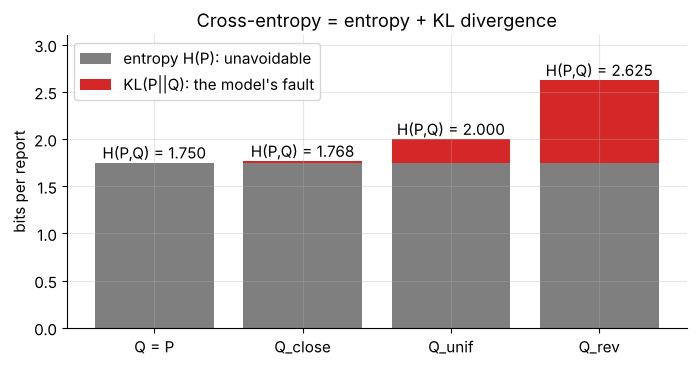

In [37]:
def kl_from_ce(p, q, base=np.e):
    """KL(P || Q) computed through the identity KL = H(P, Q) - H(P)."""
    return cross_entropy(p, q, base) - entropy(p, base)


Q_close = np.array([0.45, 0.30, 0.15, 0.10])          # a decent but imperfect model
models_kl = {"Q = P": P_weather, "Q_close": Q_close, "Q_unif": Q_unif, "Q_rev": Q_rev}
H_P_bits = entropy(P_weather, base=2)
kl_table = pd.DataFrame({
    "H(P)": [H_P_bits] * len(models_kl),
    "KL(P||Q) via H(P,Q)-H(P)": [kl_from_ce(P_weather, q, base=2) for q in models_kl.values()],
    "KL via sum p log(p/q)": [np.sum(special.rel_entr(P_weather, q)) / np.log(2) for q in models_kl.values()],
    "scipy.stats.entropy(p, q)": [stats.entropy(P_weather, q, base=2) for q in models_kl.values()],
    "H(P,Q)": [cross_entropy(P_weather, q, base=2) for q in models_kl.values()],
}, index=list(models_kl))
display(kl_table.round(4))

fig, ax = plt.subplots(figsize=(8, 3.8))
names = list(models_kl)
kl_bits = kl_table["KL(P||Q) via H(P,Q)-H(P)"].to_numpy()
ax.bar(names, [H_P_bits] * len(names), color="tab:gray", label="entropy H(P): unavoidable")
ax.bar(names, kl_bits, bottom=H_P_bits, color="tab:red", label="KL(P||Q): the model's fault")
for i, total in enumerate(H_P_bits + kl_bits):
    ax.annotate(f"H(P,Q) = {total:.3f}", (i, total), xytext=(0, 3), textcoords="offset points", ha="center")
ax.set_ylabel("bits per report")
ax.set_ylim(0, 3.1)
ax.set_title("Cross-entropy = entropy + KL divergence")
ax.legend(loc="upper left")
plt.show()

`scipy.special.rel_entr(p, q)` computes the individual terms $p \log(p/q)$ with the right conventions, and `scipy.stats.entropy(p, q)` (two arguments!) returns their sum, the KL divergence. All three routes agree.

### 7.2 Gibbs' inequality: KL is never negative

**Theorem (Gibbs' inequality).** For any distributions $P$ and $Q$ on the same finite set,

$$
D_{\mathrm{KL}}(P \Vert Q) \ge 0, \qquad \text{with equality if and only if } P = Q .
$$

*Proof.* If $q(y) = 0$ for some $y$ with $p(y) > 0$, the divergence is $+\infty$ and there is nothing to prove, so assume $q(y) > 0$ wherever $p(y) > 0$. Let $S = \{y : p(y) > 0\}$. Using the inequality $\log x \le x - 1$ from Section 3.2 with $x = q(y)/p(y)$:

$$
-D_{\mathrm{KL}}(P \Vert Q) = \sum_{y \in S} p(y)\log\frac{q(y)}{p(y)}
\;\le\; \sum_{y \in S} p(y)\left(\frac{q(y)}{p(y)} - 1\right)
= \sum_{y \in S} q(y) - \sum_{y \in S} p(y)
\;\le\; 1 - 1 = 0 .
$$

(The last step uses $\sum_{y\in S} q(y) \le 1$ and $\sum_{y\in S} p(y) = 1$.) Hence $D_{\mathrm{KL}}(P \Vert Q) \ge 0$. For equality, both inequalities must be tight: $\log x = x - 1$ only at $x = 1$, so $q(y) = p(y)$ for every $y \in S$, and $\sum_{y \in S} q(y) = 1$, so $Q$ puts no mass outside $S$. Together, $Q = P$. Conversely, $P = Q$ makes every log-ratio zero, so the divergence is $0$. This completes the proof.

Three corollaries, each a one-liner now:

1. **Cross-entropy is at least the entropy:** $H(P, Q) = H(P) + D_{\mathrm{KL}}(P\Vert Q) \ge H(P)$, with equality only for $Q = P$. The best possible model of the weather is the true weather distribution.
2. **Entropy is at most $\log K$ (second proof).** Let $U$ be uniform on $K$ outcomes. Then $D_{\mathrm{KL}}(P \Vert U) = \sum_y p(y)\log\big(p(y)\,K\big) = \log K - H(P) \ge 0$. So $H(P) \le \log K$, with equality only when $P = U$.
3. **No prefix code beats the entropy.** Any prefix code satisfies the **Kraft inequality** $\sum_y 2^{-\ell(y)} \le 1$ (each codeword of length $\ell$ "uses up" a fraction $2^{-\ell}$ of all infinite bit strings, and prefix-freeness means these fractions do not overlap). Put $Z = \sum_y 2^{-\ell(y)} \le 1$ and define the distribution $r(y) = 2^{-\ell(y)}/Z$, so $\ell(y) = -\log_2 r(y) - \log_2 Z$. The average length is then

$$
\sum_y p(y)\,\ell(y) = H_2(P, R) - \log_2 Z \;\ge\; H_2(P, R) \;\ge\; H_2(P),
$$

where $H_2$ denotes entropies in bits. This is the lower bound of the source coding theorem promised in Section 5.6, for prefix codes. McMillan's inequality states that every uniquely decodable code also satisfies the Kraft inequality, so the same argument covers all of them.

A quick numerical sanity check on 100,000 random pairs of distributions:

In [38]:
A_dists = rng.dirichlet(np.ones(4), size=100_000)
B_dists = rng.dirichlet(np.ones(4), size=100_000)
kl_pairs = special.rel_entr(A_dists, B_dists).sum(axis=1)       # KL(A_i || B_i) for every pair, in nats
print(f"smallest KL among 100,000 random pairs: {kl_pairs.min():.6f} nats (never negative)")
print(f"KL(P || P) for the weather source: {np.sum(special.rel_entr(P_weather, P_weather)):.1f}")
print(f"KL(P || uniform) = {stats.entropy(P_weather, Q_unif):.4f} nats = log 4 - H(P) = {np.log(4) - entropy(P_weather):.4f}")

smallest KL among 100,000 random pairs: 0.000109 nats (never negative)
KL(P || P) for the weather source: 0.0
KL(P || uniform) = 0.1733 nats = log 4 - H(P) = 0.1733


### 7.3 Asymmetry, infinities, and why KL is not a distance

KL divergence measures how different $Q$ is from $P$, and it is $0$ exactly when they agree, so it is tempting to call it a distance. It is not one, for two reasons.

**It is asymmetric.** In general $D_{\mathrm{KL}}(P \Vert Q) \ne D_{\mathrm{KL}}(Q \Vert P)$. Take two coins: a fair one, $\text{Bern}(0.5)$, and a heavily biased one, $\text{Bern}(0.05)$. Then

$$
D_{\mathrm{KL}}\big(\text{Bern}(0.5)\Vert\text{Bern}(0.05)\big) = 0.5\log\frac{0.5}{0.05} + 0.5\log\frac{0.5}{0.95} \approx 0.8304, \qquad
D_{\mathrm{KL}}\big(\text{Bern}(0.05)\Vert\text{Bern}(0.5)\big) = 0.05\log\frac{0.05}{0.5} + 0.95\log\frac{0.95}{0.5} \approx 0.4946 .
$$

Expecting the biased coin when the coin is actually fair hurts more: heads come up half the time and each one is a 20-to-1 surprise for the believer in $\text{Bern}(0.05)$.

**It can be infinite in one direction only.** Let $P$ be a fair die and $Q$ a model that believes a six is impossible, $Q = (0.2, 0.2, 0.2, 0.2, 0.2, 0)$. Then $D_{\mathrm{KL}}(P \Vert Q) = +\infty$ (sixes happen, and each one is infinitely surprising to $Q$), while $D_{\mathrm{KL}}(Q \Vert P) = \sum_{y=1}^{5} 0.2 \log\frac{0.2}{1/6} = \log 1.2 \approx 0.1823$ is perfectly finite. In words: $D_{\mathrm{KL}}(P \Vert Q) < \infty$ requires $Q$ to **cover** every outcome that $P$ can produce.

**It violates the triangle inequality.** For a true distance, going from $A$ to $C$ directly is never longer than going via $B$. With coins $A = \text{Bern}(0.1)$, $B = \text{Bern}(0.5)$, $C = \text{Bern}(0.9)$ we get $D_{\mathrm{KL}}(A\Vert C) \approx 1.7578 > D_{\mathrm{KL}}(A\Vert B) + D_{\mathrm{KL}}(B \Vert C) \approx 0.3681 + 0.5108$.

That is why it is called a *divergence*: it is a directed measure of mismatch, not a distance.

In [39]:
def bern(theta):
    """Bernoulli(theta) written as a probability vector (P(1), P(0))."""
    return np.array([theta, 1 - theta])


def kl_nats(p, q):
    """KL(P || Q) in nats, via scipy.special.rel_entr (handles 0 log 0 and q = 0 correctly)."""
    return float(np.sum(special.rel_entr(p, q)))


print(f"KL(Bern(0.5) || Bern(0.05)) = {kl_nats(bern(0.5), bern(0.05)):.4f}")
print(f"KL(Bern(0.05) || Bern(0.5)) = {kl_nats(bern(0.05), bern(0.5)):.4f}")

die_fair = np.full(6, 1 / 6)
die_never_six = np.array([0.2, 0.2, 0.2, 0.2, 0.2, 0.0])
print(f"KL(fair || never-six) = {kl_nats(die_fair, die_never_six)},  "
      f"KL(never-six || fair) = {kl_nats(die_never_six, die_fair):.4f} = log 1.2 = {np.log(1.2):.4f}")

A_c, B_c, C_c = bern(0.1), bern(0.5), bern(0.9)
print(f"triangle: KL(A||C) = {kl_nats(A_c, C_c):.4f}  >  KL(A||B) + KL(B||C) = "
      f"{kl_nats(A_c, B_c):.4f} + {kl_nats(B_c, C_c):.4f} = {kl_nats(A_c, B_c) + kl_nats(B_c, C_c):.4f}")

KL(Bern(0.5) || Bern(0.05)) = 0.8304
KL(Bern(0.05) || Bern(0.5)) = 0.4946
KL(fair || never-six) = inf,  KL(never-six || fair) = 0.1823 = log 1.2 = 0.1823
triangle: KL(A||C) = 1.7578  >  KL(A||B) + KL(B||C) = 0.3681 + 0.5108 = 0.8789


> **Going deeper.** If you need a symmetric, always-finite way to compare distributions, use the **Jensen–Shannon divergence** $\mathrm{JS}(P, Q) = \tfrac12 D_{\mathrm{KL}}(P \Vert M) + \tfrac12 D_{\mathrm{KL}}(Q \Vert M)$ with the mixture $M = \tfrac12(P + Q)$. Because $M$ covers both supports it is never infinite (it is at most $\log 2$), and its square root is a genuine metric. SciPy's `scipy.spatial.distance.jensenshannon(p, q)` returns that square root. For the fair die and the never-six model it gives a finite value even though one KL direction is infinite:

In [40]:
js_distance = jensenshannon(die_fair, die_never_six)     # SciPy returns sqrt(JS), in nats by default
print(f"JS(fair, never-six) = {js_distance ** 2:.4f} nats  (<= log 2 = {np.log(2):.4f}),  "
      f"symmetric: {np.isclose(jensenshannon(die_never_six, die_fair), js_distance)}")

JS(fair, never-six) = 0.0616 nats  (<= log 2 = 0.6931);  symmetric: True


### 7.4 Forward vs reverse KL: mode-covering vs mode-seeking

The asymmetry is not a technicality: it changes *what kind of model you get* when you fit one. Let the truth $P$ be bimodal, a mixture of two bell curves,

$$
p(x) = 0.6\,\mathcal{N}(x;\,-2.5,\,0.6^2) + 0.4\,\mathcal{N}(x;\,3,\,0.9^2),
$$

where $\mathcal{N}(x; \mu, \sigma^2) = \frac{1}{\sigma\sqrt{2\pi}}\exp\!\big(-\frac{(x-\mu)^2}{2\sigma^2}\big)$ is the normal density, and let the model family be a *single* bell curve $q = \mathcal{N}(\mu, \sigma^2)$ with two parameters. A single bump cannot match two bumps, so we must choose which mismatch to minimize. For densities the sums become integrals, $D_{\mathrm{KL}}(P\Vert Q) = \int p(x)\log\frac{p(x)}{q(x)}\,dx$, and Gibbs' inequality still holds. We evaluate the integrals numerically on a fine grid.

* **Forward KL, $D_{\mathrm{KL}}(P \Vert Q)$**, averages $\log\frac{p}{q}$ over samples of $P$. It explodes wherever $p$ has mass and $q \approx 0$, so the model is forced to **cover every mode**, even at the price of putting mass in the valley between them. For a Gaussian $q$ the optimum is **moment matching**: $D_{\mathrm{KL}}(P\Vert Q) = -H(P) + \mathbb{E}_P\big[\tfrac12\log(2\pi\sigma^2) + \tfrac{(X-\mu)^2}{2\sigma^2}\big]$, and setting the derivatives to zero gives $\mu = \mathbb{E}_P[X]$ and then $\sigma^2 = \operatorname{Var}_P[X]$.
* **Reverse KL, $D_{\mathrm{KL}}(Q \Vert P)$**, averages $\log\frac{q}{p}$ over samples of $Q$. It explodes wherever $q$ has mass and $p \approx 0$, so the model **avoids the valley** and squeezes into **one mode**, ignoring the other one entirely.

In [41]:
mix_w, mix_mu, mix_sd = np.array([0.6, 0.4]), np.array([-2.5, 3.0]), np.array([0.6, 0.9])
xs = np.linspace(-12, 12, 4801)                          # integration grid


def log_normal_pdf(x, mu, sigma):
    """log N(x; mu, sigma^2), broadcasting over arrays."""
    return -0.5 * np.log(2 * np.pi) - np.log(sigma) - (x - mu) ** 2 / (2 * sigma ** 2)


log_p_mix = special.logsumexp(np.log(mix_w)[:, None] + log_normal_pdf(xs[None, :], mix_mu[:, None], mix_sd[:, None]),
                              axis=0)                   # log of the mixture density, computed stably
p_mix = np.exp(log_p_mix)


def forward_kl(mu, sigma):
    """KL(P || N(mu, sigma^2)) by numerical integration over the grid."""
    return trapezoid(p_mix * (log_p_mix - log_normal_pdf(xs, mu, sigma)), xs)


def reverse_kl(mu, sigma):
    """KL(N(mu, sigma^2) || P) by numerical integration over the grid."""
    log_q = log_normal_pdf(xs, mu, sigma)
    return trapezoid(np.exp(log_q) * (log_q - log_p_mix), xs)


fits = []
for start in [(-4.0, 1.0), (0.0, 1.0), (4.0, 1.0)]:
    for name, objective in [("forward KL(P||Q)", forward_kl), ("reverse KL(Q||P)", reverse_kl)]:
        res = optimize.minimize(lambda t: objective(t[0], np.exp(t[1])), [start[0], np.log(start[1])],
                                method="Nelder-Mead", options={"xatol": 1e-6, "fatol": 1e-10, "maxiter": 4000})
        fits.append({"objective": name, "start mu": start[0], "fitted mu": res.x[0],
                     "fitted sigma": np.exp(res.x[1]), "KL at optimum": res.fun})
fit_table = pd.DataFrame(fits).sort_values(["objective", "start mu"]).reset_index(drop=True)
display(fit_table.round(4))

mm_mu = np.sum(mix_w * mix_mu)                                           # E_P[X]
mm_sd = np.sqrt(np.sum(mix_w * (mix_sd ** 2 + mix_mu ** 2)) - mm_mu ** 2)  # sqrt(Var_P[X])
print(f"moment matching by formula: mu = {mm_mu:.4f}, sigma = {mm_sd:.4f}.  "
      f"-log(0.6) = {-np.log(0.6):.4f}, -log(0.4) = {-np.log(0.4):.4f}")

,objective,start mu,fitted mu,fitted sigma,KL at optimum
0,forward KL(P||Q),-4.0,-0.3000,2.7928,0.7030
1,forward KL(P||Q),0.0,-0.3000,2.7928,0.7030
2,forward KL(P||Q),4.0,-0.3000,2.7928,0.7030
3,reverse KL(Q||P),-4.0,-2.4994,0.6010,0.5106
4,reverse KL(Q||P),0.0,2.9981,0.9035,0.9158
5,reverse KL(Q||P),4.0,2.9981,0.9035,0.9158


moment matching by formula: mu = -0.3000, sigma = 2.7928;  -log(0.6) = 0.5108, -log(0.4) = 0.9163


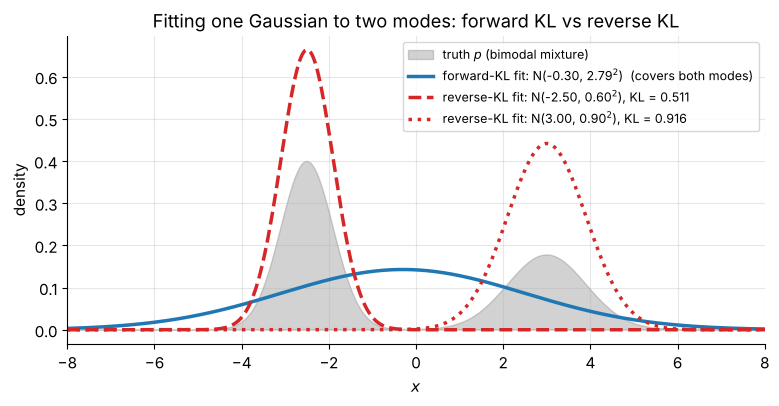

In [42]:
is_reverse = fit_table["objective"].str.startswith("reverse")
rev_fits = fit_table[is_reverse].loc[lambda d: ~d["fitted mu"].round(2).duplicated()]   # one row per distinct optimum
fig, ax = plt.subplots(figsize=(9, 4))
ax.fill_between(xs, p_mix, color="tab:gray", alpha=0.35, label="truth $p$ (bimodal mixture)")
ax.plot(xs, np.exp(log_normal_pdf(xs, mm_mu, mm_sd)), color="tab:blue", lw=2.5,
        label=f"forward-KL fit: N({mm_mu:.2f}, {mm_sd:.2f}$^2$)  (covers both modes)")
for (_, row), style in zip(rev_fits.iterrows(), ["--", ":"]):
    ax.plot(xs, np.exp(log_normal_pdf(xs, row["fitted mu"], row["fitted sigma"])), style, color="tab:red", lw=2.5,
            label=f"reverse-KL fit: N({row['fitted mu']:.2f}, {row['fitted sigma']:.2f}$^2$), KL = {row['KL at optimum']:.3f}")
ax.set_xlim(-8, 8)
ax.set_xlabel("$x$")
ax.set_ylabel("density")
ax.set_title("Fitting one Gaussian to two modes: forward KL vs reverse KL")
ax.legend(fontsize=9, loc="upper right")
plt.show()

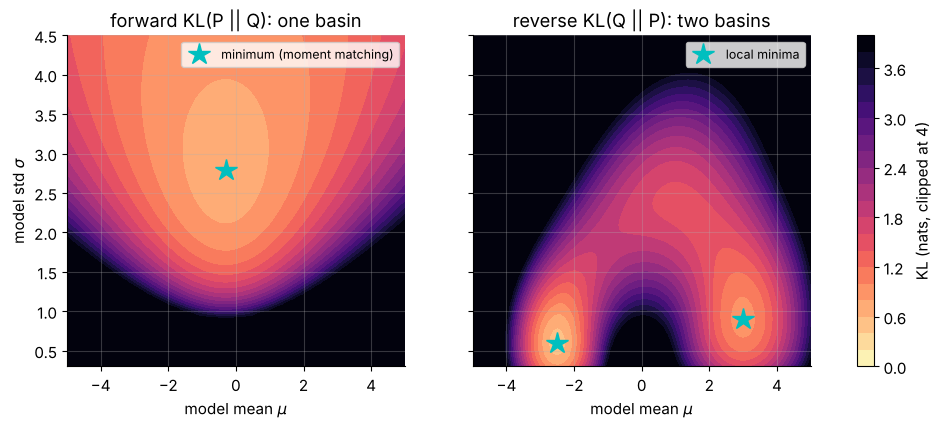

In [43]:
mu_grid = np.linspace(-5, 5, 81)
sigma_grid = np.linspace(0.3, 4.5, 64)
F_land = np.empty((len(sigma_grid), len(mu_grid)))
R_land = np.empty_like(F_land)
for i, sg in enumerate(sigma_grid):                       # one row of the landscape at a time (keeps memory small)
    log_q = log_normal_pdf(xs[None, :], mu_grid[:, None], sg)   # shape (81, 4801)
    F_land[i] = trapezoid(p_mix * (log_p_mix - log_q), xs, axis=1)
    R_land[i] = trapezoid(np.exp(log_q) * (log_q - log_p_mix), xs, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, land, title in [(axes[0], F_land, "forward KL(P || Q): one basin"),
                        (axes[1], R_land, "reverse KL(Q || P): two basins")]:
    cs = ax.contourf(mu_grid, sigma_grid, np.minimum(land, 4.0), levels=np.linspace(0, 4, 21), cmap="magma_r")
    ax.set_xlabel(r"model mean $\mu$")
    ax.set_title(title)
axes[0].plot(mm_mu, mm_sd, "c*", ms=16, label="minimum (moment matching)")
axes[1].plot(rev_fits["fitted mu"], rev_fits["fitted sigma"], "c*", ms=16, label="local minima")
for ax in axes:
    ax.legend(loc="upper right", fontsize=9)
axes[0].set_ylabel(r"model std $\sigma$")
fig.colorbar(cs, ax=axes, label="KL (nats, clipped at 4)")
plt.show()

What the numbers and pictures say:

* **Forward KL** has a single minimum, at $\mu = -0.3$ and $\sigma \approx 2.79$, exactly the mean and standard deviation of the mixture, whatever the starting point. The fitted bell is wide and centered in the valley where the truth has almost no mass: it *covers* both modes at the price of blurring them ($D_{\mathrm{KL}} \approx 0.703$).
* **Reverse KL** has **two** local minima, and the optimizer lands in whichever basin it starts in. Each one sits exactly on a single mode ($\mu \approx -2.50, \sigma \approx 0.60$ or $\mu \approx 3.00, \sigma \approx 0.90$) and ignores the other. The divergence at these minima is about $0.511$ and $0.916$, remarkably close to $-\log 0.6$ and $-\log 0.4$. Why: if $q$ equals the $k$-th component and the components barely overlap, then wherever $q$ has mass the truth is $p(x) \approx w_k\, q(x)$, so $\log\frac{q}{p} \approx -\log w_k$ everywhere that matters.

Why you should care:

* **Maximum-likelihood training (the cross-entropy loss) minimizes the forward KL** from the data to the model (Section 8). A model that is too simple therefore *spreads* probability to cover all the data: a small language model hedges between several continuations, and a simple image model produces blurry averages of several plausible images.
* **Variational inference** (used, for example, in variational autoencoders and Bayesian neural networks) minimizes a *reverse* KL, and its approximations are known to be mode-seeking and **overconfident**: they underestimate uncertainty because they can ignore whole modes.

> **Going deeper.** Between two Gaussians the KL divergence has a closed form, which appears in the loss of every variational autoencoder:
> $D_{\mathrm{KL}}\big(\mathcal{N}(\mu_1, \sigma_1^2) \,\Vert\, \mathcal{N}(\mu_2, \sigma_2^2)\big) = \log\frac{\sigma_2}{\sigma_1} + \frac{\sigma_1^2 + (\mu_1 - \mu_2)^2}{2\sigma_2^2} - \frac12$.
> It is $0$ only when both means and both standard deviations agree, and the next cell checks it against numerical integration.

In [44]:
def kl_gaussians(mu1, s1, mu2, s2):
    """Closed-form KL( N(mu1, s1^2) || N(mu2, s2^2) ) in nats."""
    return np.log(s2 / s1) + (s1 ** 2 + (mu1 - mu2) ** 2) / (2 * s2 ** 2) - 0.5


log_q1, log_q2 = log_normal_pdf(xs, 0.0, 1.0), log_normal_pdf(xs, 1.0, 2.0)
print(f"KL(N(0,1) || N(1,4)): closed form {kl_gaussians(0.0, 1.0, 1.0, 2.0):.6f}, "
      f"numerical {trapezoid(np.exp(log_q1) * (log_q1 - log_q2), xs):.6f}")
print(f"KL(N(1,4) || N(0,1)): closed form {kl_gaussians(1.0, 2.0, 0.0, 1.0):.6f}  (asymmetric again)")

KL(N(0,1) || N(1,4)): closed form 0.443147, numerical 0.443147
KL(N(1,4) || N(0,1)): closed form 1.306853  (asymmetric again)


**Quick check.** You fit a model $Q$ by minimizing $D_{\mathrm{KL}}(P \Vert Q)$, and some outcome has $p(y) = 0.01$. Can the fitted model set $q(y) = 0$? What if you minimized $D_{\mathrm{KL}}(Q \Vert P)$ instead?

<details>
<summary>Answer</summary>

Under the forward KL, no: $q(y) = 0$ with $p(y) > 0$ makes the divergence infinite, so any finite-loss model must keep $q(y) > 0$ (it must *cover* $P$). Under the reverse KL, yes: the term for $y$ is $q(y)\log\frac{q(y)}{p(y)}$, which is $0$ when $q(y) = 0$. Reverse KL is happy to ignore outcomes, which is exactly the mode-seeking behavior above. The reverse KL would instead be infinite if $q(y) > 0$ where $p(y) = 0$.
</details>

### ✏️ Exercise 5: KL divergence from the definition

Implement `kl_divergence(p, q, base=np.e)` directly from $\sum_y p(y)\log\frac{p(y)}{q(y)}$, without SciPy. Required behavior: terms with $p(y) = 0$ contribute $0$ (even if $q(y) = 0$). If some $p(y) > 0$ has $q(y) = 0$, return `np.inf`. No warnings.

In [45]:
# ✏️ Exercise 5: KL divergence with the correct conventions
def kl_divergence(p, q, base=np.e):
    """Return KL(P || Q) = sum_y p(y) log_base(p(y) / q(y)) for 1-D probability vectors p, q."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex5():
    p, q = np.array([0.5, 0.25, 0.125, 0.125]), np.full(4, 0.25)
    assert np.isclose(kl_divergence(p, q, base=2), 0.25), "weather source vs uniform should be 0.25 bits"
    assert np.isclose(kl_divergence(p, p), 0.0), "KL(P || P) must be 0"
    assert np.isclose(kl_divergence(np.array([0.5, 0.5]), np.array([0.05, 0.95])), 0.830366, atol=1e-6), "Bernoulli example is wrong"
    with np.errstate(over="raise", divide="raise", invalid="raise"):
        try:
            zero_p = kl_divergence(np.array([0.0, 1.0]), np.array([0.0, 1.0]))
            inf_q = kl_divergence(np.full(6, 1 / 6), np.array([0.2, 0.2, 0.2, 0.2, 0.2, 0.0]))
        except FloatingPointError:
            raise AssertionError("a warning was raised: mask the zeros or use np.errstate")
    assert np.isclose(zero_p, 0.0), f"terms with p = 0 must contribute 0, got {zero_p}"
    assert inf_q == np.inf, f"q = 0 where p > 0 must give inf, got {inf_q}"
    t_rng = np.random.default_rng(3)
    for _ in range(20):
        a, b = t_rng.dirichlet(np.ones(5)), t_rng.dirichlet(np.ones(5))
        assert np.isclose(kl_divergence(a, b), stats.entropy(a, b)), "disagrees with scipy.stats.entropy"


run_check("Exercise 5", _test_ex5)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def kl_divergence(p, q, base=np.e):
    p, q = np.asarray(p, dtype=float), np.asarray(q, dtype=float)
    support = p > 0                              # only outcomes that can happen count
    if np.any(q[support] == 0):
        return np.inf                            # Q calls a possible outcome impossible
    ps, qs = p[support], q[support]
    return float(np.sum(ps * np.log(ps / qs)) / np.log(base))
```
Restricting to the support of $P$ implements $0 \log 0 = 0$, and checking for $q = 0$ on that support first avoids computing `log(inf)`.
</details>

## 8. Cross-entropy as a training loss

We now have all the theory. This section turns it into the loss function you will use for every classifier.

### 8.1 Maximum likelihood is cross-entropy minimization

**Setup.** A dataset $\mathcal{D} = \{(\mathbf{x}_i, y_i)\}_{i=1}^{N}$ contains inputs $\mathbf{x}_i$ (images, feature vectors, ...) and labels $y_i \in \{1, \dots, K\}$. A probabilistic classifier with parameters $\boldsymbol\theta$ maps each input to a distribution over the $K$ classes, $q_{\boldsymbol\theta}(\,\cdot \mid \mathbf{x}) \in \Delta^{K-1}$.

**Maximum likelihood** chooses the parameters under which the observed labels are most probable. If the examples are independent, the probability of all the labels is a product, the **likelihood**:

$$
\mathcal{L}(\boldsymbol\theta) = \prod_{i=1}^{N} q_{\boldsymbol\theta}(y_i \mid \mathbf{x}_i).
$$

Section 3 told us never to multiply many probabilities, and that $\log$ is increasing, so maximizing $\mathcal{L}$ is the same as maximizing $\log \mathcal{L} = \sum_i \log q_{\boldsymbol\theta}(y_i \mid \mathbf{x}_i)$, which is the same as minimizing the **average negative log-likelihood (NLL)**:

$$
J(\boldsymbol\theta) = -\frac{1}{N}\sum_{i=1}^{N} \log q_{\boldsymbol\theta}(y_i \mid \mathbf{x}_i)
             = \frac{1}{N}\sum_{i=1}^{N} H\big(\mathbf{e}_{y_i},\; q_{\boldsymbol\theta}(\cdot \mid \mathbf{x}_i)\big).
$$

The second form uses Section 6.3: $-\log q(y_i)$ is the cross-entropy between the one-hot label $\mathbf{e}_{y_i}$ and the prediction. So **negative log-likelihood, cross-entropy loss and log-loss are three names for one quantity.** (We average instead of summing so that the loss, and hence a good learning rate, does not depend on the dataset size.)

**The model-free case reveals what is being minimized.** Suppose there is no input at all: the model is a single distribution $\mathbf{q}$ over $K$ outcomes, fitted to observed outcomes $y_1, \dots, y_N$. Let $n_k$ count how often outcome $k$ appears and let $\hat p_k = n_k / N$ be the **empirical distribution** $\hat P$. Grouping equal terms,

$$
J(\mathbf{q}) = -\frac1N \sum_{k=1}^{K} n_k \log q_k = -\sum_{k=1}^{K} \hat p_k \log q_k = H(\hat P, \mathbf{q}) = H(\hat P) + D_{\mathrm{KL}}(\hat P \,\Vert\, \mathbf{q}).
$$

By Gibbs' inequality the right-hand side is smallest exactly when $\mathbf{q} = \hat P$. We have just proved, **without any calculus**, a classic result: *the maximum-likelihood estimate of a categorical distribution is the vector of observed frequencies*, and the smallest achievable average loss is the entropy of the data, $H(\hat P)$.

Let us watch gradient descent discover this. A spinner with five colored sectors was spun 250 times, and we fit $\mathbf{q} = \operatorname{softmax}(\mathbf{z})$ (Section 9 explains the softmax, which just turns any 5 numbers $\mathbf{z}$ into a probability vector) by minimizing the cross-entropy with PyTorch.

In [46]:
colors_spin = ["red", "blue", "green", "yellow", "purple"]
spin_counts = np.array([92, 61, 47, 33, 17])                 # observed outcomes of 250 spins
p_hat = spin_counts / spin_counts.sum()                       # empirical distribution

z_spin = torch.zeros(5, dtype=torch.float64, requires_grad=True)   # start from the uniform model
optimizer = torch.optim.SGD([z_spin], lr=1.0)
spin_losses = []
for step in range(300):
    # mean NLL over the 250 spins = cross-entropy between p_hat and softmax(z)
    loss = -(torch.tensor(p_hat) * F.log_softmax(z_spin, dim=0)).sum()
    spin_losses.append(loss.item())
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

q_fit = torch.softmax(z_spin, dim=0).detach().numpy()
display(pd.DataFrame({"count": spin_counts, "empirical p_hat": p_hat, "fitted q": q_fit}, index=colors_spin).round(4))
print(f"initial loss (uniform model) = {spin_losses[0]:.4f} = log 5 = {np.log(5):.4f}")
print(f"final loss = {spin_losses[-1]:.6f},  entropy of the data H(p_hat) = {entropy(p_hat):.6f}")

,count,empirical p_hat,fitted q
red,92,0.368,0.368
blue,61,0.244,0.244
green,47,0.188,0.188
yellow,33,0.132,0.132
purple,17,0.068,0.068


initial loss (uniform model) = 1.6094 = log 5 = 1.6094
final loss = 1.476364;  entropy of the data H(p_hat) = 1.476364


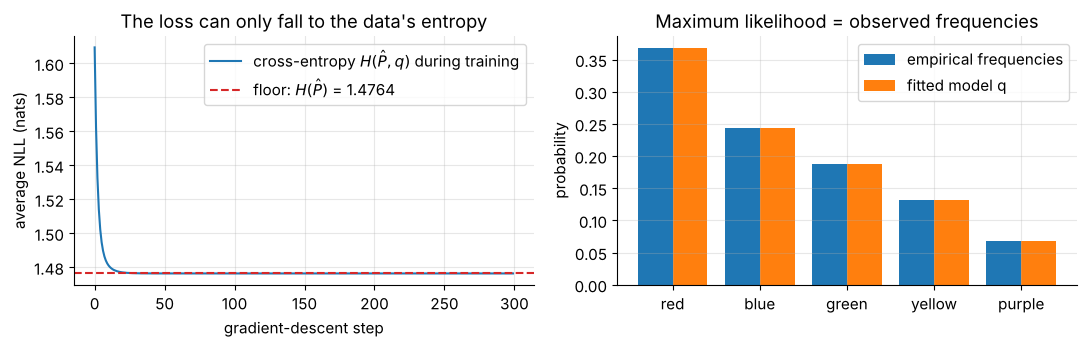

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(spin_losses, label="cross-entropy $H(\\hat P, q)$ during training")
axes[0].axhline(entropy(p_hat), color="tab:red", ls="--", label=f"floor: $H(\\hat P)$ = {entropy(p_hat):.4f}")
axes[0].set_xlabel("gradient-descent step")
axes[0].set_ylabel("average NLL (nats)")
axes[0].set_title("The loss can only fall to the data's entropy")
axes[0].legend()
xpos = np.arange(5)
axes[1].bar(xpos - 0.2, p_hat, 0.4, label="empirical frequencies")
axes[1].bar(xpos + 0.2, q_fit, 0.4, label="fitted model q")
axes[1].set_xticks(xpos, colors_spin)
axes[1].set_ylabel("probability")
axes[1].set_title("Maximum likelihood = observed frequencies")
axes[1].legend()
fig.tight_layout()
plt.show()

The loss starts at $\log 5$ (the uniform model) and falls to $H(\hat P) \approx 1.4764$ nats, not to zero: the spinner itself is random, and no model can remove that randomness. The remaining gap $J(\mathbf{q}) - H(\hat P)$ is exactly $D_{\mathrm{KL}}(\hat P\Vert\mathbf{q})$, which training drives to zero.

> **Key idea.** Training a classifier with the cross-entropy loss = maximum likelihood = minimizing $D_{\mathrm{KL}}(\text{data} \,\Vert\, \text{model})$, the *forward* KL from Section 7.4. The loss is bounded below by the uncertainty that remains in the labels *once the inputs are known*: the conditional entropy $H(Y \mid X)$ of Section 11 (in the input-free spinner example above, simply $H(\hat P)$). It is $0$ only when the labels are perfectly predictable from the inputs.

### 8.2 Binary cross-entropy, built from the Bernoulli likelihood

For a yes/no question ("is there a bird in this photo?") we code the label as $y \in \{0, 1\}$, and the model outputs a single number $q = q_{\boldsymbol\theta}(\mathbf{x}) \in (0,1)$, its probability that $y = 1$. The model's predicted distribution over the two outcomes is therefore Bernoulli$(q)$: $(q, 1-q)$ for (bird, no bird).

**Step 1, the likelihood of one label.** With the exponent trick of Section 2.3, the probability the model gives to the observed label is $q^{y}(1-q)^{1-y}$: it equals $q$ when $y = 1$ and $1 - q$ when $y = 0$.

**Step 2, take minus the log.** $-\log\big(q^{y}(1-q)^{1-y}\big) = -\big[y\log q + (1-y)\log(1-q)\big]$. This is the **binary cross-entropy (BCE)**:

$$
\operatorname{BCE}(y, q) = -\big[\,y \log q + (1 - y)\log(1 - q)\,\big].
$$

**Step 3, check it is a cross-entropy.** The true distribution of the label is the two-point distribution $(y, 1 - y)$, which is one-hot. Its cross-entropy with $(q, 1 - q)$ is $-\big[y \log q + (1-y)\log(1-q)\big]$, the same expression. Only one of the two terms survives for any given label:

| true label | surviving term | bird detector says $q = 0.75$ |
|---|---|---|
| $y = 1$ (bird) | $-\log q$ | $-\log 0.75 \approx 0.2877$ |
| $y = 0$ (no bird) | $-\log(1 - q)$ | $-\log 0.25 \approx 1.3863$ |

Being 75% sure of a bird costs a little when there is one, and almost five times more when there is not.

**Step 4, average over the dataset:** $\displaystyle J = \frac1N \sum_{i=1}^N \operatorname{BCE}(y_i, q_i)$.

In [48]:
def bce(y, q):
    """Binary cross-entropy for labels y in {0,1} and predicted probabilities q = P(y=1), elementwise."""
    y, q = np.asarray(y, dtype=float), np.asarray(q, dtype=float)
    return -(y * np.log(q) + (1 - y) * np.log(1 - q))


print(f"bird present, q = 0.75: BCE = {bce(1, 0.75):.4f},  bird absent: BCE = {bce(0, 0.75):.4f}")

y_photos = np.array([1, 0, 1, 1, 0, 0])                    # six photos: bird or not
q_photos = np.array([0.75, 0.75, 0.95, 0.40, 0.10, 0.55])  # the detector's P(bird) for each
display(pd.DataFrame({"label y": y_photos, "q = P(bird)": q_photos, "BCE": bce(y_photos, q_photos)}).round(4))
print(f"mean BCE, ours:    {bce(y_photos, q_photos).mean():.6f}")
print(f"sklearn log_loss:  {log_loss(y_photos, q_photos):.6f}")
print(f"torch BCE (probs): {F.binary_cross_entropy(torch.tensor(q_photos), torch.tensor(y_photos, dtype=torch.float64)).item():.6f}")

bird present, q = 0.75: BCE = 0.2877;  bird absent: BCE = 1.3863


,label y,q = P(bird),BCE
0,1,0.75,0.2877
1,0,0.75,1.3863
2,1,0.95,0.0513
3,1,0.40,0.9163
4,0,0.10,0.1054
5,0,0.55,0.7985


mean BCE, ours:    0.590905
sklearn log_loss:  0.590905
torch BCE (probs): 0.590905


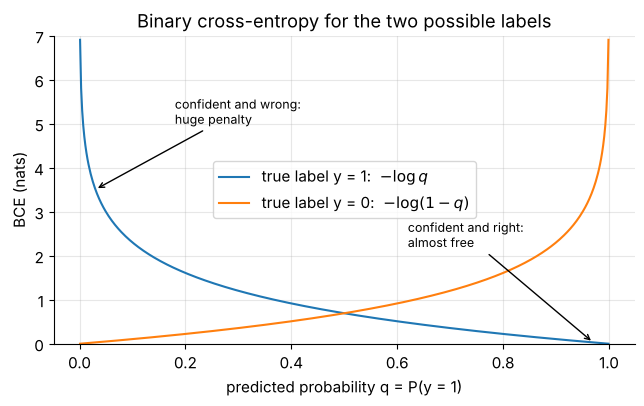

In [49]:
q_axis = np.linspace(0.001, 0.999, 500)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(q_axis, bce(1, q_axis), label="true label y = 1:  $-\\log q$")
ax.plot(q_axis, bce(0, q_axis), label="true label y = 0:  $-\\log(1-q)$")
ax.annotate("confident and wrong:\nhuge penalty", (0.03, bce(1, 0.03)), xytext=(0.18, 5.0),
            arrowprops={"arrowstyle": "->"}, fontsize=9)
ax.annotate("confident and right:\nalmost free", (0.97, bce(1, 0.97)), xytext=(0.62, 2.2),
            arrowprops={"arrowstyle": "->"}, fontsize=9)
ax.set_ylim(0, 7)
ax.set_xlabel("predicted probability q = P(y = 1)")
ax.set_ylabel("BCE (nats)")
ax.set_title("Binary cross-entropy for the two possible labels")
ax.legend(loc="center")
plt.show()

### 8.3 Categorical cross-entropy with one-hot labels

With $K > 2$ classes the model outputs a whole probability vector $\mathbf{q} = (q_1, \dots, q_K)$, and the label is stored as a one-hot vector $\mathbf{y}$ (Section 2.4). The cross-entropy between them is the **categorical cross-entropy (CCE)**:

$$
\operatorname{CE}(\mathbf{y}, \mathbf{q}) = -\sum_{k=1}^{K} y_k \log q_k = -\log q_c \qquad (c = \text{the correct class}).
$$

**Worked example.** A fruit classifier sees a photo and outputs $\mathbf{q} = (0.05, 0.62, 0.25, 0.08)$ for (apple, banana, cherry, grape). The photo shows a banana, so $\mathbf{y} = (0, 1, 0, 0)$:

$$
\operatorname{CE} = -\big[0\cdot\log 0.05 + 1\cdot\log 0.62 + 0\cdot\log 0.25 + 0\cdot\log 0.08\big] = -\log 0.62 \approx 0.4780 \text{ nats}.
$$

**For a batch**, stack the $N$ one-hot labels into $\mathbf{Y} \in \{0,1\}^{N \times K}$ and the predictions into $\mathbf{Q} \in (0, 1]^{N \times K}$ (each row sums to one). The loss is

$$
J = -\frac{1}{N}\sum_{i=1}^{N}\sum_{k=1}^{K} Y_{ik}\log Q_{ik} = -\frac1N \sum_{i=1}^N \log Q_{i,\,y_i}.
$$

In code, the right-hand form is computed by **indexing**, `Q[np.arange(N), labels]`, which picks the predicted probability of the correct class in each row. Libraries accept the labels either as integer indices ("sparse" labels) or as one-hot/probability rows.

In [50]:
def categorical_ce(Y_onehot, Q):
    """Mean categorical cross-entropy for one-hot (or soft) targets Y and predictions Q, both (N, K)."""
    return float(-np.mean(np.sum(Y_onehot * np.log(Q), axis=1)))


Q_batch = np.array([[0.05, 0.62, 0.25, 0.08],      # four photos, predicted (apple, banana, cherry, grape)
                    [0.72, 0.10, 0.13, 0.05],
                    [0.02, 0.03, 0.90, 0.05],
                    [0.30, 0.30, 0.10, 0.30]])
labels_batch = np.array([1, 0, 2, 3])               # banana, apple, cherry, grape
Y_batch = np.eye(4)[labels_batch]

per_example = -np.log(Q_batch[np.arange(4), labels_batch])
print("per-example CE:", per_example.round(4))
print(f"one-hot sum form: {categorical_ce(Y_batch, Q_batch):.6f} | indexing form: {per_example.mean():.6f}")
print(f"sklearn log_loss: {log_loss(labels_batch, Q_batch):.6f}")
print(f"torch nll_loss(log Q): {F.nll_loss(torch.log(torch.tensor(Q_batch)), torch.tensor(labels_batch)).item():.6f}")

per-example CE: [0.478  0.3285 0.1054 1.204 ]
one-hot sum form: 0.528968 | indexing form: 0.528968
sklearn log_loss: 0.528968
torch nll_loss(log Q): 0.528968


**Binary cross-entropy is the $K = 2$ case.** With classes (0, 1), the prediction $(1 - q, q)$ and the one-hot label $(1 - y, y)$, the categorical formula gives $-\big[(1-y)\log(1-q) + y\log q\big]$, which is exactly BCE. You may therefore train a binary classifier either with one output and BCE or with two outputs and CCE.

**Only the correct class's probability appears.** The two predictions $(0.05, 0.62, 0.25, 0.08)$ and $(0.13, 0.62, 0.12, 0.13)$ for a banana photo have *the same* cross-entropy, $-\log 0.62$, however the remaining $38\%$ is spread. The other probabilities still matter indirectly: because $\mathbf{q}$ must sum to one, raising $q_c$ forces the others down. (A score with this property is called *local*, and a score like the squared error $\sum_k (q_k - y_k)^2$ is not local.)

In [51]:
q_other = np.array([0.13, 0.62, 0.12, 0.13])
y_banana = np.eye(4)[1]
for q_vec in (q_fruit, q_other):
    print(f"q = {q_vec}:  CE = {-np.log(q_vec[1]):.4f}   squared error = {np.sum((q_vec - y_banana) ** 2):.4f}")

two_class_Q = np.column_stack([1 - q_photos, q_photos])     # (P(no bird), P(bird)) for the six photos
print(f"BCE = {bce(y_photos, q_photos).mean():.6f} | two-class CCE = {categorical_ce(np.eye(2)[y_photos], two_class_Q):.6f}")

q = [0.05 0.62 0.25 0.08]:  CE = 0.4780   squared error = 0.2158
q = [0.13 0.62 0.12 0.13]:  CE = 0.4780   squared error = 0.1926
BCE = 0.590905 | two-class CCE = 0.590905


**Multi-class or multi-label?** Choose the output layer and loss by asking whether the classes are mutually exclusive:

| task | example | outputs | loss |
|---|---|---|---|
| binary | spam or not | 1 logit $\to$ sigmoid | BCE |
| multi-class: exactly one of $K$ classes | which digit, which species | $K$ logits $\to$ softmax | categorical CE |
| multi-label: any subset of $K$ tags | photo contains {person, dog, bicycle} | $K$ logits $\to$ $K$ independent sigmoids | BCE on each tag, averaged |

A multi-label target such as $(1, 0, 1)$ is *not* a probability distribution (it sums to 2), so softmax cross-entropy would be the wrong model. Treat each tag as its own yes/no question instead.

In [52]:
tag_names = ["person", "dog", "bicycle"]
Y_tags = torch.tensor([[1.0, 0.0, 1.0],          # photo 1: a person riding a bicycle
                       [0.0, 1.0, 0.0]])         # photo 2: just a dog
Z_tags = torch.tensor([[2.0, -1.0, 0.5],         # model logits: one per tag, no softmax across tags
                       [-1.5, 3.0, -2.0]])
per_tag = F.binary_cross_entropy_with_logits(Z_tags, Y_tags, reduction="none")
print("independent tag probabilities:\n", torch.sigmoid(Z_tags).numpy().round(3))
print("BCE per (photo, tag):\n", per_tag.numpy().round(4))
print(f"multi-label loss (mean over all entries): {per_tag.mean().item():.4f}")

independent tag probabilities:
 [[0.881 0.269 0.622]
 [0.182 0.953 0.119]]
BCE per (photo, tag):
 [[0.1269 0.3133 0.4741]
 [0.2014 0.0486 0.1269]]
multi-label loss (mean over all entries): 0.2152


### 8.4 Soft labels and label smoothing

Nothing in the definition $H(P, Q) = -\sum_y p(y)\log q(y)$ requires the target $P$ to be one-hot. Targets that spread probability over several classes are called **soft labels**, and they arise naturally:

* **Annotator disagreement.** Seven people label a blurry photo: five say "cat", two say "fox". The honest target is $(\tfrac57, \tfrac27, 0)$ for (cat, fox, dog).
* **Knowledge distillation.** A small "student" network is trained to match the full probability vector of a large "teacher" network, which carries more information than the teacher's top class alone.
* **Label smoothing**, a regularization trick discussed below.

With a soft target $\mathbf{p}$, the decomposition of Section 7 tells us everything: $H(\mathbf{p}, \mathbf{q}) = H(\mathbf{p}) + D_{\mathrm{KL}}(\mathbf{p}\Vert\mathbf{q})$. The loss is minimized by predicting $\mathbf{q} = \mathbf{p}$, and its **minimum value is $H(\mathbf{p}) > 0$**. For the blurry photo the best possible loss is $H(\tfrac57, \tfrac27) \approx 0.5983$ nats, so do not expect the training loss to reach zero on soft labels.

**Label smoothing.** With one-hot targets something odd happens: the loss $-\log q_c$ can be pushed toward $0$ but never reaches it, because $q_c = \operatorname{softmax}(\mathbf{z})_c < 1$ for any finite logits $\mathbf{z}$. Gradient descent keeps increasing the gap between the correct logit and the others forever, and the model becomes ever more confident. Label smoothing replaces the one-hot target by a mixture with the uniform distribution:

$$
\mathbf{y}^{\text{LS}} = (1 - \varepsilon)\,\mathbf{e}_c + \frac{\varepsilon}{K}\,\mathbf{1},
\qquad\text{i.e.}\qquad
y^{\text{LS}}_k = \begin{cases} 1 - \varepsilon + \varepsilon/K & k = c \\ \varepsilon/K & k \ne c. \end{cases}
$$

With $K = 4$ and $\varepsilon = 0.1$, the target for class $c$ becomes $0.925$ and every other class gets $0.025$. Now the optimum is the *finite* prediction $\mathbf{q} = \mathbf{y}^{\text{LS}}$. Since $\operatorname{softmax}(\mathbf{z}) = \mathbf{y}^{\text{LS}}$ exactly when $z_k = \log y^{\text{LS}}_k + \text{const}$, the optimal logit gap is

$$
z_c - z_j = \log\frac{1 - \varepsilon + \varepsilon/K}{\varepsilon/K} = \log\frac{0.925}{0.025} = \log 37 \approx 3.6109 ,
$$

and the loss cannot fall below $H(\mathbf{y}^{\text{LS}})$. Let us train the logits of a single example both ways.

In [53]:
K_ls, c_ls, eps_ls = 4, 1, 0.1
traces = {}
for name, smoothing in [("one-hot target", 0.0), ("label smoothing eps = 0.1", eps_ls)]:
    z = torch.zeros(K_ls, dtype=torch.float64, requires_grad=True)
    opt = torch.optim.SGD([z], lr=1.0)
    losses, gaps = [], []
    for step in range(2000):
        loss = F.cross_entropy(z[None], torch.tensor([c_ls]), label_smoothing=smoothing)
        losses.append(loss.item())
        gaps.append((z[c_ls] - torch.cat([z[:c_ls], z[c_ls + 1:]]).max()).item())   # correct logit minus best rival
        opt.zero_grad()
        loss.backward()
        opt.step()
    traces[name] = (np.array(losses), np.array(gaps))

y_ls_vec = np.full(K_ls, eps_ls / K_ls)
y_ls_vec[c_ls] += 1 - eps_ls
print("smoothed target:", y_ls_vec, "| loss floor H(y_LS) =", round(entropy(y_ls_vec), 6),
      "| optimal gap log 37 =", round(np.log(37), 4))
for name, (losses, gaps) in traces.items():
    print(f"{name:<27}: loss after 2000 steps = {losses[-1]:.6f}, logit gap = {gaps[-1]:.4f}")

smoothed target: [0.025 0.925 0.025 0.025] | loss floor H(y_LS) = 0.34878 | optimal gap log 37 = 3.6109
one-hot target             : loss after 2000 steps = 0.000376, logit gap = 8.9854
label smoothing eps = 0.1  : loss after 2000 steps = 0.348780, logit gap = 3.6109


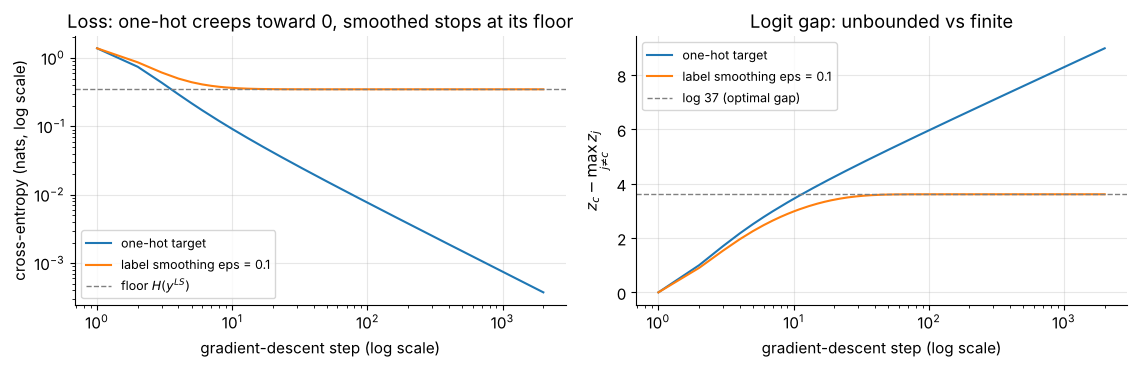

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
steps_ls = np.arange(1, 2001)
for name, (losses, gaps) in traces.items():
    axes[0].plot(steps_ls, losses, label=name)
    axes[1].plot(steps_ls, gaps, label=name)
axes[0].axhline(entropy(y_ls_vec), color="gray", ls="--", lw=1, label="floor $H(y^{LS})$")
axes[1].axhline(np.log(37), color="gray", ls="--", lw=1, label="log 37 (optimal gap)")
axes[0].set_yscale("log")
axes[0].set_title("Loss: one-hot creeps toward 0, smoothed stops at its floor")
axes[0].set_ylabel("cross-entropy (nats, log scale)")
axes[1].set_title("Logit gap: unbounded vs finite")
axes[1].set_ylabel("$z_c - \\max_{j \\neq c} z_j$")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("gradient-descent step (log scale)")
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

With the one-hot target the logit gap keeps climbing (it grows roughly like the logarithm of the number of steps) while the loss creeps toward zero. With smoothing, the gap converges to $\log 37$ and the loss to its floor $H(\mathbf{y}^{\text{LS}}) \approx 0.3488$ nats. In real networks, label smoothing often improves calibration and generalization slightly, because it penalizes extreme logits. It is not free, though: it deliberately trains the model to be *less* than certain even on easy examples, and it is known to interact badly with knowledge distillation.

> **Common pitfall.** Comparing loss values across settings. A model trained with label smoothing (or on soft labels) can never reach a loss below $H(\text{target})$, so its training loss looks "worse" even when its accuracy is better. Always compare models with the **same** evaluation loss on one-hot test labels.

PyTorch's `F.cross_entropy(..., label_smoothing=eps)` implements exactly the mixture $(1-\varepsilon)\mathbf{e}_c + \tfrac{\varepsilon}{K}\mathbf{1}$, as this check confirms:

In [55]:
z_check = torch.randn(5, 4, dtype=torch.float64, generator=torch.Generator().manual_seed(0))
y_check = torch.tensor([0, 3, 1, 2, 1])
soft_targets = (1 - eps_ls) * F.one_hot(y_check, 4).double() + eps_ls / 4
manual = -(soft_targets * F.log_softmax(z_check, dim=1)).sum(dim=1).mean()
print(f"torch label_smoothing=0.1: {F.cross_entropy(z_check, y_check, label_smoothing=eps_ls).item():.8f}")
print(f"soft-target cross-entropy: {manual.item():.8f}")

torch label_smoothing=0.1: 2.00215635
soft-target cross-entropy: 2.00215635


### ✏️ Exercise 6: smoothed targets and their loss floor

(a) Write `smooth_labels(labels, num_classes, eps)` returning the $(N, K)$ array of smoothed targets $(1-\varepsilon)\mathbf{e}_{y_i} + \tfrac{\varepsilon}{K}\mathbf{1}$.
(b) Write `smoothed_loss_floor(num_classes, eps)` returning, in nats, the smallest cross-entropy any model can achieve against one such target. (Hint: Section 8.4. A closed-form expression is possible, but mind the case $\varepsilon = 0$, where $0 \log 0 = 0$, and you may also reuse part (a).)

In [56]:
# ✏️ Exercise 6: label smoothing
def smooth_labels(labels, num_classes, eps):
    """Return an (N, num_classes) array: (1 - eps) * one_hot(labels) + eps / num_classes."""
    # YOUR CODE HERE
    raise NotImplementedError


def smoothed_loss_floor(num_classes, eps):
    """Return the minimum possible cross-entropy (nats) against one smoothed target."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex6():
    T = smooth_labels(np.array([1, 0, 2]), 4, 0.1)
    assert np.shape(T) == (3, 4), f"expected shape (3, 4), got {np.shape(T)}"
    assert np.allclose(T.sum(axis=1), 1.0), "each smoothed target must sum to 1"
    assert np.allclose(T[0], [0.025, 0.925, 0.025, 0.025]), f"row 0 should be [0.025, 0.925, 0.025, 0.025], got {T[0]}"
    assert np.allclose(smooth_labels(np.array([2]), 3, 0.0), [[0, 0, 1]]), "eps = 0 must give one-hot rows"
    t_rng = np.random.default_rng(5)
    Z, lab = t_rng.normal(size=(6, 5)), t_rng.integers(0, 5, size=6)
    soft = torch.tensor(smooth_labels(lab, 5, 0.2))
    mine = -(soft * F.log_softmax(torch.tensor(Z), dim=1)).sum(dim=1).mean().item()
    ref = F.cross_entropy(torch.tensor(Z), torch.tensor(lab), label_smoothing=0.2).item()
    assert np.isclose(mine, ref), "soft targets do not reproduce torch's label_smoothing loss"
    assert np.isclose(smoothed_loss_floor(4, 0.1), 0.348780, atol=1e-6), f"got {smoothed_loss_floor(4, 0.1)}"
    assert np.isclose(smoothed_loss_floor(10, 0.0), 0.0, atol=1e-12), "no smoothing means the floor is 0"
    assert np.isclose(smoothed_loss_floor(3, 1.0), np.log(3)), "eps = 1 gives the uniform target"


run_check("Exercise 6", _test_ex6)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def smooth_labels(labels, num_classes, eps):
    onehot = np.eye(num_classes)[np.asarray(labels)]
    return (1 - eps) * onehot + eps / num_classes

def smoothed_loss_floor(num_classes, eps):
    target = smooth_labels(np.array([0]), num_classes, eps)[0]
    target = target[target > 0]                 # 0 log 0 = 0
    return float(-np.sum(target * np.log(target)))
```
The floor is the entropy of the target, because $H(\mathbf{p}, \mathbf{q}) = H(\mathbf{p}) + D_{\mathrm{KL}}(\mathbf{p}\Vert\mathbf{q}) \ge H(\mathbf{p})$ with equality at $\mathbf{q} = \mathbf{p}$. In closed form: $-(1-\varepsilon+\tfrac{\varepsilon}{K})\log(1-\varepsilon+\tfrac{\varepsilon}{K}) - (K-1)\tfrac{\varepsilon}{K}\log\tfrac{\varepsilon}{K}$. If you code this closed form directly, remember that $\varepsilon = 0$ turns its second term into $0 \cdot \log 0$: `np.log` then produces `nan` and the checker's $\varepsilon = 0$ case fails. Use `scipy.special.xlogy(t, t)` (which returns $0$ at $t = 0$) or treat $\varepsilon = 0$ separately.
</details>

### 8.5 Why not mean squared error?

Squared error works beautifully for regression, so why not train a classifier with $(q - y)^2$? Compare the two losses for one example with a sigmoid output $q = \sigma(z) = \frac{1}{1 + e^{-z}}$, whose derivative is $\sigma'(z) = \sigma(z)\big(1 - \sigma(z)\big)$.

* **Cross-entropy.** $L_{\text{CE}} = -\big[y\log\sigma(z) + (1-y)\log(1-\sigma(z))\big]$. By the chain rule, $\frac{d}{dz}\big[-y\log\sigma(z)\big] = -y\,\frac{\sigma(1-\sigma)}{\sigma} = -y(1-\sigma)$ and $\frac{d}{dz}\big[-(1-y)\log(1-\sigma(z))\big] = (1-y)\,\frac{\sigma(1-\sigma)}{1-\sigma} = (1-y)\,\sigma$. Adding them,

$$
\frac{\partial L_{\text{CE}}}{\partial z} = -y + y\sigma + \sigma - y\sigma = \sigma(z) - y = q - y .
$$

* **Squared error.** $L_{\text{MSE}} = (\sigma(z) - y)^2$, so

$$
\frac{\partial L_{\text{MSE}}}{\partial z} = 2\,(q - y)\cdot q\,(1 - q).
$$

The difference is the extra factor $q(1-q)$. Suppose the true label is $y = 1$ but the model is *confidently wrong*, say $z = -8$ so $q \approx 0.000335$. Cross-entropy's gradient is $q - 1 \approx -0.9997$: a full-strength push in the right direction. Squared error's gradient is $2(q-1)\,q(1-q) \approx -0.00067$, about 1500 times weaker. **The squared error stops learning exactly when the model is most wrong**, because the sigmoid is flat there and nothing in the loss compensates. The logarithm in cross-entropy cancels the sigmoid's flatness exactly.

y = 1, z =  -8.0: q = 0.000335 | dCE/dz = -0.999665 | dMSE/dz = -0.000670
y = 1, z =  -4.0: q = 0.017986 | dCE/dz = -0.982014 | dMSE/dz = -0.034690
y = 1, z =   0.0: q = 0.500000 | dCE/dz = -0.500000 | dMSE/dz = -0.250000


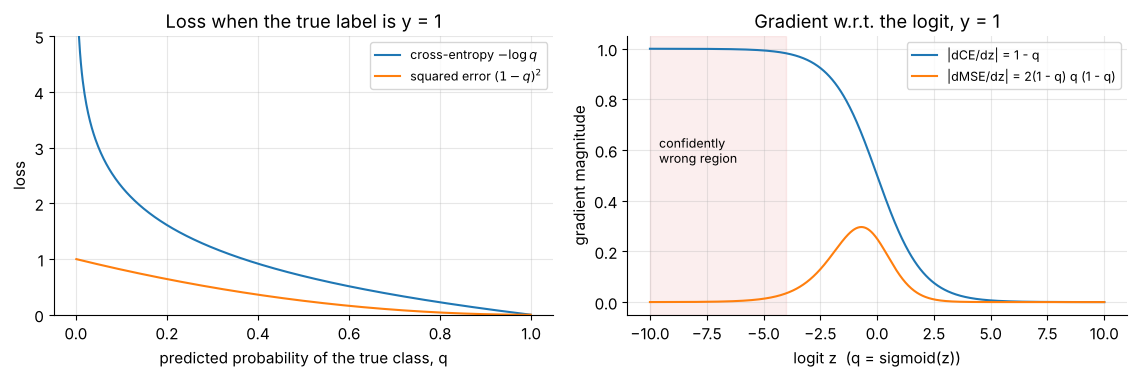

In [57]:
z_axis = np.linspace(-10, 10, 801)
q_of_z = special.expit(z_axis)                       # sigmoid
grad_ce = q_of_z - 1                                 # y = 1
grad_mse = 2 * (q_of_z - 1) * q_of_z * (1 - q_of_z)

for z0 in (-8.0, -4.0, 0.0):
    q0 = special.expit(z0)
    print(f"y = 1, z = {z0:>5}: q = {q0:.6f} | dCE/dz = {q0 - 1:+.6f} | dMSE/dz = {2 * (q0 - 1) * q0 * (1 - q0):+.6f}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
axes[0].plot(q_axis, -np.log(q_axis), label="cross-entropy $-\\log q$")
axes[0].plot(q_axis, (1 - q_axis) ** 2, label="squared error $(1-q)^2$")
axes[0].set_ylim(0, 5)
axes[0].set_xlabel("predicted probability of the true class, q")
axes[0].set_ylabel("loss")
axes[0].set_title("Loss when the true label is y = 1")
axes[1].plot(z_axis, np.abs(grad_ce), label="|dCE/dz| = 1 - q")
axes[1].plot(z_axis, np.abs(grad_mse), label="|dMSE/dz| = 2(1 - q) q (1 - q)")
axes[1].axvspan(-10, -4, color="tab:red", alpha=0.08)
axes[1].text(-9.6, 0.55, "confidently\nwrong region", fontsize=9)
axes[1].set_xlabel("logit z  (q = sigmoid(z))")
axes[1].set_ylabel("gradient magnitude")
axes[1].set_title("Gradient w.r.t. the logit, y = 1")
for ax in axes:
    ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

**An experiment.** One feature $x$, two classes (class 0 centered at $-1.5$, class 1 at $+1.5$), and the model $q = \sigma(wx + b)$. We start from a terrible initialization, $w = -4$: the model is confidently wrong on almost every example. Then we run the same gradient descent (learning rate $0.5$, full batch) twice, once on the mean cross-entropy and once on the mean squared error.

In [58]:
exp_rng = np.random.default_rng(7)                        # local RNG: this experiment is self-contained
n_half = 200
x_1d = np.concatenate([exp_rng.normal(-1.5, 1.0, n_half), exp_rng.normal(1.5, 1.0, n_half)])
y_1d = np.concatenate([np.zeros(n_half), np.ones(n_half)])


def train_1d(loss_name, w0=-4.0, b0=0.0, lr=0.5, n_steps=300):
    """Full-batch gradient descent on q = sigmoid(w x + b). Returns a history of (loss, accuracy, w)."""
    w, b = w0, b0
    history = []
    for _ in range(n_steps + 1):
        z = w * x_1d + b
        q = special.expit(z)
        if loss_name == "CE":
            loss = np.mean(np.logaddexp(0, z) - y_1d * z)      # stable BCE from logits (Section 9.3)
            dz = q - y_1d                                       # dLoss/dz per example
        else:
            loss = np.mean((q - y_1d) ** 2)
            dz = 2 * (q - y_1d) * q * (1 - q)
        history.append((loss, np.mean((q > 0.5) == y_1d), w))
        w -= lr * np.mean(dz * x_1d)                            # chain rule: dz/dw = x
        b -= lr * np.mean(dz)                                   # dz/db = 1
    return np.array(history)


hist_ce, hist_mse = train_1d("CE"), train_1d("MSE")
checkpoints = [0, 5, 10, 20, 50, 100, 150, 200, 300]
display(pd.DataFrame({"CE: accuracy": hist_ce[checkpoints, 1], "CE: w": hist_ce[checkpoints, 2],
                      "MSE: accuracy": hist_mse[checkpoints, 1], "MSE: w": hist_mse[checkpoints, 2]},
                     index=pd.Index(checkpoints, name="step")).round(3))
for name, h in [("CE", hist_ce), ("MSE", hist_mse)]:
    print(f"{name}: first step with accuracy > 0.9: {int(np.argmax(h[:, 1] > 0.9))}")

,CE: accuracy,CE: w,MSE: accuracy,MSE: w
step,,,,
0,0.050,-4.000,0.050,-4.000
5,0.050,-0.329,0.050,-3.954
10,0.950,0.970,0.050,-3.906
20,0.952,1.618,0.048,-3.805
50,0.948,2.327,0.048,-3.455
100,0.948,2.814,0.060,-2.517
150,0.950,3.071,0.938,1.136
200,0.950,3.233,0.945,1.748
300,0.948,3.421,0.948,2.204


CE: first step with accuracy > 0.9: 6
MSE: first step with accuracy > 0.9: 142


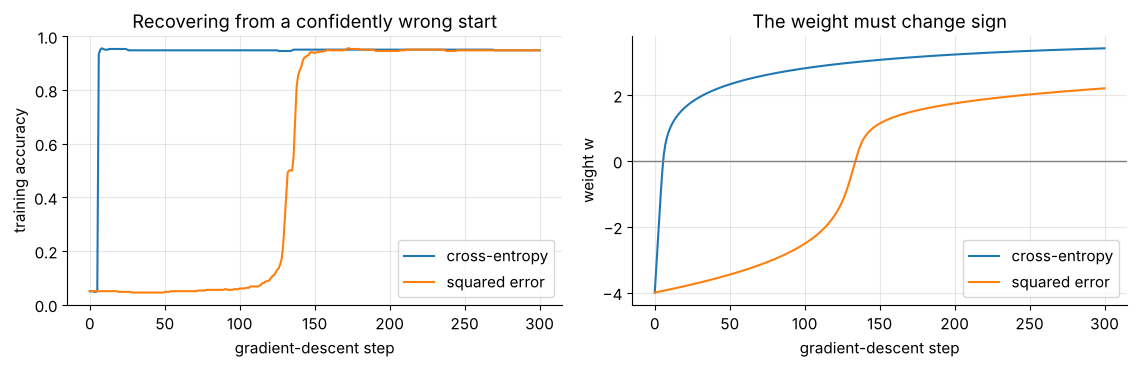

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))
for name, h in [("cross-entropy", hist_ce), ("squared error", hist_mse)]:
    axes[0].plot(h[:, 1], label=name)
    axes[1].plot(h[:, 2], label=name)
axes[0].set_ylabel("training accuracy")
axes[0].set_title("Recovering from a confidently wrong start")
axes[1].axhline(0, color="gray", lw=1)
axes[1].set_ylabel("weight w")
axes[1].set_title("The weight must change sign")
for ax in axes:
    ax.set_xlabel("gradient-descent step")
    ax.legend()
fig.tight_layout()
plt.show()

Cross-entropy flips the sign of $w$ and fixes the classifier within about ten steps. Squared error crawls along a nearly flat plateau, because almost every example sits in the region where $q(1-q) \approx 0$, and only escapes after well over a hundred steps. Three further reasons favor cross-entropy for classification:

1. **It is the right likelihood.** Minimizing squared error is maximum likelihood for *Gaussian* noise around a real-valued target (that is why it suits regression). Labels in $\{0, 1\}$ are Bernoulli, and the Bernoulli likelihood gives cross-entropy (Section 8.2).
2. **Convexity.** For logistic regression ($q = \sigma(\mathbf{w}^\top\mathbf{x} + b)$) the mean cross-entropy is a convex function of $(\mathbf{w}, b)$, so gradient descent cannot get stuck in a bad local minimum. The squared error composed with a sigmoid is not convex and has the plateaus we just saw.
3. **It punishes confident mistakes without limit.** The squared error of a probability is at most $1$, so a 99.99% wrong answer costs barely more than a 90% wrong one, and the log-loss distinguishes them sharply.

The squared error between probabilities and one-hot labels (the **Brier score**) is still a perfectly reasonable *evaluation* metric, and it is just a poor *training* loss with sigmoid or softmax outputs.

**Quick check.** A sigmoid classifier outputs $q = 0.9$ for an example whose label is $y = 0$. What is $\partial L/\partial z$ for the cross-entropy loss? For the squared error?

<details>
<summary>Answer</summary>

Cross-entropy: $q - y = 0.9$. Squared error: $2(q - y)\,q(1-q) = 2(0.9)(0.9)(0.1) = 0.162$. Both point in the right direction (decrease $z$), but the cross-entropy push is more than five times stronger, and the ratio grows without bound as the mistake becomes more confident.
</details>

## 9. Cross-entropy from logits: stable numerics and gradients

Real models do not output probabilities directly. The last layer of a network produces unconstrained real numbers called **logits**, $\mathbf{z} \in \mathbb{R}^K$ (one per class), and a final function turns them into probabilities. This section shows how to go from logits to the loss **without ever computing a dangerous intermediate value**, and derives the gradient that drives all of training.

### 9.1 The softmax function

$$
\operatorname{softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}, \qquad k = 1, \dots, K.
$$

The exponential makes every entry positive and the division makes them sum to one, so the output is a point of the simplex $\Delta^{K-1}$. Larger logits get larger probabilities, and logit *differences* are log-odds: $z_i - z_j = \log(q_i / q_j)$. Two facts to keep:

* **Shift invariance.** Adding the same constant $c$ to every logit changes nothing: $\frac{e^{z_k + c}}{\sum_j e^{z_j + c}} = \frac{e^{c}\,e^{z_k}}{e^{c}\sum_j e^{z_j}}$. Only the differences between logits matter.
* **The sigmoid is a two-class softmax.** With $K = 2$, $\operatorname{softmax}(z_0, z_1)_1 = \frac{e^{z_1}}{e^{z_0} + e^{z_1}} = \frac{1}{1 + e^{-(z_1 - z_0)}} = \sigma(z_1 - z_0)$. A binary classifier's single logit $z$ plays the role of the difference $z_1 - z_0$.

Shift invariance is also the cure for overflow: computing $e^{1000}$ gives `inf`, and `inf / inf` is `nan`. Subtracting $\max_j z_j$ first (exactly as in the log-sum-exp trick of Section 3.5) leaves the result unchanged and keeps every exponent $\le 0$.

In [60]:
def softmax_naive(z):
    """exp(z) / sum(exp(z)) taken literally (overflows for large logits)."""
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)


def softmax(z):
    """Numerically stable softmax along the last axis (subtract the row maximum first)."""
    z = np.asarray(z, dtype=float)
    e = np.exp(z - z.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


for logits in ([1.0, 2.0, 3.0], [1000.0, 1001.0, 1002.0], [-1000.0, -1001.0, -1002.0]):
    logits = np.array(logits)
    with np.errstate(over="ignore", invalid="ignore"):          # the naive version is *expected* to fail
        naive = softmax_naive(logits)
    print(f"z = {str(logits):<24} naive: {np.round(naive, 4)}   stable: {np.round(softmax(logits), 4)}   "
          f"scipy: {np.round(special.softmax(logits), 4)}")
print("shift invariance:", np.allclose(softmax(np.array([1.0, 2.0, 3.0])), softmax(np.array([1.0, 2.0, 3.0]) + 57.0)))
print(f"sigmoid(z1 - z0) = {special.expit(2.0 - 0.5):.6f}  vs  softmax([0.5, 2.0])[1] = {softmax(np.array([0.5, 2.0]))[1]:.6f}")

z = [1. 2. 3.]               naive: [0.09   0.2447 0.6652]   stable: [0.09   0.2447 0.6652]   scipy: [0.09   0.2447 0.6652]
z = [1000. 1001. 1002.]      naive: [nan nan nan]   stable: [0.09   0.2447 0.6652]   scipy: [0.09   0.2447 0.6652]
z = [-1000. -1001. -1002.]   naive: [nan nan nan]   stable: [0.6652 0.2447 0.09  ]   scipy: [0.6652 0.2447 0.09  ]
shift invariance: True
sigmoid(z1 - z0) = 0.817574  vs  softmax([0.5, 2.0])[1] = 0.817574


**Temperature.** Dividing the logits by a temperature $T > 0$ before the softmax, $\operatorname{softmax}(\mathbf{z}/T)$, controls how peaked the distribution is: $T < 1$ sharpens it (as $T \to 0$ it approaches a one-hot vector on the largest logit), $T > 1$ flattens it (as $T \to \infty$ it approaches the uniform distribution), and the ranking of the classes never changes. Temperature is how language models trade boldness for variety when sampling text, how knowledge distillation softens a teacher's predictions, and (Section 10.4) how we will repair overconfident models.

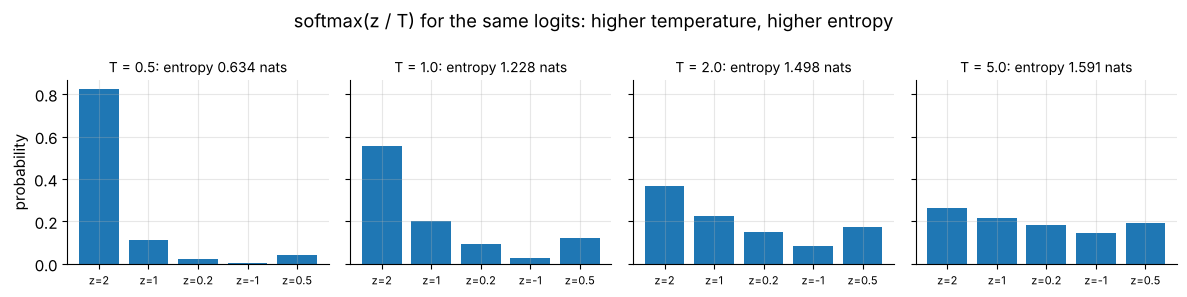

In [61]:
z_temp = np.array([2.0, 1.0, 0.2, -1.0, 0.5])
temps = [0.5, 1.0, 2.0, 5.0]
fig, axes = plt.subplots(1, 4, figsize=(12, 3), sharey=True)
for ax, T in zip(axes, temps):
    q_T = softmax(z_temp / T)
    ax.bar(np.arange(5), q_T, color="tab:blue")
    ax.set_title(f"T = {T}: entropy {entropy(q_T):.3f} nats", fontsize=10)
    ax.set_xticks(np.arange(5), [f"z={v:g}" for v in z_temp], fontsize=8)
axes[0].set_ylabel("probability")
fig.suptitle("softmax(z / T) for the same logits: higher temperature, higher entropy")
fig.tight_layout()
plt.show()

### 9.2 Log-softmax: cross-entropy straight from the logits

Cross-entropy needs $\log q_k$, not $q_k$. Taking the log of the softmax gives a remarkably simple expression, the **log-softmax**:

$$
\log q_k = \log\frac{e^{z_k}}{\sum_j e^{z_j}} = z_k - \log\sum_{j} e^{z_j} = z_k - \operatorname{LSE}(\mathbf{z}).
$$

So the cross-entropy of a one-hot label $c$ is

$$
\operatorname{CE}(c, \mathbf{z}) = -\log q_c = \operatorname{LSE}(\mathbf{z}) - z_c .
$$

Read it as: **how far the correct logit falls short of the "soft maximum" of all logits**. Since $\operatorname{LSE}(\mathbf{z}) \ge \max_j z_j \ge z_c$ (Section 3.5), the loss is never negative, and it is close to $0$ when $z_c$ stands far above every other logit.

**Worked example.** Fruit logits $\mathbf{z} = (1.2, 3.1, 0.4, -0.8)$, true class banana ($z_c = 3.1$). Then $\operatorname{LSE}(\mathbf{z}) = \log(e^{1.2} + e^{3.1} + e^{0.4} + e^{-0.8}) \approx \log(3.320 + 22.198 + 1.492 + 0.449) \approx 3.3127$, so the loss is $3.3127 - 3.1 = 0.2127$ nats, and equivalently $q_{\text{banana}} = e^{-0.2127} \approx 0.8084$.

Why bother? Because the two-step route "softmax, then log" breaks exactly when the model is confident. In `float32` (PyTorch's default), $e^{-120}$ underflows to $0$, so a logit $120$ below the leader gets probability exactly $0$, its log is $-\infty$, the loss is infinite, and backpropagation returns `nan`, which then poisons every weight it touches. Log-softmax never forms the tiny probability, so it simply returns $-120$.

In [62]:
def log_softmax(Z):
    """Row-wise log-softmax z_k - LSE(z), computed stably along the last axis."""
    Z = np.asarray(Z, dtype=float)
    m = Z.max(axis=-1, keepdims=True)
    return Z - (m + np.log(np.sum(np.exp(Z - m), axis=-1, keepdims=True)))


def softmax_cross_entropy(Z, labels):
    """Mean cross-entropy over a batch, from logits Z (N, K) and integer labels (N,)."""
    Z = np.asarray(Z, dtype=float)
    return float(-np.mean(log_softmax(Z)[np.arange(len(Z)), labels]))


z_fruit = np.array([1.2, 3.1, 0.4, -0.8])
print(f"LSE = {special.logsumexp(z_fruit):.4f}, loss = LSE - z_c = {special.logsumexp(z_fruit) - z_fruit[1]:.4f}, "
      f"ours = {softmax_cross_entropy(z_fruit[None], [1]):.4f}, q = {softmax(z_fruit).round(4)}")

z32 = torch.tensor([0.0, 120.0], requires_grad=True)          # float32, class 0 is the true class
loss_naive = -torch.log(torch.softmax(z32, dim=0))[0]
loss_naive.backward()
print(f"float32, log(softmax): loss = {loss_naive.item()}, gradient = {z32.grad.tolist()}")
z32 = torch.tensor([0.0, 120.0], requires_grad=True)
loss_stable = -F.log_softmax(z32, dim=0)[0]
loss_stable.backward()
print(f"float32, log_softmax:  loss = {loss_stable.item()}, gradient = {z32.grad.tolist()}")

LSE = 3.3127, loss = LSE - z_c = 0.2127, ours = 0.2127, q = [0.1209 0.8084 0.0543 0.0164]
float32, log(softmax): loss = inf, gradient = [nan, nan]
float32, log_softmax:  loss = 120.0, gradient = [-1.0, 1.0]


Our NumPy version agrees with PyTorch on ordinary and on extreme logits:

In [63]:
Z_demo = rng.normal(0, 3, size=(6, 5))
labels_demo = rng.integers(0, 5, size=6)
Z_extreme = np.array([[0.0, 800.0, -800.0], [1e4, 0.0, 0.0]])
labels_extreme = np.array([0, 1])
for name, Z_, lab_ in [("random logits", Z_demo, labels_demo), ("extreme logits", Z_extreme, labels_extreme)]:
    ours = softmax_cross_entropy(Z_, lab_)
    ref = F.cross_entropy(torch.tensor(Z_), torch.tensor(lab_)).item()
    print(f"{name:<15}: ours = {ours:.6f}   torch F.cross_entropy = {ref:.6f}")

random logits  : ours = 5.139964   torch F.cross_entropy = 5.139964
extreme logits : ours = 5400.000000   torch F.cross_entropy = 5400.000000


> **Common pitfall.** In PyTorch, `F.cross_entropy` / `nn.CrossEntropyLoss` expect **raw logits** and apply log-softmax internally. Feeding them probabilities (a model that already ends in `softmax`) applies softmax twice, and the loss and its gradients become badly squashed (Section 9.5 measures how badly). Keep the softmax out of the model for training, and apply it only when you need probabilities for reporting.

### 9.3 Binary cross-entropy from a single logit

A binary classifier outputs one logit $z$ and $q = \sigma(z)$. Plugging $q$ into BCE literally, `-(y*log(sigmoid(z)) + (1-y)*log(1-sigmoid(z)))`, fails for large $|z|$: in `float64`, $\sigma(40) = 1 - 4.2 \times 10^{-18}$ rounds to exactly $1.0$, and $\log(1 - 1) = -\infty$.

**Derivation of a stable form.** Let $\operatorname{softplus}(t) = \log(1 + e^{t})$. Two identities do all the work:

$$
\log\sigma(z) = \log\frac{1}{1 + e^{-z}} = -\operatorname{softplus}(-z), \qquad
\log\big(1 - \sigma(z)\big) = \log\frac{e^{-z}}{1 + e^{-z}} = \log\frac{1}{1 + e^{z}} = -\operatorname{softplus}(z).
$$

Hence $\operatorname{BCE}(y, z) = y\operatorname{softplus}(-z) + (1 - y)\operatorname{softplus}(z)$. Since $\operatorname{softplus}(z) = \log\big(e^{z}(e^{-z} + 1)\big) = z + \operatorname{softplus}(-z)$, this simplifies to

$$
\operatorname{BCE}(y, z) = \operatorname{softplus}(z) - y\,z .
$$

Finally, compute softplus without overflow. For $z \ge 0$, $\operatorname{softplus}(z) = z + \log(1 + e^{-z})$, and for $z < 0$, $\operatorname{softplus}(z) = \log(1 + e^{z})$. Both cases are $\max(z, 0) + \log\big(1 + e^{-|z|}\big)$, where the exponent is never positive:

$$
\boxed{\;\operatorname{BCE}(y, z) = \max(z, 0) - y\,z + \log\big(1 + e^{-|z|}\big)\;}
$$

This is exactly what `torch.nn.functional.binary_cross_entropy_with_logits` computes. (Use `np.log1p(x)` for $\log(1 + x)$: it stays accurate when $x$ is tiny.)

In [64]:
def bce_from_logits_naive(y, z):
    """Sigmoid first, then the BCE formula: breaks for large |z|."""
    q = special.expit(z)
    return -(y * np.log(q) + (1 - y) * np.log(1 - q))


def bce_from_logits(y, z):
    """Stable BCE from logits: max(z, 0) - y z + log(1 + exp(-|z|)), elementwise."""
    y, z = np.asarray(y, dtype=float), np.asarray(z, dtype=float)
    return np.maximum(z, 0) - y * z + np.log1p(np.exp(-np.abs(z)))


cases = pd.DataFrame({"z": [3.0, -3.0, 40.0, 40.0, -40.0, -40.0], "y": [1, 1, 1, 0, 1, 0]})
zc, yc = cases["z"].to_numpy(), cases["y"].to_numpy().astype(float)
with np.errstate(divide="ignore", invalid="ignore"):            # the naive formula is expected to fail
    cases["naive (sigmoid, then log)"] = bce_from_logits_naive(yc, zc)
cases["stable (ours)"] = bce_from_logits(yc, zc)
cases["torch with_logits"] = F.binary_cross_entropy_with_logits(torch.tensor(zc), torch.tensor(yc), reduction="none").numpy()
cases["torch BCE on sigmoid(z)"] = F.binary_cross_entropy(torch.sigmoid(torch.tensor(zc)), torch.tensor(yc), reduction="none").numpy()
cases["sklearn log_loss"] = [log_loss([int(y_)], [special.expit(z_)], labels=[0, 1]) for z_, y_ in zip(zc, yc)]
display(cases.round(4))

,z,y,"naive (sigmoid, then log)",stable (ours),torch with_logits,torch BCE on sigmoid(z),sklearn log_loss
0,3.0,1,0.0486,0.0486,0.0486,0.0486,0.0486
1,-3.0,1,3.0486,3.0486,3.0486,3.0486,3.0486
2,40.0,1,NaN,0.0000,0.0000,-0.0000,0.0000
3,40.0,0,inf,40.0000,40.0000,100.0000,36.0437
4,-40.0,1,40.0000,40.0000,40.0000,40.0000,36.0437
5,-40.0,0,-0.0000,0.0000,0.0000,0.0000,0.0000


Read the table row by row. For moderate logits every method agrees. For $z = 40, y = 0$ (very confident and wrong) the true loss is $40 + \log(1 + e^{-40}) \approx 40$:

* the naive formula returns `inf` because $\sigma(40)$ rounded to $1$,
* `F.binary_cross_entropy` on probabilities returns $100$, because PyTorch clamps $\log$ at $-100$ as a safety net,
* `sklearn.metrics.log_loss` returns about $36.04$, because it clips probabilities to $[\epsilon, 1 - \epsilon]$ with $\epsilon \approx 2.2 \times 10^{-16}$ (machine epsilon) and $-\log \epsilon \approx 36.04$,
* only the logit-based formulas give the correct $40$.

The clamps and clips keep training from crashing, but they report the wrong number and (for PyTorch's clamp) give zero gradient in the clamped region. For $z = -40, y = 1$, $\sigma(-40) \approx 4.2 \times 10^{-18}$ is still representable in `float64`, so the probability route happens to work there, yet `log_loss` still clips it to $36.04$.

> **Key idea.** Pass **logits** to the loss: `F.cross_entropy(logits, labels)` for multi-class, `F.binary_cross_entropy_with_logits(logit, y)` for binary/multi-label. Convert to probabilities only for reporting.

### ✏️ Exercise 7: stable BCE from logits

Implement `bce_with_logits(z, y)` returning the **elementwise** binary cross-entropy for logits `z` and labels `y` (arrays of the same shape, and `y` may also be soft, any value in $[0, 1]$). It must be finite for $|z| = 1000$ and must not trigger NumPy warnings. Do not call the lesson's `bce_from_logits` or any library loss.

In [65]:
# ✏️ Exercise 7: numerically stable binary cross-entropy from logits
def bce_with_logits(z, y):
    """Elementwise BCE(y, sigmoid(z)) computed stably from logits z."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex7():
    z = np.array([0.0, 2.0, -2.0, 40.0, -40.0, 1000.0, -1000.0])
    y = np.array([1.0, 1.0, 1.0, 0.0, 1.0, 0.0, 0.0])
    with np.errstate(over="raise", divide="raise", invalid="raise"):
        try:
            out = bce_with_logits(z, y)
        except FloatingPointError as err:
            raise AssertionError(f"a floating-point warning occurred ({err}). Avoid exp of large positive numbers")
    assert np.shape(out) == z.shape, f"expected elementwise output of shape {z.shape}"
    assert np.all(np.isfinite(out)), f"outputs must be finite, got {out}"
    expected = [np.log(2), 0.126928, 2.126928, 40.0, 40.0, 1000.0, 0.0]
    assert np.allclose(out, expected, atol=1e-5), f"got {np.round(out, 6)}"
    t_rng = np.random.default_rng(11)
    zz, yy = t_rng.normal(0, 5, 50), t_rng.random(50)          # soft labels too
    ref = F.binary_cross_entropy_with_logits(torch.tensor(zz), torch.tensor(yy), reduction="none").numpy()
    assert np.allclose(bce_with_logits(zz, yy), ref), "disagrees with torch on random inputs"


run_check("Exercise 7", _test_ex7)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def bce_with_logits(z, y):
    z, y = np.asarray(z, dtype=float), np.asarray(y, dtype=float)
    return np.maximum(z, 0) - y * z + np.log1p(np.exp(-np.abs(z)))
```
`np.exp(-np.abs(z))` lies in $(0, 1]$, so it can neither overflow nor make `log1p` see a negative argument. For $z = -1000$ it underflows harmlessly to $0$, and $\log(1 + 0) = 0$ is the correct limit. The formula works unchanged for soft labels $y \in [0, 1]$.
</details>

### 9.4 The gradient: prediction minus target

Training needs $\partial L / \partial \mathbf{z}$, the gradient of the loss with respect to the logits, and backpropagation carries it into the rest of the network. For softmax plus cross-entropy it is beautifully simple.

**Derivation.** Let $\mathbf{y}$ be the target distribution (one-hot or soft, but summing to $1$) and $\mathbf{q} = \operatorname{softmax}(\mathbf{z})$. Using $\log q_i = z_i - \operatorname{LSE}(\mathbf{z})$,

$$
L(\mathbf{z}) = -\sum_{i} y_i \log q_i = -\sum_i y_i z_i + \operatorname{LSE}(\mathbf{z})\sum_i y_i = \operatorname{LSE}(\mathbf{z}) - \mathbf{y}^\top\mathbf{z}.
$$

The derivative of the log-sum-exp is the softmax itself: $\frac{\partial}{\partial z_j}\log\sum_k e^{z_k} = \frac{e^{z_j}}{\sum_k e^{z_k}} = q_j$. Therefore

$$
\boxed{\;\frac{\partial L}{\partial z_j} = q_j - y_j, \qquad \nabla_{\mathbf{z}} L = \mathbf{q} - \mathbf{y}\;}
$$

*Second route, through the softmax Jacobian.* Differentiating $q_i = e^{z_i}/S$ with $S = \sum_k e^{z_k}$ by the quotient rule gives $\frac{\partial q_i}{\partial z_i} = q_i - q_i^2$ and $\frac{\partial q_i}{\partial z_j} = -q_i q_j$ for $j \ne i$, i.e. $\frac{\partial q_i}{\partial z_j} = q_i(\delta_{ij} - q_j)$ with $\delta_{ij} = 1$ if $i = j$ and $0$ otherwise. The chain rule then gives $\frac{\partial L}{\partial z_j} = -\sum_i \frac{y_i}{q_i}\, q_i(\delta_{ij} - q_j) = -y_j + q_j\sum_i y_i = q_j - y_j$, the same answer.

**For a batch** with mean loss $J = \frac1N\sum_i L_i$, logits $\mathbf{Z} \in \mathbb{R}^{N\times K}$, predictions $\mathbf{Q}$ and targets $\mathbf{Y}$ (both $N \times K$): $\nabla_{\mathbf{Z}} J = \frac{1}{N}(\mathbf{Q} - \mathbf{Y})$. **For BCE with a single logit**, the same pattern holds: $\frac{\partial}{\partial z}\operatorname{BCE}(y, z) = \sigma(z) - y$ (Section 8.5).

What this formula tells you:

* The gradient is the **error signal "prediction minus target"**, the same form as the residual in linear regression. Gradient descent lowers the logits of classes that got too much probability and raises the logit of the class that got too little.
* Its entries sum to zero ($\sum_j q_j - \sum_j y_j = 1 - 1$), so it never moves all logits up together, matching shift invariance.
* Each entry lies in $[-1, 1]$, and it does **not** vanish when the model is confidently wrong: if $q_c \to 0$ for the true class, $\partial L/\partial z_c \to -1$. This is the property that squared error lacked in Section 8.5.

Let us verify the formula against PyTorch's automatic differentiation and against finite differences.

In [66]:
Z_g = rng.normal(0, 2, size=(4, 5))
labels_g = np.array([3, 0, 4, 1])
Y_g = np.eye(5)[labels_g]
grad_formula = (softmax(Z_g) - Y_g) / len(Z_g)                     # (Q - Y) / N

Z_t = torch.tensor(Z_g, requires_grad=True)
F.cross_entropy(Z_t, torch.tensor(labels_g)).backward()            # mean loss, autograd
print("max |formula - autograd|          :", np.abs(grad_formula - Z_t.grad.numpy()).max())

Y_soft = rng.dirichlet(np.ones(5), size=4)                         # soft targets work too
Z_t = torch.tensor(Z_g, requires_grad=True)
(-(torch.tensor(Y_soft) * F.log_softmax(Z_t, dim=1)).sum(dim=1).mean()).backward()
print("soft targets, max |formula - autograd|:", np.abs((softmax(Z_g) - Y_soft) / 4 - Z_t.grad.numpy()).max())

h = 1e-6                                                            # central finite differences, one example
z0, c0 = Z_g[0], labels_g[0]
fd = np.array([(softmax_cross_entropy((z0 + h * e)[None], [c0]) - softmax_cross_entropy((z0 - h * e)[None], [c0])) / (2 * h)
               for e in np.eye(5)])
print("finite differences:", fd.round(6))
print("q - y             :", (softmax(z0) - np.eye(5)[c0]).round(6), "| entries sum to", round(float(fd.sum()), 8))

max |formula - autograd|          : 2.7755575615628914e-17
soft targets, max |formula - autograd|: 2.7755575615628914e-17
finite differences: [ 0.0169  0.1888  0.0019 -0.2078  0.0003]
q - y             : [ 0.0169  0.1888  0.0019 -0.2078  0.0003] | entries sum to 0.0


> **Going deeper.** Differentiating once more gives the Hessian of the loss with respect to the logits, $\nabla^2_{\mathbf{z}} L = \operatorname{diag}(\mathbf{q}) - \mathbf{q}\mathbf{q}^\top$, which does not depend on $\mathbf{y}$. For any vector $\mathbf{v}$, $\mathbf{v}^\top\big(\operatorname{diag}(\mathbf{q}) - \mathbf{q}\mathbf{q}^\top\big)\mathbf{v} = \sum_j q_j v_j^2 - \big(\sum_j q_j v_j\big)^2$, which is the *variance* of $v_J$ when the index $J$ is drawn from $\mathbf{q}$, hence $\ge 0$. So the Hessian is positive semidefinite and cross-entropy is a **convex** function of the logits (with a zero-curvature direction $\mathbf{v} = \mathbf{1}$: shift invariance again). Composed with a *linear* model $\mathbf{z} = \mathbf{W}\mathbf{x} + \mathbf{b}$ it stays convex in $(\mathbf{W}, \mathbf{b})$, which is why softmax regression and logistic regression have no bad local minima.

In [67]:
z_h = torch.tensor(Z_g[0])
H_auto = torch.autograd.functional.hessian(lambda z: F.cross_entropy(z[None], torch.tensor([c0])), z_h).numpy()
q_h = softmax(Z_g[0])
print("max |autograd Hessian - (diag(q) - q q^T)|:", np.abs(H_auto - (np.diag(q_h) - np.outer(q_h, q_h))).max())
print("eigenvalues:", np.linalg.eigvalsh(H_auto).round(6), "(all >= 0, one is 0)")

max |autograd Hessian - (diag(q) - q q^T)|: 5.551115123125783e-17
eigenvalues: [0.     0.0003 0.0025 0.0249 0.3087] (all >= 0, one is 0)


### 9.5 Matching the libraries, and the double-softmax trap

Here is one batch of logits pushed through every route we have met. All of them must agree.

In [68]:
Z_lib = rng.normal(0, 2, size=(8, 3))
y_lib = rng.integers(0, 3, size=8)
z_bin = rng.normal(0, 3, size=8)
y_bin = rng.integers(0, 2, size=8)
routes = {
    "multi-class: ours (log-softmax, NumPy)": softmax_cross_entropy(Z_lib, y_lib),
    "multi-class: torch F.cross_entropy(logits, int labels)": F.cross_entropy(torch.tensor(Z_lib), torch.tensor(y_lib)).item(),
    "multi-class: torch F.cross_entropy(logits, one-hot probs)":
        F.cross_entropy(torch.tensor(Z_lib), F.one_hot(torch.tensor(y_lib), 3).double()).item(),
    "multi-class: torch F.nll_loss(F.log_softmax(logits))":
        F.nll_loss(F.log_softmax(torch.tensor(Z_lib), dim=1), torch.tensor(y_lib)).item(),
    "multi-class: sklearn log_loss(softmax probs)": log_loss(y_lib, softmax(Z_lib), labels=[0, 1, 2]),
    "binary: ours (stable formula)": float(bce_from_logits(y_bin, z_bin).mean()),
    "binary: torch F.binary_cross_entropy_with_logits":
        F.binary_cross_entropy_with_logits(torch.tensor(z_bin), torch.tensor(y_bin, dtype=torch.float64)).item(),
    "binary: sklearn log_loss(sigmoid probs)": log_loss(y_bin, special.expit(z_bin), labels=[0, 1]),
}
display(pd.Series(routes, name="mean loss (nats)").round(10).to_frame())

,mean loss (nats)
"multi-class: ours (log-softmax, NumPy)",1.8227
"multi-class: torch F.cross_entropy(logits, int labels)",1.8227
"multi-class: torch F.cross_entropy(logits, one-hot probs)",1.8227
multi-class: torch F.nll_loss(F.log_softmax(logits)),1.8227
multi-class: sklearn log_loss(softmax probs),1.8227
binary: ours (stable formula),1.5235
binary: torch F.binary_cross_entropy_with_logits,1.5235
binary: sklearn log_loss(sigmoid probs),1.5235


Now the trap from Section 9.2: a model whose last layer already applies softmax, fed into `F.cross_entropy`, which applies log-softmax again. Take three classes and logits $(8, 0, 0)$.

In [69]:
z_ds = torch.tensor([[8.0, 0.0, 0.0]], dtype=torch.float64)
for label in (0, 1):                                    # label 0: confident and right, label 1: confident and wrong
    zr = z_ds.clone().requires_grad_(True)
    right = F.cross_entropy(zr, torch.tensor([label]))
    right.backward()
    zd = z_ds.clone().requires_grad_(True)
    double = F.cross_entropy(torch.softmax(zd, dim=1), torch.tensor([label]))   # softmax applied twice
    double.backward()
    print(f"true class {label}: correct loss {right.item():.4f}, grad {np.round(zr.grad.numpy()[0], 4)}"
          f"  |  double softmax loss {double.item():.4f}, grad {np.round(zd.grad.numpy()[0], 4)}")
print(f"double-softmax loss can never go below log(e + 2) - 1 = {np.log(np.e + 2) - 1:.4f} for K = 3")

true class 0: correct loss 0.0007, grad [-0.0007  0.0003  0.0003]  |  double softmax loss 0.5519, grad [-0.0004  0.0002  0.0002]
true class 1: correct loss 8.0007, grad [ 0.9993 -0.9997  0.0003]  |  double softmax loss 1.5509, grad [ 0.0006 -0.0005 -0.0001]
double-softmax loss can never go below log(e + 2) - 1 = 0.5514 for K = 3


With double softmax, the "probabilities" fed to the second softmax lie in $[0, 1]$, so they act as logits that can differ by at most $1$. A perfect prediction then still costs about $0.55$ nats, and a confidently wrong one costs only about $1.55$ instead of $8$. Worse, the gradient for the confidently wrong case shrinks from about $1$ to about $0.0006$ per entry: learning nearly stops. The code runs without any error, which is what makes this bug dangerous.

### ✏️ Exercise 8: loss and gradient in one function

Implement `softmax_ce_with_grad(Z, labels)` for logits `Z` of shape $(N, K)$ and integer labels of shape $(N,)$. Return a pair `(loss, grad)`: the **mean** cross-entropy over the batch (a Python float) and its gradient with respect to `Z` (an $(N, K)$ array). It must be stable for logits as large as $\pm 10^4$. Do not use PyTorch or SciPy inside your function.

In [70]:
# ✏️ Exercise 8: softmax cross-entropy and its gradient, from scratch
def softmax_ce_with_grad(Z, labels):
    """Return (mean cross-entropy, gradient dLoss/dZ) for logits Z (N, K) and integer labels (N,)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex8():
    t_rng = np.random.default_rng(8)
    Z, lab = t_rng.normal(0, 3, size=(7, 4)), t_rng.integers(0, 4, size=7)
    loss, grad = softmax_ce_with_grad(Z, lab)
    Zt = torch.tensor(Z, requires_grad=True)
    ref = F.cross_entropy(Zt, torch.tensor(lab))
    ref.backward()
    assert np.isclose(loss, ref.item()), f"loss {loss} differs from torch {ref.item()}"
    assert np.shape(grad) == Z.shape, f"gradient must have shape {Z.shape}, got {np.shape(grad)}"
    assert np.allclose(grad, Zt.grad.numpy()), "gradient differs from autograd (did you divide by N?)"
    big_loss, big_grad = softmax_ce_with_grad(np.array([[1e4, 0.0, -1e4], [0.0, 1e4, 0.0]]), np.array([0, 0]))
    assert np.isfinite(big_loss) and np.all(np.isfinite(big_grad)), "not stable for huge logits"
    assert np.isclose(big_loss, 5000.0), f"expected (0 + 1e4) / 2 = 5000, got {big_loss}"
    assert np.allclose(big_grad, [[0, 0, 0], [-0.5, 0.5, 0]]), f"got {big_grad}"


run_check("Exercise 8", _test_ex8)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def softmax_ce_with_grad(Z, labels):
    Z = np.asarray(Z, dtype=float)
    N = Z.shape[0]
    m = Z.max(axis=1, keepdims=True)
    log_q = Z - (m + np.log(np.exp(Z - m).sum(axis=1, keepdims=True)))   # stable log-softmax
    loss = -log_q[np.arange(N), labels].mean()
    grad = np.exp(log_q)                     # softmax probabilities Q
    grad[np.arange(N), labels] -= 1.0        # Q - Y without building Y
    return float(loss), grad / N
```
The loss uses the log-softmax so nothing overflows, and the gradient reuses it: $\mathbf{Q} - \mathbf{Y}$, divided by $N$ because the loss is a mean.
</details>

### 9.6 Putting it together: softmax regression on handwritten digits

Let us train a real classifier from scratch with nothing but the formulas of this section. The data are scikit-learn's bundled 8×8 images of handwritten digits ($N = 1797$ images, $K = 10$ classes, $d = 64$ pixel features). The model is **softmax regression**: logits $\mathbf{Z} = \mathbf{X}\mathbf{W} + \mathbf{b}$ with $\mathbf{X} \in \mathbb{R}^{N \times 64}$, $\mathbf{W} \in \mathbb{R}^{64 \times 10}$, $\mathbf{b} \in \mathbb{R}^{10}$. By the chain rule, the gradient of the mean loss is $\nabla_{\mathbf{W}} J = \mathbf{X}^\top \tfrac{1}{N}(\mathbf{Q} - \mathbf{Y})$ and $\nabla_{\mathbf{b}} J = \mathbf{1}^\top \tfrac1N(\mathbf{Q} - \mathbf{Y})$ (column sums). We hold out a stratified 25% test set and standardize the pixels with statistics from the training set only.

In [71]:
X_dig, y_dig = load_digits(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X_dig, y_dig, test_size=0.25, stratify=y_dig, random_state=SEED)
scaler = StandardScaler().fit(X_tr)                      # fit on training data only
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)
N_tr, d_dig = X_tr_s.shape
K_dig = 10
Y_tr = np.eye(K_dig)[y_tr]
print(f"train {X_tr_s.shape}, test {X_te_s.shape}, classes {K_dig}")

W_dig, b_dig = np.zeros((d_dig, K_dig)), np.zeros(K_dig)  # start from the uniform model
lr_dig, n_steps_dig = 0.5, 300
curves = []
for step in range(n_steps_dig + 1):
    logp_tr = log_softmax(X_tr_s @ W_dig + b_dig)
    logp_te = log_softmax(X_te_s @ W_dig + b_dig)
    curves.append((-logp_tr[np.arange(N_tr), y_tr].mean(),        # train cross-entropy
                   -logp_te[np.arange(len(y_te)), y_te].mean(),   # test cross-entropy
                   np.mean(logp_te.argmax(axis=1) == y_te)))      # test accuracy
    if step % 50 == 0:
        print(f"step {step:3d}: train CE {curves[-1][0]:.4f} | test CE {curves[-1][1]:.4f} | test accuracy {curves[-1][2]:.4f}")
    G = (np.exp(logp_tr) - Y_tr) / N_tr                           # (Q - Y) / N
    W_dig -= lr_dig * (X_tr_s.T @ G)
    b_dig -= lr_dig * G.sum(axis=0)
curves = np.array(curves)

train (1347, 64), test (450, 64), classes 10
step   0: train CE 2.3026 | test CE 2.3026 | test accuracy 0.1000


step  50: train CE 0.1723 | test CE 0.2087 | test accuracy 0.9489


step 100: train CE 0.1177 | test CE 0.1641 | test accuracy 0.9578
step 150: train CE 0.0933 | test CE 0.1465 | test accuracy 0.9622


step 200: train CE 0.0786 | test CE 0.1367 | test accuracy 0.9667


step 250: train CE 0.0685 | test CE 0.1303 | test accuracy 0.9644


step 300: train CE 0.0611 | test CE 0.1257 | test accuracy 0.9667


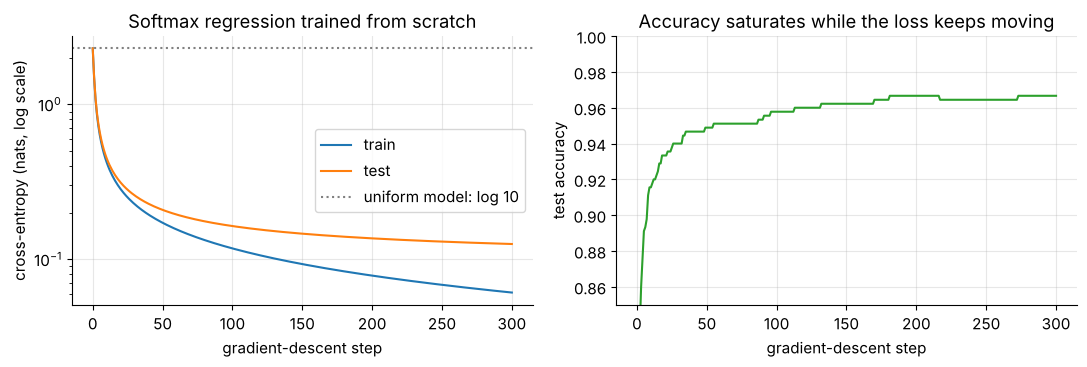

final test CE: ours 0.1256 | sklearn log_loss 0.1256 | torch 0.1256


In [72]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(curves[:, 0], label="train")
axes[0].plot(curves[:, 1], label="test")
axes[0].axhline(np.log(10), color="gray", ls=":", label="uniform model: log 10")
axes[0].set_yscale("log")
axes[0].set_ylabel("cross-entropy (nats, log scale)")
axes[0].set_title("Softmax regression trained from scratch")
axes[1].plot(curves[:, 2], color="tab:green")
axes[1].set_ylim(0.85, 1.0)
axes[1].set_ylabel("test accuracy")
axes[1].set_title("Accuracy saturates while the loss keeps moving")
for ax in axes:
    ax.set_xlabel("gradient-descent step")
axes[0].legend()
fig.tight_layout()
plt.show()

Z_te_dig = X_te_s @ W_dig + b_dig
Q_te_dig = softmax(Z_te_dig)
print(f"final test CE: ours {softmax_cross_entropy(Z_te_dig, y_te):.4f} | sklearn log_loss {log_loss(y_te, Q_te_dig):.4f} | "
      f"torch {F.cross_entropy(torch.tensor(Z_te_dig), torch.tensor(y_te)).item():.4f}")

The loss starts at exactly $\log 10 \approx 2.3026$ (all-zero weights give the uniform prediction) and the test cross-entropy falls to about $0.13$ nats, with about 96.7% test accuracy. Notice two things. The training loss keeps falling while the test loss flattens out: the gap between them is the beginning of overfitting, and the loss reveals it long before the accuracy does. And accuracy saturates early while the loss keeps improving, because the model keeps becoming *more confident on examples it already gets right*.

Which test images cost the most? As with the weather app "Bold" in Section 1, a handful of confident mistakes dominates the average:

15 of 450 test images are misclassified; they carry 49.3% of the total test loss.
the 23 most expensive images (5% of the test set) carry 61.5%.


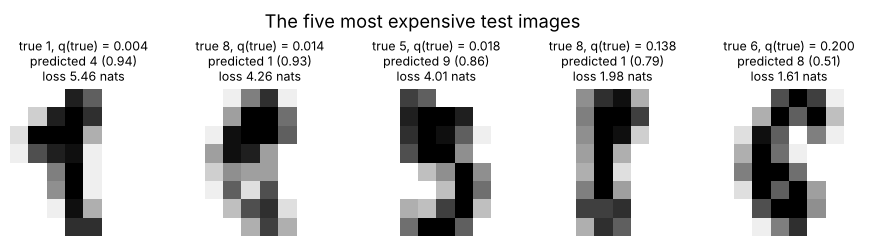

In [73]:
per_example_te = -log_softmax(Z_te_dig)[np.arange(len(y_te)), y_te]
order = np.argsort(-per_example_te)
wrong = Q_te_dig.argmax(axis=1) != y_te
n_top = int(np.ceil(0.05 * len(y_te)))
print(f"{wrong.sum()} of {len(y_te)} test images are misclassified, and they carry "
      f"{per_example_te[wrong].sum() / per_example_te.sum():.1%} of the total test loss.")
print(f"the {n_top} most expensive images (5% of the test set) carry {per_example_te[order[:n_top]].sum() / per_example_te.sum():.1%}.")

fig, axes = plt.subplots(1, 5, figsize=(11, 2.8))
for ax, i in zip(axes, order[:5]):
    ax.imshow(X_te[i].reshape(8, 8), cmap="gray_r")
    pred = Q_te_dig[i].argmax()
    ax.set_title(f"true {y_te[i]}, q(true) = {Q_te_dig[i, y_te[i]]:.3f}\npredicted {pred} ({Q_te_dig[i, pred]:.2f})\n"
                 f"loss {per_example_te[i]:.2f} nats", fontsize=9)
    ax.axis("off")
fig.suptitle("The five most expensive test images", y=1.04)
plt.show()

## 10. Evaluating probabilistic predictions

Training minimizes cross-entropy on the training set. To *evaluate* a model we compute the same quantity on data the model has never seen, and then we need to know how to read the number. Is $0.13$ nats good? Is a perplexity of $10$ good? And even a model with a low loss can be systematically over- or under-confident. This section gives you three tools: **baselines** that put a log-loss in context, **perplexity**, which turns a log-loss into an "effective number of choices", and **calibration**, which checks whether a model's 80% really means 80%.

### 10.1 Average log-loss and the baselines that give it meaning

The test log-loss of a classifier is the average surprisal of the true labels,

$$
\text{log-loss} = -\frac{1}{N}\sum_{i=1}^{N} \log q_{\boldsymbol\theta}\big(y^{(i)} \mid \mathbf{x}^{(i)}\big),
$$

which by Section 6.4 estimates the cross-entropy between the real label distribution and the model. A raw log-loss means little on its own, so always compare it with two "know-nothing" baselines that ignore the input $\mathbf{x}$ completely:

1. **Uniform baseline:** predict $1/K$ for every class. Its log-loss is exactly $\log K$, whatever the data.
2. **Prior baseline:** always predict the class frequencies $\hat{\boldsymbol\pi}$ of the training set. Its expected log-loss is the cross-entropy $H(\boldsymbol\pi_{\text{test}}, \hat{\boldsymbol\pi})$, which is close to the entropy $H(\boldsymbol\pi)$ of the labels, and never more than $\log K$ when the frequencies are estimated well (Section 5.4).

A model is only useful to the extent that it beats the prior baseline: that gap measures how much the input $\mathbf{x}$ actually tells the model about $y$ (Section 11 turns this into a precise statement). For balanced data such as the digits the two baselines nearly coincide. For imbalanced data the prior baseline can be far below $\log K$, and beating $\log K$ is then no achievement at all.

In [74]:
def log_loss_report(name, q_true):
    """One row of a report: mean log-loss (nats, bits) and perplexity from the probabilities q(true label)."""
    nll = -np.mean(np.log(q_true))
    return {"model": name, "log-loss (nats)": nll, "log-loss (bits)": nll / np.log(2), "perplexity": np.exp(nll)}


prior_dig = np.bincount(y_tr, minlength=K_dig) / len(y_tr)       # class frequencies of the training set
rows = [
    log_loss_report("uniform: 1/10 for every class", np.full(len(y_te), 1 / K_dig)),
    log_loss_report("prior: training-set class frequencies", prior_dig[y_te]),
    log_loss_report("softmax regression (Section 9.6)", Q_te_dig[np.arange(len(y_te)), y_te]),
]
display(pd.DataFrame(rows).set_index("model").round(4))

imbalanced = np.array([0.90, 0.07, 0.03])                        # e.g. "normal / warning / failure" labels
print(f"imbalanced 3-class labels {imbalanced}: uniform baseline log 3 = {np.log(3):.4f} nats, "
      f"prior baseline H = {entropy(imbalanced):.4f} nats")

,log-loss (nats),log-loss (bits),perplexity
model,,,
uniform: 1/10 for every class,2.3026,3.3219,10.0000
prior: training-set class frequencies,2.3024,3.3217,9.9986
softmax regression (Section 9.6),0.1256,0.1812,1.1338


imbalanced 3-class labels [0.9  0.07 0.03]: uniform baseline log 3 = 1.0986 nats, prior baseline H = 0.3862 nats


On the digits, both baselines sit at about $2.30$ nats (the classes are almost perfectly balanced), and our softmax regression reaches $0.1256$ nats: it removes about 95% of the baseline uncertainty. For the imbalanced example, the uniform baseline is $\log 3 \approx 1.0986$ nats, but simply predicting the class frequencies already gets $0.3862$ nats. A "model" with log-loss $0.5$ on such data would beat the uniform baseline comfortably and still be *worse than useless*: it would be beaten by a constant.

> **Common pitfall.** Reporting a log-loss without its baseline. Always print $\log K$ and the prior-baseline loss next to it, the same way you would compare an accuracy with the majority-class rate.

### 10.2 Perplexity: the effective number of choices

Log-losses are hard to feel: is $1.9$ nats a lot? **Perplexity** converts the average loss back into a count:

$$
\operatorname{PP} = \exp\!\Big(-\frac{1}{N}\sum_{i=1}^N \log q\big(y^{(i)}\big)\Big) = 2^{\,\text{log-loss in bits}} = \Big(\prod_{i=1}^{N} \frac{1}{q(y^{(i)})}\Big)^{1/N}.
$$

The three forms are equal: the base cancels out ($2$ raised to the log-loss in bits gives the same number as $e$ raised to the log-loss in nats), and the last form shows that perplexity is the **geometric mean of $1/q$**, the "one-in-how-many" odds of each observed outcome.

**Why "effective number of choices"?** If a model spreads its probability uniformly over $k$ options and the truth is always among them, then every $q(y^{(i)}) = 1/k$ and $\operatorname{PP} = k$. So a perplexity of $10$ means: *on average, the model is as uncertain as if it had to pick uniformly among 10 equally likely options*. Some anchors:

| situation | perplexity |
|---|---|
| perfect model ($q(y) = 1$ always) | $1$ |
| fair six-sided die, modeled correctly | $6$ |
| uniform guess over $K$ classes | $K$ |
| a model that once gave the truth probability $0$ | $\infty$ |

The digits model above has perplexity $e^{0.1256} \approx 1.13$: it is almost never torn between two digits. Perplexity is the standard headline metric for **language models**, which predict the next symbol of a text. Let us build three tiny ones on characters. The text is a second short original story about the same weather station (written for this notebook, and it overlaps with, but is not identical to, the story of Section 5.6) that we split into a training part (first 80%) and a held-out part (last 20%). The alphabet is the 26 letters plus the space, so $K = 27$.

In [75]:
story = """The weather station stood at the end of a long gravel road, past the last farmhouse and an old stone bridge. Every morning at six the keeper climbed the narrow stairs to read her instruments: the thermometer in its white wooden box, the rain gauge beside the fence, and the brass barometer that ticked softly whenever the pressure changed. She wrote each number in a thick green notebook and then read a short report to the harbor over the radio.
Most days the report was dull. Sunny, light wind from the west, no rain. Cloudy and cool, a little mist over the river. The fishermen listened anyway, because a dull report meant a calm day at sea, while a surprising report could save a boat and everyone on it. When the keeper said that a storm was coming, nobody argued and nobody sailed.
After many years of mornings she began to notice a pattern in her own words. The report almost always started with the same few phrases, and some words appeared so often that the listeners could finish her sentences before she did. Other words, like hail or waterspout, came up only once or twice in a whole season, and when they did, the harbor went quiet. It struck her that the rare words carried the real news. A word everyone expected told them almost nothing. A word nobody expected told them a great deal.
She also kept a private tally. Each evening she wrote down how sure she had been of her forecast, from one chance in ten to nine chances in ten, and the next evening she marked whether it had come true. At the end of every month she grouped the forecasts by how sure she had been and counted how often each group had come true. When she had said seven in ten, it should rain on about seven of every ten such days. If it rained on nine of them, she had been too timid. If it rained on only four, she had been too bold. Year after year she adjusted her habits until her numbers matched the sky.
One winter a young engineer visited the station. He asked why she bothered with all the counting when she could simply say rain or no rain. She showed him the tally. A forecast that says only rain, she told him, cannot be trusted or distrusted. It is right or wrong and that is all. A forecast that says seven in ten tells the fisherman how much risk he is taking, and if the numbers are honest he can plan his whole season around them. The engineer copied her tables into his own notebook and went back to the city.
Years later the harbor installed an automatic forecasting machine. It was fast and it never slept, but in its first months it announced every storm with complete certainty, and twice the storm never came. The fishermen stopped listening to it. The keeper kept her green notebooks, and on the mornings when the machine was sure and she was not, the boats stayed in the harbor and waited for a clear morning. The engineer wrote to her from the city that her tally was a fine example of a calibrated forecast, and that his colleagues were trying to teach machines to make predictions that behaved the same way.
The station still stands at the end of the gravel road. The brass barometer still ticks, the green notebooks fill a whole shelf, and the morning report still begins with the same familiar words. But every listener now knows that the most valuable part of the message is the part they did not expect, and that a forecast is only as good as the honesty of its numbers."""

alphabet = list(" abcdefghijklmnopqrstuvwxyz")                    # K = 27 symbols
char_index = {c: i for i, c in enumerate(alphabet)}
clean = re.sub(r"[^a-z]+", " ", story.lower()).strip()            # letters and single spaces only
codes = np.array([char_index[c] for c in clean])
cut = int(0.8 * len(codes))
train_codes, test_codes = codes[:cut], codes[cut:]
prev_codes = codes[cut - 1:-1]                                     # the character before each test character
K_chr = len(alphabet)
print(f"{len(codes)} characters: {len(train_codes)} for training, {len(test_codes)} held out. K = {K_chr}")
print("first 60 cleaned characters:", repr(clean[:60]))

3318 characters: 2654 for training, 664 held out; K = 27
first 60 cleaned characters: 'the weather station stood at the end of a long gravel road p'


The three models, from least to most informed:

* **Uniform:** $q(c) = 1/27$ for every character.
* **Unigram:** $q(c) \propto \text{count}(c) + \alpha$, the character frequencies of the training text. The pseudo-count $\alpha$ (**add-$\alpha$ smoothing**) gives unseen characters a little probability.
* **Bigram:** $q(c \mid c_{\text{prev}}) \propto \text{count}(c_{\text{prev}} \to c) + \alpha$, one categorical distribution per previous character, estimated from the $27 \times 27$ table of consecutive pairs. Both counting formulas are the maximum-likelihood estimates of Section 8.1 (with $\alpha = 0$), so these are models trained by minimizing cross-entropy.

In [76]:
def unigram_probs(train, alpha, K=K_chr):
    """Add-alpha smoothed character frequencies, shape (K,)."""
    counts = np.bincount(train, minlength=K) + alpha
    return counts / counts.sum()


def bigram_probs(train, alpha, K=K_chr):
    """Add-alpha smoothed transition table, row c_prev = q(. | c_prev), shape (K, K)."""
    counts = np.zeros((K, K))
    np.add.at(counts, (train[:-1], train[1:]), 1.0)               # count consecutive pairs
    counts += alpha
    row_sums = counts.sum(axis=1, keepdims=True)
    return np.divide(counts, row_sums, out=np.zeros_like(counts), where=row_sums > 0)


def char_report(name, q_test):
    """Bits per character, perplexity and number of impossible (q = 0) test characters."""
    with np.errstate(divide="ignore"):                             # log(0) = -inf is the honest answer
        bits = -np.mean(np.log2(q_test))
    return {"model": name, "bits per char": bits, "perplexity": 2 ** bits, "test chars with q = 0": int(np.sum(q_test == 0))}


reports = [char_report("uniform", np.full(len(test_codes), 1 / K_chr))]
for a in (0.0, 1.0):
    reports.append(char_report(f"unigram, alpha = {a:g}", unigram_probs(train_codes, a)[test_codes]))
for a in (0.0, 0.1, 1.0):
    reports.append(char_report(f"bigram, alpha = {a:g}", bigram_probs(train_codes, a)[prev_codes, test_codes]))
char_table = pd.DataFrame(reports).set_index("model")
display(char_table.round(4))
print(f"entropy of the training-set character frequencies: {entropy(unigram_probs(train_codes, 0.0), base=2):.4f} bits")

,bits per char,perplexity,test chars with q = 0
model,,,
uniform,4.7549,27.0000,0
"unigram, alpha = 0",4.0194,16.2165,0
"unigram, alpha = 1",4.0207,16.2314,0
"bigram, alpha = 0",inf,inf,12
"bigram, alpha = 0.1",3.2448,9.4794,0
"bigram, alpha = 1",3.3254,10.0242,0


entropy of the training-set character frequencies: 4.0067 bits


Reading the table from the top:

* **Uniform:** $\log_2 27 \approx 4.7549$ bits per character, perplexity exactly $27$, as promised.
* **Unigram:** knowing only *which letters are common* (space, e, t, a, ...) cuts the perplexity to about $16.2$. Its bits per character ($4.02$) are close to the entropy of the training-set letter frequencies printed under the table: by Section 6.4, the held-out average log-loss estimates the cross-entropy between the test text and the model, and the test text has nearly the same letter frequencies as the training text.
* **Bigram:** knowing the previous character cuts the perplexity to about $9.5$ (with $\alpha = 0.1$): after a "q" there is essentially one choice, after a space there are many. The model is, on average, as uncertain as a uniform guess among fewer than 10 characters.
* **The zero-probability disaster:** with $\alpha = 0$ the bigram model has never seen some pairs that occur in the held-out text (12 test characters), assigns them $q = 0$, and its perplexity is **infinite**, the same infinity as $D_{\mathrm{KL}}(P \Vert Q)$ when $Q$ has zeros where $P$ does not (Section 7.3). A tiny pseudo-count fixes it, and too large a pseudo-count ($\alpha = 1$) blurs the model back toward uniform and costs a little (perplexity about $10.0$ instead of $9.5$). In a real project you would tune $\alpha$ on a validation set, never on the test set.

To *feel* these numbers, let each model write. Sampling one character at a time from $q$ (for the bigram, from the row of the character just generated) turns a language model into a text generator:

In [77]:
rng_txt = np.random.default_rng(SEED)
uni_q, bi_Q = unigram_probs(train_codes, 0.1), bigram_probs(train_codes, 0.1)


def generate(n_chars, use_bigram):
    """Sample n_chars characters, each from the unigram q or from the bigram row of the previous character."""
    out, prev = [], char_index[" "]
    for _ in range(n_chars):
        prev = rng_txt.choice(K_chr, p=bi_Q[prev] if use_bigram else uni_q)
        out.append(alphabet[prev])
    return "".join(out)


print("uniform (PP 27.0):", "".join(rng_txt.choice(alphabet, size=70)))
print("unigram (PP 16.2):", generate(70, use_bigram=False))
print("bigram  (PP  9.5):", generate(70, use_bigram=True))

uniform (PP 27.0): btqkkwbrebnzstsumcvlmjdyuqjvnklfbnwawvgqdtriazlxruteilmandtrxtizkhxjbl
unigram (PP 16.2): a hanesodsredo a rnorgk  nhkrniid eaesa cdnirnes   og h ofedne  vtobwr
bigram  (PP  9.5): she te he thed po iche an wine whe ndund hed tod ararot ul onotevee wa


None of them writes English, but every step down in perplexity is visible. The uniform model uses rare letters as often as common ones and almost never produces a space. The unigram model has realistic letter and space frequencies but no structure inside words. The bigram model already produces pronounceable fragments and some real short words, because it knows which letter tends to follow which. Modern language models are the same idea, scaled up: they predict the next token from a long context instead of one character, are trained by minimizing exactly this cross-entropy, and are compared by their perplexity on held-out text.

> **Common pitfall.** Comparing perplexities computed on different *units* or *vocabularies*. Perplexity per character and perplexity per word are on completely different scales (a word is several characters), and a model with a bigger vocabulary faces a harder prediction problem. Compare perplexities only for the same test text, split into the same symbols.

### ✏️ Exercise 9: perplexity without underflow

Implement `perplexity(log_probs, base=np.e)`. The input holds the log-probabilities (in the given base) that a model assigned to the outcomes that actually occurred, one per prediction. Return the perplexity as a Python float. It must work for 100,000 predictions (where multiplying probabilities underflows), must not depend on the base except through the input's units, and must return `inf` if any log-probability is $-\infty$.

In [78]:
# ✏️ Exercise 9: perplexity from log-probabilities
def perplexity(log_probs, base=np.e):
    """Perplexity = base ** (average negative log-probability). log_probs is a 1-D array."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex9():
    assert np.isclose(perplexity(np.log(np.full(1000, 1 / 27))), 27.0), "uniform over 27 symbols must give 27"
    assert np.isclose(perplexity(np.log([0.5, 0.25, 0.125])), 4.0), "geometric mean of 2, 4, 8 is 4"
    assert np.isclose(perplexity(np.log2([0.5, 0.25, 0.125]), base=2), 4.0), "base-2 input must give the same answer"
    long_run = np.full(100_000, np.log(1e-5))                     # the product of these underflows to 0
    assert np.isclose(perplexity(long_run), 1e5, rtol=1e-9), "use the mean of the logs, not a product of probabilities"
    assert perplexity(np.array([-0.1, -np.inf])) == np.inf, "an impossible observed outcome means infinite perplexity"
    assert isinstance(perplexity(np.log([0.5, 0.5])), float), "return a Python float"


run_check("Exercise 9", _test_ex9)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def perplexity(log_probs, base=np.e):
    log_probs = np.asarray(log_probs, dtype=float)
    return float(base ** (-np.mean(log_probs)))
```
Averaging the logs first keeps every intermediate number of moderate size, so nothing underflows, and a single $-\infty$ makes the mean $-\infty$ and the result $\infty$. Raising the *same* base used for the logs undoes them, which is why bits with base 2 and nats with base $e$ give the same perplexity.
</details>

### 10.3 Calibration: does "80% sure" mean right 80% of the time?

The keeper in the story graded herself in a way accuracy never could: she grouped her forecasts by how sure she had been and checked how often each group came true. A model is **calibrated** if, among all the cases where it says $q$, the event happens a fraction $q$ of the time:

$$
\Pr\big(Y = 1 \mid q(\mathbf{x}) = q\big) = q \quad \text{for every } q.
$$

A **reliability diagram** checks this. Sort the predictions into bins by their predicted probability (here 10 bins of width $0.1$), and for each bin plot the average prediction (x-axis) against the observed frequency of $y = 1$ (y-axis). A calibrated model lies on the diagonal. Points *below* the diagonal on the right and *above* it on the left mean **overconfidence**: the model's probabilities are more extreme than reality. The **expected calibration error** summarizes the diagram in one number, a weighted average of the gaps:

$$
\operatorname{ECE} = \sum_{b=1}^{B} \frac{n_b}{N}\,\big|\bar q_b - \bar y_b\big|,
$$

where bin $b$ holds $n_b$ of the $N$ predictions, $\bar q_b$ is their mean prediction and $\bar y_b$ is the fraction of them with $y = 1$.

**A toy model that is badly overconfident.** We generate data where the truth is known: $\mathbf{x} \in \mathbb{R}^{32}$, only the first two features matter, and $y \sim \operatorname{Bernoulli}\big(\sigma(1.5x_1 - x_2 + 0.3)\big)$. Then we fit a logistic regression with essentially no regularization to only 150 training examples. With 30 useless features to exploit, the fit drives its training cross-entropy down by making its logits too large, a miniature version of what happens to big networks trained for many epochs. Separate validation (2,000) and test (20,000) sets come from the same distribution.

In [79]:
rng_cal = np.random.default_rng(SEED)


def make_toy(n, d_noise=30):
    """Two informative features + d_noise useless ones. Labels are drawn from a known logistic model."""
    X = rng_cal.normal(size=(n, 2 + d_noise))
    z_true = 1.5 * X[:, 0] - 1.0 * X[:, 1] + 0.3
    y = (rng_cal.random(n) < special.expit(z_true)).astype(int)
    return X, y, z_true


X_fit, y_fit, _ = make_toy(150)
X_val, y_val, _ = make_toy(2000)
X_tst, y_tst, z_tst_true = make_toy(20000)
overfit = LogisticRegression(C=1e4, max_iter=5000).fit(X_fit, y_fit)   # C = 1e4: almost no regularization
z_val, z_tst = overfit.decision_function(X_val), overfit.decision_function(X_tst)   # logits


def reliability_bins(q, y, n_bins=10):
    """Equal-width bins of q: count, mean prediction and observed frequency of y = 1 per non-empty bin."""
    which = np.clip(np.digitize(q, np.linspace(0, 1, n_bins + 1)[1:-1]), 0, n_bins - 1)
    rows = [(int(np.sum(which == b)), q[which == b].mean(), y[which == b].mean())
            for b in range(n_bins) if np.any(which == b)]
    return pd.DataFrame(rows, columns=["count", "mean q", "observed freq"])


def expected_calibration_error(q, y, n_bins=10):
    """ECE = sum_b (n_b / N) |mean q_b - observed freq_b|."""
    t = reliability_bins(q, y, n_bins)
    return float(np.sum(t["count"] / len(q) * np.abs(t["mean q"] - t["observed freq"])))


def binary_report(name, z, y):
    """Accuracy, log-loss and ECE of a binary model given its logits z."""
    q = special.expit(z)
    return {"model": name, "accuracy": np.mean((z > 0) == y), "log-loss (nats)": bce_from_logits(y, z).mean(),
            "ECE": expected_calibration_error(q, y)}


print(f"overfit model: training accuracy {overfit.score(X_fit, y_fit):.3f}, "
      f"training log-loss {bce_from_logits(y_fit, overfit.decision_function(X_fit)).mean():.4f} nats")
cal_rows = [binary_report("true model sigma(z_true)", z_tst_true, y_tst),
            binary_report("overfit logistic regression", z_tst, y_tst)]
display(pd.DataFrame(cal_rows).set_index("model").round(4))

overfit model: training accuracy 0.880, training log-loss 0.2376 nats


,accuracy,log-loss (nats),ECE
model,,,
true model sigma(z_true),0.7642,0.4847,0.0071
overfit logistic regression,0.7276,1.0162,0.1908


The overfit model looks great on its own training data (training log-loss $0.24$ nats, accuracy 88%), but on the test set its log-loss is about **double** that of the true model ($1.02$ vs $0.48$ nats), while its accuracy is only a few points lower ($72.8\%$ vs $76.4\%$). Its ECE says why: its probabilities are off by about $0.19$ on average. The true model's test log-loss is the best any model can achieve on this data, up to sampling noise (Section 11 explains why), and its ECE is close to zero.

### 10.4 Temperature scaling: fixing confidence with one number

A simple and remarkably effective repair is **temperature scaling**: divide every logit by a single positive number $T$ before the sigmoid (or softmax),

$$
q_T(\mathbf{x}) = \sigma\big(z(\mathbf{x}) / T\big).
$$

$T > 1$ pulls all probabilities toward $\tfrac12$ (less confident), $T < 1$ pushes them toward $0$ or $1$. Because dividing by $T > 0$ never changes the sign of a logit (or, for softmax, the order of the logits), **the predicted classes and the accuracy stay exactly the same**, and only the confidence changes. We choose $T$ the way we choose every parameter in this notebook: by minimizing cross-entropy, here on the *validation* set, with the model's weights frozen. Optimizing over $\log T$ keeps $T$ positive automatically.

best temperature on the validation set: T* = 4.415 (validation log-loss 0.5298, at T = 1: 0.9791)


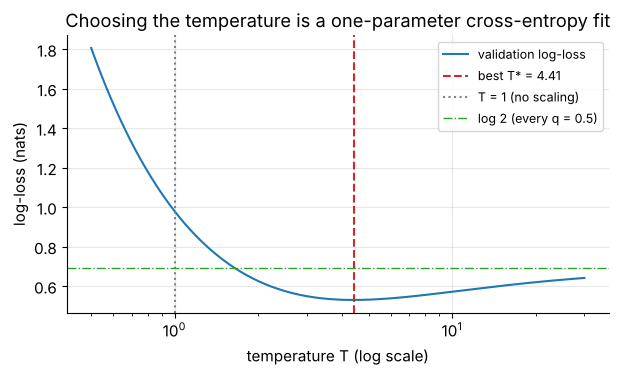

In [80]:
def val_nll(log_T):
    """Validation log-loss of the overfit model after dividing its logits by T = exp(log_T)."""
    return float(bce_from_logits(y_val, z_val / np.exp(log_T)).mean())


res_T = optimize.minimize_scalar(val_nll, bounds=(-3.0, 3.0), method="bounded")
T_star = float(np.exp(res_T.x))
print(f"best temperature on the validation set: T* = {T_star:.3f} (validation log-loss {res_T.fun:.4f}, at T = 1: {val_nll(0.0):.4f})")

T_grid = np.exp(np.linspace(np.log(0.5), np.log(30.0), 200))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(T_grid, [val_nll(np.log(T)) for T in T_grid], label="validation log-loss")
ax.axvline(T_star, color="tab:red", ls="--", label=f"best T* = {T_star:.2f}")
ax.axvline(1.0, color="gray", ls=":", label="T = 1 (no scaling)")
ax.axhline(np.log(2), color="tab:green", ls="-.", lw=1, label="log 2 (every q = 0.5)")
ax.set_xscale("log")
ax.set_xlabel("temperature T (log scale)")
ax.set_ylabel("log-loss (nats)")
ax.set_title("Choosing the temperature is a one-parameter cross-entropy fit")
ax.legend(fontsize=9)
plt.show()

The curve is a smooth valley. To the left of $T^*$ the scaled model is still overconfident, to the right it becomes underconfident, and as $T \to \infty$ every prediction approaches $q = 0.5$, so the loss creeps up toward $\log 2 \approx 0.6931$, the cost of shrugging on every example. At $T = 1$ (the model as trained) the validation loss is far above even that shrug: this overfit model would literally do better by always saying 50%. Now apply the chosen $T^*$ to the untouched test set:

In [81]:
cal_rows.append(binary_report(f"overfit / T*  (T* = {T_star:.2f})", z_tst / T_star, y_tst))
display(pd.DataFrame(cal_rows).set_index("model").round(4))

,accuracy,log-loss (nats),ECE
model,,,
true model sigma(z_true),0.7642,0.4847,0.0071
overfit logistic regression,0.7276,1.0162,0.1908
overfit / T* (T* = 4.41),0.7276,0.5390,0.0482


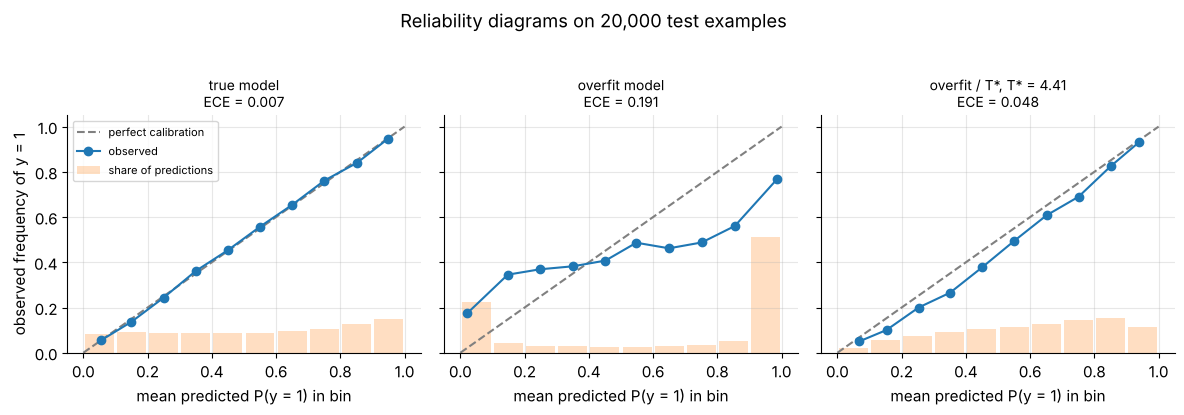

In [82]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
panels = [("true model", z_tst_true), ("overfit model", z_tst), (f"overfit / T*, T* = {T_star:.2f}", z_tst / T_star)]
for ax, (title, z) in zip(axes, panels):
    q = special.expit(z)
    t = reliability_bins(q, y_tst)
    ax.plot([0, 1], [0, 1], color="gray", ls="--", label="perfect calibration")
    ax.plot(t["mean q"], t["observed freq"], "o-", label="observed")
    ax.bar(np.arange(10) / 10 + 0.05, np.histogram(q, bins=10, range=(0, 1))[0] / len(q), width=0.09,
           alpha=0.25, color="tab:orange", label="share of predictions")
    ax.set_title(f"{title}\nECE = {expected_calibration_error(q, y_tst):.3f}", fontsize=10)
    ax.set_xlabel("mean predicted P(y = 1) in bin")
axes[0].set_ylabel("observed frequency of y = 1")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Reliability diagrams on 20,000 test examples", y=1.03)
fig.tight_layout()
plt.show()

The middle panel is the signature of overconfidence: the curve is much flatter than the diagonal and about 73% of the predictions sit in the two extreme bins, where the model claims about 98–99% certainty but is right only about 77–83% of the time. After dividing the logits by $T^* \approx 4.4$, the curve hugs the diagonal, the ECE falls from about $0.19$ to under $0.05$, and the test log-loss drops from about $1.02$ to about $0.54$ nats, with **identical** accuracy. The repaired model is still worse than the true model (its *ranking* of examples is noisier, which no rescaling can fix), but its probabilities are now honest.

**Why does cross-entropy reward honesty?** Suppose an event truly happens with probability $p$ and you announce $q$. Your expected log-loss is

$$
-p\log q - (1 - p)\log(1 - q) = H\big(\operatorname{Bern}(p)\big) + D_{\mathrm{KL}}\big(\operatorname{Bern}(p) \,\Vert\, \operatorname{Bern}(q)\big),
$$

the identity of Section 7.1. The first term does not depend on you, and the second is zero only at $q = p$ (Gibbs). So the *only* way to minimize expected log-loss is to announce your true belief. A score with this property is called a **strictly proper scoring rule** (a merely *proper* rule only requires honesty to be *one of* the best strategies). Accuracy is at best proper, never strictly proper: it pays the same for 51% and 99%, which is why it cannot train or diagnose confidence. The same identity explains the test numbers above: the true model's log-loss estimates the irreducible part, and everything the overfit model loses beyond it is a KL penalty for distorted probabilities.

> **Going deeper.** Modern deep networks are often overconfident in exactly this way, and temperature scaling (one parameter, fit on validation data) is the standard first fix. Other recalibration methods learn a more flexible map from $q$ to calibrated probabilities (Platt scaling fits $\sigma(az + b)$, and isotonic regression fits any increasing function). Calibration is not the same as being good: the prior baseline of Section 10.1 is perfectly calibrated and useless. A good probabilistic model is both **calibrated** and **sharp** (confident when it can be).

**Quick check.** You multiply all logits of a 10-class softmax classifier by $0.5$. What happens to its accuracy, to its average confidence, and to its perplexity on a test set where it was overconfident?

<details>
<summary>Answer</summary>

Multiplying by $0.5$ is temperature scaling with $T = 2$. The order of the logits in each row is unchanged, so every predicted class and the accuracy stay the same. Probabilities move toward uniform, so the average confidence (the largest probability) goes down. If the model was overconfident, its test log-loss usually goes down, and with it the perplexity $e^{\text{log-loss}}$, until $T$ passes the best temperature. Beyond that point the model becomes underconfident and the loss rises again.
</details>

## 11. Going deeper: mutual information

Section 10.1 claimed that a classifier can beat the prior baseline only to the extent that the input $\mathbf{x}$ "tells it something" about the label. Information theory measures that "something" exactly. The quantity is called **mutual information**, and it is one more application of the entropy and KL divergence you already know.

### 11.1 Conditional entropy and mutual information

Let $X$ and $Y$ be two discrete random variables with **joint PMF** $p(x, y) = \Pr(X = x, Y = y)$, marginals $p(x) = \sum_y p(x, y)$ and $p(y) = \sum_x p(x, y)$, and conditionals $p(y \mid x) = p(x, y) / p(x)$. Think of $X$ as the sky in the morning and $Y$ as whether it rains later.

* The **conditional entropy** $H(Y \mid X)$ is the uncertainty about $Y$ that remains *after* you see $X$, averaged over what you might see:

$$
H(Y \mid X) = \sum_x p(x)\, H\big(Y \mid X = x\big) = -\sum_{x, y} p(x, y) \log p(y \mid x).
$$

* The **mutual information** is the reduction in uncertainty about $Y$ from seeing $X$:

$$
I(X; Y) = H(Y) - H(Y \mid X).
$$

Write both entropies as expectations over the joint distribution and combine the logarithms:

$$
I(X;Y) = \sum_{x,y} p(x,y)\big[-\log p(y) + \log p(y \mid x)\big] = \sum_{x,y} p(x,y) \log \frac{p(x,y)}{p(x)\,p(y)} = D_{\mathrm{KL}}\big(P_{XY} \,\Vert\, P_X \otimes P_Y\big),
$$

using $p(y \mid x)/p(y) = p(x,y)/\big(p(x)p(y)\big)$ in the middle step. So mutual information is the KL divergence between the real joint distribution and the "independent" distribution $p(x)p(y)$ that has the same marginals. Everything we proved about KL now pays off at once:

1. $I(X; Y) \ge 0$ (Gibbs' inequality), hence $H(Y \mid X) \le H(Y)$: **on average, extra information never increases uncertainty.** (A particular observation can increase it: see the "cloudy" row below.)
2. $I(X; Y) = 0$ exactly when $p(x, y) = p(x)p(y)$ for all $x, y$, that is, when $X$ and $Y$ are **independent**.
3. The KL form is symmetric in $X$ and $Y$, so $I(X;Y) = I(Y;X) = H(X) - H(X \mid Y)$, even though the KL divergence itself is not symmetric.

With the **joint entropy** $H(X, Y) = -\sum_{x,y} p(x,y)\log p(x,y)$ and the chain rule $H(X, Y) = H(X) + H(Y \mid X)$ (take logs of $p(x,y) = p(x)\,p(y \mid x)$ and average), all the pieces fit on one line:

```text
|<------------------------- H(X, Y) -------------------------->|
|<------------- H(X) ------------->|
                   |<------------------- H(Y) ---------------->|
|<--- H(X | Y) --->|<--- I(X;Y) -->|<-------- H(Y | X) ------->|
```

### 11.2 A worked example: does the morning sky predict rain?

Over 200 mornings an observer recorded the sky (clear, cloudy, overcast) and whether it rained later that day:

| sky \ later | no rain | rain | total |
|---|---|---|---|
| clear | 72 | 8 | 80 |
| cloudy | 40 | 30 | 70 |
| overcast | 12 | 38 | 50 |
| **total** | **124** | **76** | **200** |

By hand, in nats: rain happens on $76/200 = 0.38$ of the days, so $H(Y) = -0.38\log 0.38 - 0.62\log 0.62 \approx 0.6641$. Row by row: $p(\text{rain} \mid \text{clear}) = 0.1$ gives $H(Y \mid \text{clear}) \approx 0.3251$, $p(\text{rain} \mid \text{cloudy}) = 3/7$ gives $\approx 0.6829$, and $p(\text{rain} \mid \text{overcast}) = 0.76$ gives $\approx 0.5511$. Weighting by how often each sky occurs ($0.40, 0.35, 0.25$):

$$
H(Y \mid X) \approx 0.40(0.3251) + 0.35(0.6829) + 0.25(0.5511) \approx 0.5068, \qquad I(X;Y) \approx 0.6641 - 0.5068 \approx 0.157 \text{ nats}.
$$

Notice that a cloudy morning *raises* the uncertainty above $H(Y) \approx 0.6641$ (to $0.6829$: it makes rain closer to a coin flip), but averaged over all mornings, looking at the sky lowers it. Now the same computation in code, both ways, checked against scikit-learn's `mutual_info_score`, which accepts a table of counts:

In [83]:
sky_counts = np.array([[72, 8],       # clear:    no rain, rain
                       [40, 30],      # cloudy
                       [12, 38]])     # overcast
P_xy = sky_counts / sky_counts.sum()                 # joint PMF, shape (3 skies, 2 outcomes)
p_x, p_y = P_xy.sum(axis=1), P_xy.sum(axis=0)        # marginals
H_y = entropy(p_y)
H_y_given_x_rows = np.array([entropy(row / row.sum()) for row in P_xy])
H_y_given_x = float(np.sum(p_x * H_y_given_x_rows))
mi_entropy_form = H_y - H_y_given_x
mi_kl_form = kl_nats(P_xy.ravel(), np.outer(p_x, p_y).ravel())          # KL(P_XY || P_X P_Y)
print(f"H(Y) = {H_y:.4f}   H(Y | X = clear, cloudy, overcast) = {H_y_given_x_rows.round(4)}")
print(f"H(Y | X) = {H_y_given_x:.4f}")
print(f"I(X;Y): H(Y) - H(Y|X) = {mi_entropy_form:.4f} | KL form = {mi_kl_form:.4f} | "
      f"sklearn = {mutual_info_score(None, None, contingency=sky_counts):.4f} nats "
      f"= {mi_entropy_form / np.log(2):.4f} bits")
print(f"symmetry: H(X) - H(X|Y) = {entropy(p_x) - np.sum(p_y * [entropy(c / c.sum()) for c in P_xy.T]):.4f}")
print(f"chain rule: H(X,Y) = {entropy(P_xy.ravel()):.4f} = H(X) + H(Y|X) = {entropy(p_x) + H_y_given_x:.4f}")

H(Y) = 0.6641   H(Y | X = clear, cloudy, overcast) = [0.3251 0.6829 0.5511]
H(Y | X) = 0.5068
I(X;Y): H(Y) - H(Y|X) = 0.1572 | KL form = 0.1572 | sklearn = 0.1572 nats = 0.2269 bits
symmetry: H(X) - H(X|Y) = 0.1572
chain rule: H(X,Y) = 1.5873 = H(X) + H(Y|X) = 1.5873


All routes agree: seeing the sky removes about $0.157$ nats ($0.227$ bits) of the $0.664$ nats of uncertainty about rain, roughly a quarter of it.

### 11.3 Why this matters for classifiers

Mutual information puts precise limits on the log-losses of Section 10. Take any model $q(y \mid \mathbf{x})$. For each fixed input $\mathbf{x}$, its expected loss is a cross-entropy, $H\big(p(\cdot \mid \mathbf{x}), q(\cdot \mid \mathbf{x})\big) = H(Y \mid X = \mathbf{x}) + D_{\mathrm{KL}}\big(p(\cdot \mid \mathbf{x}) \,\Vert\, q(\cdot \mid \mathbf{x})\big)$. Averaging over inputs:

$$
\mathbb{E}\big[\text{log-loss of } q\big] = H(Y \mid X) + \mathbb{E}_{\mathbf{x}}\Big[D_{\mathrm{KL}}\big(p(\cdot \mid \mathbf{x}) \,\Vert\, q(\cdot \mid \mathbf{x})\big)\Big] \;\ge\; H(Y \mid X).
$$

* $H(Y \mid X)$ is the **floor**: no model, however large, can beat it on average, and only the true conditional distribution reaches it.
* The prior baseline (ignore $\mathbf{x}$, predict the label frequencies) achieves $H(Y)$.
* So the most that *any* model can gain over the prior baseline by looking at the input is $H(Y) - H(Y \mid X) = I(X; Y)$.

We can see these three levels on the toy data of Section 10.3, where we know the true model:

In [84]:
p_pos = y_tst.mean()
levels = pd.Series({
    "prior baseline (estimates H(Y))": entropy([1 - p_pos, p_pos]),
    "overfit model": bce_from_logits(y_tst, z_tst).mean(),
    "overfit model after temperature scaling": bce_from_logits(y_tst, z_tst / T_star).mean(),
    "true model (estimates the floor H(Y|X))": bce_from_logits(y_tst, z_tst_true).mean(),
}, name="test log-loss (nats)")
display(levels.round(4).to_frame())
print(f"estimated I(X;Y) = H(Y) - H(Y|X) = {levels.iloc[0] - levels.iloc[-1]:.4f} nats: the most any model can gain over the prior")

,test log-loss (nats)
prior baseline (estimates H(Y)),0.6882
overfit model,1.0162
overfit model after temperature scaling,0.5390
true model (estimates the floor H(Y|X)),0.4847


estimated I(X;Y) = H(Y) - H(Y|X) = 0.2035 nats: the most any model can gain over the prior


Every model lands on or above the floor $H(Y \mid X)$ (only the true model sits on it), and the distance of a model above the floor is exactly its average KL penalty for having the wrong conditional distribution. Nothing guarantees that a model beats the prior baseline, though. The overfit model ($1.0162$ nats) is *worse* than ignoring $\mathbf{x}$ altogether ($0.6882$ nats), the "worse than useless" situation of Section 10.1. Temperature scaling closed most of its gap to the floor ($0.5390$ nats, now well below the prior baseline), and the rest is due to its noisy weights.

> **Going deeper.** Mutual information appears all over machine learning. Decision trees choose the split with the largest **information gain**, which is the mutual information between the split and the label. Feature-selection tools such as scikit-learn's `mutual_info_classif` rank features by their estimated mutual information with the target. Contrastive representation learning maximizes lower bounds on the mutual information between two views of the same example. Be aware that estimating mutual information for continuous, high-dimensional variables is hard: the plug-in counting method used here works only for small discrete tables with plenty of data.

### ✏️ Exercise 10: mutual information from a table of counts

Implement `mutual_information(joint)` that takes a 2-D array of nonnegative **counts or probabilities** (rows index $X$, columns index $Y$) and returns $I(X;Y)$ in nats as a Python float. Normalize first, use the convention $0 \log 0 = 0$, and do not call `mutual_info_score`, `entropy`, `kl_nats` or any other helper from this notebook.

In [85]:
# ✏️ Exercise 10: mutual information of a joint table
def mutual_information(joint):
    """I(X;Y) in nats from a 2-D table of counts or probabilities."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test_ex10():
    assert np.isclose(mutual_information(sky_counts), 0.157243, atol=1e-6), "sky/rain table should give about 0.1572 nats"
    assert np.isclose(mutual_information(np.outer([0.2, 0.8], [0.5, 0.3, 0.2])), 0.0, atol=1e-12), "independent table must give 0"
    assert np.isclose(mutual_information(np.array([[5, 0], [0, 5]])), np.log(2)), "copy of a fair coin: I = log 2 (zeros allowed)"
    table = np.array([[3, 0, 7], [1, 9, 2], [0, 4, 4]])
    assert np.isclose(mutual_information(table), mutual_information(table.T)), "I(X;Y) must equal I(Y;X)"
    assert np.isclose(mutual_information(table), mutual_information(table / table.sum())), "counts and probabilities must agree"
    assert np.isclose(mutual_information(table), mutual_info_score(None, None, contingency=table)), "disagrees with sklearn"
    assert isinstance(mutual_information(table), float), "return a Python float"


run_check("Exercise 10", _test_ex10)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def mutual_information(joint):
    P = np.asarray(joint, dtype=float)
    P = P / P.sum()                              # counts -> joint PMF
    indep = np.outer(P.sum(axis=1), P.sum(axis=0))   # p(x) p(y)
    nz = P > 0                                   # 0 log 0 = 0
    return float(np.sum(P[nz] * np.log(P[nz] / indep[nz])))
```
This is the KL form $\sum p(x,y)\log\frac{p(x,y)}{p(x)p(y)}$. Wherever $p(x,y) > 0$ both marginals are positive too, so the ratio never divides by zero.
</details>

## 12. Quiz

Eleven exam-style questions. Work each one out on paper before opening the answer. Every answer explains why the right option is right *and* why each other option is wrong. Natural logarithms unless a base is given.

**Q1.** Which distribution over four outcomes has the largest entropy?

(A) $(0.7, 0.1, 0.1, 0.1)$  (B) $(0.4, 0.3, 0.2, 0.1)$  (C) $(0.5, 0.5, 0, 0)$  (D) $(0.25, 0.25, 0.25, 0.25)$

<details>
<summary>Answer</summary>

**(D).** Entropy over $K$ outcomes is at most $\log K$, reached only by the uniform distribution (Section 5.4): here $\log_2 4 = 2$ bits. (A) is dominated by one outcome ($\approx 1.36$ bits). (B) is spread out but uneven ($\approx 1.85$ bits), and "every outcome possible" is not the same as "maximal". (C) is a fair coin in disguise: impossible outcomes add nothing, so it has exactly 1 bit.
</details>

**Q2.** A language model's average cross-entropy on a test text is $2.0794$ nats per token. What is its perplexity?

(A) $2.0794$  (B) $3$  (C) $8$  (D) $e^{3} \approx 20.09$

<details>
<summary>Answer</summary>

**(C).** Perplexity is $e^{\text{CE in nats}} = e^{2.0794} \approx 8$. Equivalently $2.0794$ nats $= 2.0794/\log 2 = 3$ bits, and $2^3 = 8$: the model is as uncertain as a uniform choice among 8 tokens. (A) is the cross-entropy itself, not the perplexity. (B) is the cross-entropy in bits. (D) mixes units: it raises $e$ to the loss measured in bits.
</details>

**Q3.** Which statement about $D_{\mathrm{KL}}(P \Vert Q)$ for discrete distributions is **always** true?

- (A) $D_{\mathrm{KL}}(P \Vert Q) = D_{\mathrm{KL}}(Q \Vert P)$
- (B) $D_{\mathrm{KL}}(P \Vert Q) \ge 0$, with equality if and only if $P = Q$
- (C) $D_{\mathrm{KL}}(P \Vert Q) \le \log K$ for $K$ outcomes
- (D) $D_{\mathrm{KL}}(P \Vert R) \le D_{\mathrm{KL}}(P \Vert Q) + D_{\mathrm{KL}}(Q \Vert R)$

<details>
<summary>Answer</summary>

**(B)** is Gibbs' inequality (Section 7.2). (A) fails in general: KL is asymmetric (Section 7.3 computed different values in the two directions). (C) fails because KL is unbounded: it is $+\infty$ whenever $Q$ gives zero probability to an outcome that $P$ allows, and it grows without limit as that probability shrinks toward zero. (D) is the triangle inequality, which KL does not satisfy in general, and that is one reason it is called a *divergence* and not a distance.
</details>

**Q4.** The true distribution over $\{a, b, c\}$ is $P = (0.2, 0.8, 0)$. For which model $Q$ is the cross-entropy $H(P, Q)$ infinite?

(A) $Q = (0.5, 0.5, 0)$  (B) $Q = (0, 0.5, 0.5)$  (C) $Q = (0.1, 0.1, 0.8)$  (D) $Q = (0.2, 0.8, 0)$

<details>
<summary>Answer</summary>

**(B).** It gives $q(a) = 0$ although $p(a) = 0.2 > 0$, so the term $-p(a)\log q(a) = +\infty$. (A) is finite: its zero is on $c$, which $P$ never produces, and terms with $p(y) = 0$ contribute nothing. (C) is a poor model but finite: every outcome $P$ allows gets positive probability. (D) equals $P$, so $H(P, Q) = H(P) \approx 0.5004$ nats, the smallest possible value.
</details>

**Q5.** A 3-class softmax classifier outputs logits $\mathbf{z} = (2, 1, 0)$ for an example whose true class is the **third** one. What is the gradient of the cross-entropy loss with respect to $\mathbf{z}$ (rounded)?

(A) $(0.665, 0.245, -0.910)$  (B) $(-0.335, 0.245, 0.090)$  (C) $(0.665, 0.245, 0.090)$  (D) $(0, 0, -1)$

<details>
<summary>Answer</summary>

**(A).** The softmax is $\mathbf{q} = (e^2, e^1, e^0)/(e^2 + e + 1) \approx (0.665, 0.245, 0.090)$ and the gradient is $\mathbf{q} - \mathbf{y}$ with $\mathbf{y} = (0, 0, 1)$ (Section 9.4). Its entries sum to zero, as they must. (B) subtracts the one-hot vector at the wrong class (the predicted class instead of the true one). (C) forgets to subtract $\mathbf{y}$ at all. (D) is $-\mathbf{y}$ alone: it ignores how the softmax couples the logits, so it would never push down the wrong classes.
</details>

**Q6.** A sigmoid classifier outputs $q = \sigma(z) = 0.02$ for an example with label $y = 1$. What are $\partial L / \partial z$ for the cross-entropy loss and for the squared error $L = (q - y)^2$?

- (A) cross-entropy $-0.98$, squared error $\approx -0.038$
- (B) cross-entropy $-0.98$, squared error $-1.96$
- (C) cross-entropy $0.02$, squared error $\approx -0.038$
- (D) both are $0$, because the model is saturated

<details>
<summary>Answer</summary>

**(A).** For cross-entropy with a sigmoid, $\partial L/\partial z = q - y = -0.98$. For squared error the chain rule adds the sigmoid's slope: $2(q - y)\,q(1-q) = 2(-0.98)(0.02)(0.98) \approx -0.038$, about 25 times weaker, exactly when the model is badly wrong (Section 8.5). (B) is $\partial L/\partial q$ for squared error, and it forgets the factor $\sigma'(z) = q(1-q)$. (C) has the wrong cross-entropy gradient ($q$ instead of $q - y$). (D) is the danger of squared error taken to the extreme, but cross-entropy's gradient never vanishes while the prediction is wrong.
</details>

**Q7.** With $K = 5$ classes and label smoothing $\varepsilon = 0.2$ (the mixture $(1-\varepsilon)\,\mathbf{e}_c + \frac{\varepsilon}{K}\mathbf{1}$ used by PyTorch), what target replaces the one-hot vector $(0, 1, 0, 0, 0)$?

(A) $(0.04, 0.84, 0.04, 0.04, 0.04)$  (B) $(0.2, 0.8, 0.2, 0.2, 0.2)$  (C) $(0, 0.8, 0, 0, 0)$  (D) $(0.2, 0.2, 0.2, 0.2, 0.2)$

<details>
<summary>Answer</summary>

**(A).** Each class receives $\varepsilon/K = 0.04$, and the true class keeps $1 - \varepsilon = 0.8$ on top: $0.84$. The entries sum to $1$, as a target distribution must. (B) gives every wrong class the whole $\varepsilon$ and sums to $1.6$. (C) removes $\varepsilon$ from the true class without redistributing it, so it sums to $0.8$. (D) is the uniform distribution, which corresponds to $\varepsilon = 1$ and carries no information about the label.
</details>

**Q8.** You fit a single Gaussian $Q$ to a two-peaked distribution $P$ by minimizing the **forward** KL divergence $D_{\mathrm{KL}}(P \Vert Q)$ (which is what maximum likelihood does). What do you get?

- (A) A wide Gaussian that spreads over both peaks
- (B) A narrow Gaussian sitting on one of the peaks
- (C) Exactly $P$
- (D) A Gaussian with zero variance placed between the peaks

<details>
<summary>Answer</summary>

**(A).** The forward KL averages $\log(p/q)$ over samples of $P$, so it explodes wherever $P$ has mass and $Q$ has almost none: $Q$ must **cover** both peaks (mode-covering, Section 7.4). (B) is what the **reverse** KL $D_{\mathrm{KL}}(Q \Vert P)$ tends to produce (mode-seeking), since it only penalizes $Q$ for putting mass where $P$ has little. (C) is impossible: a single Gaussian cannot have two peaks. (D) is the worst of all: a zero-variance $Q$ gives zero density almost everywhere that $P$ has mass, so the forward KL would be infinite.
</details>

**Q9.** A trained 10-class classifier is overconfident. You apply temperature scaling, dividing all logits by $T = 2.5$. Which of the following **can** change?

(A) the predicted class of some test example  (B) the test accuracy  (C) the test log-loss  (D) the order of the 10 class probabilities for some example

<details>
<summary>Answer</summary>

**(C).** Dividing logits by a positive constant keeps their order in every row (A, B and D cannot change), but it moves every probability toward uniform, which changes each $-\log q(\text{true class})$ and therefore the log-loss (Section 10.4). For an overconfident model the log-loss usually *improves*, and so do calibration measures such as the ECE.
</details>

**Q10.** Feature $X$ and label $Y$ satisfy $I(X; Y) = 0$. What is the lowest expected log-loss that any model using only $X$ can achieve?

(A) $0$  (B) $H(Y)$, the same as the prior baseline  (C) $\log K$  (D) something strictly below $H(Y)$, after enough training

<details>
<summary>Answer</summary>

**(B).** The best achievable expected log-loss is $H(Y \mid X) = H(Y) - I(X;Y) = H(Y)$ (Section 11.3): the feature is useless, and predicting the class frequencies is already optimal. (A) would require $Y$ to be a deterministic function of $X$. (C) is the uniform baseline, which is worse than $H(Y)$ unless the classes are balanced. (D) contradicts the bound: no amount of training can extract information that is not there, so any apparent gain on the training set is overfitting.
</details>

**Q11.** For a model $q_{\boldsymbol\theta}(y \mid \mathbf{x})$ and a training set with hard labels, minimizing the average cross-entropy is equivalent to:

- (A) maximizing the likelihood $\prod_i q_{\boldsymbol\theta}(y^{(i)} \mid \mathbf{x}^{(i)})$
- (B) maximizing the training accuracy
- (C) minimizing the squared error between $\mathbf{q}$ and the one-hot $\mathbf{y}$
- (D) maximizing the entropy of the model's predictions

<details>
<summary>Answer</summary>

**(A).** The average cross-entropy is $-\frac{1}{N}\sum_i \log q_{\boldsymbol\theta}(y^{(i)} \mid \mathbf{x}^{(i)})$, which is $-\frac1N$ times the log of the likelihood, and the logarithm is increasing, so both have the same optimum (Section 8.1). (B) is a different objective: accuracy ignores confidence and is not even differentiable. (C) is a different loss (the multi-class Brier score). It also rewards honest probabilities, but it is not the likelihood, and through a sigmoid or softmax its gradient fades for confident mistakes (Section 8.5). (D) would push predictions toward uniform, the opposite of fitting the labels.
</details>

## 13. Summary and going further

### Key formulas

All logarithms are natural (nats) unless a base is shown. Divide by $\log 2$ to convert to bits. $P$ is the true distribution, $Q$ the model, $K$ the number of outcomes.

| concept | formula | remember |
|---|---|---|
| surprisal | $I(y) = -\log p(y)$ | additive for independent events, $0$ for certain events |
| entropy | $H(P) = -\sum_y p(y)\log p(y)$ | $0 \le H(P) \le \log K$, uniform is the maximum, $0\log 0 = 0$ |
| binary entropy | $h(\theta) = -\theta\log\theta - (1-\theta)\log(1-\theta)$ | peak $\log 2$ (1 bit) at $\theta = \tfrac12$ |
| cross-entropy | $H(P, Q) = -\sum_y p(y)\log q(y)$ | $\ge H(P)$, $+\infty$ if $q(y) = 0$ where $p(y) > 0$ |
| KL divergence | $D_{\mathrm{KL}}(P\Vert Q) = \sum_y p(y)\log\frac{p(y)}{q(y)}$ | $\ge 0$, $= 0$ iff $P = Q$, asymmetric, not a distance |
| key identity | $H(P, Q) = H(P) + D_{\mathrm{KL}}(P \Vert Q)$ | minimizing CE over $Q$ = minimizing KL |
| log-sum-exp | $\operatorname{LSE}(\mathbf{z}) = m + \log\sum_k e^{z_k - m}$, $m = \max_k z_k$ | never overflows, the gradient is the softmax |
| softmax / log-softmax | $q_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$, $\;\log q_k = z_k - \operatorname{LSE}(\mathbf{z})$ | compute losses from log-softmax, never from $\log(\text{softmax})$ |
| categorical CE (one example) | $-\sum_k y_k \log q_k = \operatorname{LSE}(\mathbf{z}) - z_c$ for one-hot $\mathbf{y}$ | gradient $\nabla_{\mathbf{z}} = \mathbf{q} - \mathbf{y}$ |
| binary CE from a logit | $\max(z, 0) - zy + \log(1 + e^{-\lvert z \rvert})$ | gradient $\sigma(z) - y$ |
| label smoothing | $\mathbf{y}^{\text{LS}} = (1-\varepsilon)\,\mathbf{e}_c + \tfrac{\varepsilon}{K}\mathbf{1}$ | finite optimal logits, loss floor $H(\mathbf{y}^{\text{LS}})$ |
| dataset loss (NLL) | $J(\boldsymbol\theta) = -\frac1N\sum_i \log q_{\boldsymbol\theta}(y^{(i)} \mid \mathbf{x}^{(i)})$ | minimizing it = maximum likelihood |
| perplexity | $\operatorname{PP} = \exp(J) = 2^{J/\log 2}$ | effective number of equally likely choices, uniform gives $K$ |
| expected calibration error | $\sum_b \frac{n_b}{N}\lvert \bar q_b - \bar y_b \rvert$ | reliability diagram on the diagonal = calibrated |
| mutual information | $I(X;Y) = H(Y) - H(Y\mid X) = D_{\mathrm{KL}}(P_{XY}\Vert P_X \otimes P_Y)$ | $\ge 0$, $0$ iff independent, best possible gain over the prior baseline |

### Takeaways

1. **Score a probabilistic prediction by the probability it gave to what happened.** The penalty $-\log q$ is near zero for confident hits and explodes for confident misses, and its average is the log-loss.
2. **The logarithm is not arbitrary.** It is the only (continuous) way to make the surprise of independent events add up, and it turns products of probabilities into sums that do not underflow.
3. **Entropy is irreducible uncertainty, cross-entropy is what you actually pay, and KL is the difference.** Training can only remove the KL part.
4. **Cross-entropy training is maximum likelihood.** With one-hot labels it reduces to $-\log q(\text{correct class})$, and binary cross-entropy is the Bernoulli negative log-likelihood.
5. **Work in logits.** Use log-softmax / log-sum-exp (`F.cross_entropy`, `F.binary_cross_entropy_with_logits`), and never take the log of a softmax or apply softmax twice. The gradient $\mathbf{q} - \mathbf{y}$ is the reason cross-entropy trains so well: it never fades while the model is wrong.
6. **Read a log-loss against its baselines** ($\log K$ and the label entropy), translate it into a perplexity when that helps, and check calibration with a reliability diagram. Temperature scaling repairs overconfidence without changing a single prediction.

### Going further

* Claude Shannon, [*A Mathematical Theory of Communication*](https://people.math.harvard.edu/~ctm/home/text/others/shannon/entropy/entropy.pdf) (1948): the paper that defined entropy and proved the source-coding theorem, and the first sections are very readable.
* Thomas M. Cover and Joy A. Thomas, *Elements of Information Theory* (2nd ed., Wiley, 2006), Chapter 2: entropy, relative entropy and mutual information with full proofs.
* David J. C. MacKay, [*Information Theory, Inference, and Learning Algorithms*](https://www.inference.org.uk/itila/book.html) (free online): Chapters 2–5 connect entropy, coding and inference with many exercises.
* Ian Goodfellow, Yoshua Bengio and Aaron Courville, [*Deep Learning*, Chapter 3](https://www.deeplearningbook.org/contents/prob.html): probability and information theory for machine learning, and Section 6.2 discusses cross-entropy as the default loss.
* Christopher Olah, [*Visual Information Theory*](https://colah.github.io/posts/2015-09-Visual-Information/): an illustrated tour of codes, entropy, cross-entropy and KL divergence.
* Chuan Guo et al., [*On Calibration of Modern Neural Networks*](https://arxiv.org/abs/1706.04599) (ICML 2017): why deep networks are overconfident, and temperature scaling.
* Rafael Müller, Simon Kornblith and Geoffrey Hinton, [*When Does Label Smoothing Help?*](https://arxiv.org/abs/1906.02629) (NeurIPS 2019).
* Official documentation: PyTorch [`CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) and [`BCEWithLogitsLoss`](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html), plus scikit-learn's [`log_loss`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.log_loss.html) and the [probability calibration guide](https://scikit-learn.org/stable/modules/calibration.html).

**Next:** logistic regression (Notebook 08) uses the binary cross-entropy of Section 8.2 as its training loss, and softmax regression (Notebook 09) generalizes Section 9.6 to a full multi-class model.